[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anita-agasaveeran/Assignment4/blob/main/01_CRISP-DM_Wine_Value/notebooks/CRISP_DM_Wine_Value.ipynb)

# The $20 Bottle That Drinks Like $60: Finding Value Wines with CRISP-DM
**CMPE 255 · Assignment 4 · Project 1 of 3**

This notebook follows all six phases of CRISP-DM 1.0 (Chapman et al., 2000) and every generic task in each phase, on about 120,000 real WineEnthusiast reviews. Each task ends with the outputs the CRISP-DM user guide lists for it.

| Phase | Tasks |
|---|---|
| 1. Business Understanding | Determine business objectives · Assess situation · Determine data mining goals · Produce project plan |
| 2. Data Understanding | Collect initial data · Describe data · Explore data · Verify data quality |
| 3. Data Preparation | Select · Clean · Construct · Integrate · Format data |
| 4. Modeling | Select modeling technique · Generate test design · Build model · Assess model |
| 5. Evaluation | Evaluate results · Review process · Determine next steps |
| 6. Deployment | Plan deployment · Plan monitoring & maintenance · Produce final report · Review project |

Supporting code lives in `src/winevalue/`. The written report is `reports/final_report.md`, and critic reviews for each phase are in `critiques/`.

*Data: [Wine Reviews](https://www.kaggle.com/datasets/zynicide/wine-reviews) by Zack Thoutt, scraped from WineEnthusiast in June 2017, CC BY-NC-SA 4.0. This notebook and its outputs are shared under the same licence.*

## 0. Setup

In [1]:
# Works in Google Colab and locally. In Colab: clone the repo and install requirements.
import os, subprocess, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/anita-agasaveeran/Assignment4.git"

if IN_COLAB:
    if not Path("/content/Assignment4").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/Assignment4"], check=True)
    PROJECT_DIR = Path("/content/Assignment4/01_CRISP-DM_Wine_Value")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    "/content/Assignment4/requirements.txt"], check=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(PROJECT_DIR / "src"))
os.chdir(PROJECT_DIR)
print("Project dir:", PROJECT_DIR)

Project dir: /Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from winevalue import config
from winevalue.data import load_raw, extract_vintage
from winevalue.grapes import grape_canonical, wine_colour

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(config.SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__}")

python 3.12.14 | pandas 3.1.0 | sklearn 1.9.1


---
# Phase 1 · Business Understanding

> **Revision 3** (+ round-3 polish), after critic rounds 1 (7/10), 2 (8/10) and 3 (9/10, no major issues); see `critiques/phase1_business_understanding_round*.md`.
> - **Round 2 changes:** targets re-set so **every** development fold passes them, with uncertainty conditions; a pilot gate measured *relative* to note-blind rules; simple rules and RNG streams frozen in `src/`; a broader masking list; pre-registered insight hypotheses.
> - **Round 1 changes:** simulated buying cycles; a fixed simple-rule set; the region confound measured; development-only score statistics.

### 1.1 Determine business objectives

**CRISP-DM outputs:** Background · Business objectives · Business success criteria

#### Background
Critic scores sell wine. A "90 points" tag is one of the strongest quality signals a shopper has. But most wines a retailer considers have **no critic score yet**: new vintages, small producers, new imports. What the retailer usually has is a **tasting note** from the importer, the producer or its own staff, plus basic facts (origin, grape, vintage, price).

This project imagines a **hypothetical stakeholder**: the buying team of an online wine retailer. No company was interviewed, so parameters are explicit assumptions (§1.2). The team wants a *"Great Value: 90+ points for $25 or less"* collection. Each buying cycle it receives about **1,000 unscored ≤ $25 candidates** (A7) and can sample about **100** (A4).

The data is 129,971 WineEnthusiast reviews scraped in June 2017. Counts come first. Score statistics come only after the evaluation design is fixed, so they can exclude the lockbox.

In [3]:
# What is in the data? Counts only (no scores yet: the lockbox is defined in the next cell)
raw = load_raw()
df = raw.drop_duplicates().copy()          # provisional for sizing; Phase 3 formalises de-duplication
df["vintage"] = extract_vintage(df["title"])
repeat_titles = df["title"].value_counts()
overview = pd.Series({
    "raw rows": len(raw),
    "exact duplicate rows": raw.duplicated().sum(),
    "unique reviews": len(df),
    "repeat reviews of an already-reviewed title": int((repeat_titles - 1).clip(lower=0).sum()),
    "titles reviewed more than once": int((repeat_titles > 1).sum()),
    "countries": df["country"].nunique(),
    "grape varieties": df["variety"].nunique(),
    "wineries": df["winery"].nunique(),
    "named critics": df["taster_name"].nunique(),
    "reviews with no critic name": df["taster_name"].isna().sum(),
    "reviews with no price": df["price"].isna().sum(),
})
display(overview.to_frame("count"))

,count
raw rows,129971
exact duplicate rows,9983
unique reviews,119988
repeat reviews of an already-reviewed title,1148
titles reviewed more than once,934
countries,43
grape varieties,707
wineries,16757
named critics,19
reviews with no critic name,24917


#### Evaluation design (fixed now so no later phase can tune on the test data)
**What a buyer would face:** notes from writers the model has never seen. So whole critics are held out:
- **Critic folds.** The 19 named critics are dealt into 5 folds with balanced review counts.
- **Lockbox.** One fold with ≥ 3 critics is sealed as the **lockbox**, chosen with the project seed. Its *scores* aren't examined until Phase 5.
- **Development.** The other 4 folds are used for cross-validation.
- **Anonymous reviews** are used for training only.

Critics specialise by region, so holding out a critic also removes much of the training data for their regions. The coverage columns measure this using categorical columns only, which is allowed for the lockbox.

In [4]:
# Evaluation design, fixed now: critic-grouped folds, with one lockbox fold sealed until Phase 5
from winevalue.splits import critic_folds, assign_folds, _norm_name

mapping, LOCKBOX = critic_folds(df["taster_name"])        # Phase 1 derivation, kept as the record
# Every later cell relies on the FROZEN constants (Phase 3 pin); the derivation must reproduce them.
assert LOCKBOX == config.LOCKBOX_FOLD
assert {_norm_name(pd.Series([k])).iloc[0]: v for k, v in mapping.items()} == config.CRITIC_FOLDS
LOCKBOX = config.LOCKBOX_FOLD
df["fold"] = assign_folds(df)
role = lambda f: "training only (anonymous)" if f == -1 else ("LOCKBOX (Phase 5 only)" if f == LOCKBOX else "cross-validation")

# Coverage: how much of each fold's wine "territory" the rest of the data still covers.
# Uses only categorical columns (no scores), so it's allowed for the lockbox too.
rows = []
for f in sorted(df["fold"].unique()):
    te = df[df["fold"] == f]
    tr = df[(df["fold"] != f) & (df["fold"] != LOCKBOX)] if f != LOCKBOX else df[df["fold"] != LOCKBOX]
    vc_counts = tr.groupby(["variety", "country"]).size()
    vc_key = pd.MultiIndex.from_frame(te[["variety", "country"]])
    rows.append({
        "fold": f, "role": role(f), "reviews": len(te),
        "critics": ", ".join(sorted(te["taster_name"].fillna("(anonymous)").unique())),
        "top countries": ", ".join(f"{c} {s:.0%}" for c, s in te["country"].value_counts(normalize=True).head(3).items()),
        "variety×country seen ≥20× in training": vc_counts.reindex(vc_key).fillna(0).ge(20).mean() if f != -1 else np.nan,
        "winery seen in training": te["winery"].isin(set(tr["winery"])).mean() if f != -1 else np.nan,
    })
fold_table = pd.DataFrame(rows).set_index("fold")
display(fold_table)

# From here on, Phases 1-4 never look at lockbox scores.
dev = df[df["fold"] != LOCKBOX].copy()
print(f"Development data: {len(dev):,} reviews; lockbox sealed: {(df['fold'] == LOCKBOX).sum():,} reviews")

,role,reviews,critics,top countries,variety×country seen ≥20× in training,winery seen in training
fold,,,,,,
-1,training only (anonymous),24917,(anonymous),"US 64%, Italy 32%, Australia 1%",NaN,NaN
0,cross-validation,23560,Roger Voss,"France 73%, Portugal 22%, Austria 5%",0.570586,0.105645
1,cross-validation,17812,"Jim Gordon, Michael Schachner","Spain 34%, Chile 23%, US 22%",0.292331,0.303447
2,LOCKBOX (Phase 5 only),17884,"Anne Krebiehl MW, Jeff Jenssen, Kerin O’Keefe, Sean P. Sullivan","Italy 54%, US 25%, Austria 11%",0.900973,0.730597
3,cross-validation,17810,"Anna Lee C. Iijima, Carrie Dykes, Christina Pickard, Fiona Adams, Joe Czerwinski, Paul...","US 63%, Germany 11%, Australia 11%",0.872656,0.318585
4,cross-validation,18005,"Alexander Peartree, Lauren Buzzeo, Matt Kettmann, Mike DeSimone, Susan Kostrzewa, Virg...","US 84%, South Africa 7%, France 3%",0.850708,0.705304


Development data: 102,104 reviews; lockbox sealed: 17,884 reviews


In [5]:
# Lockbox composition for per-critic reporting (counts only; no scores)
lb = df[df["fold"] == LOCKBOX]
lb_pool = lb[lb["price"] <= config.VALUE_MAX_PRICE]
display(lb_pool["taster_name"].value_counts().rename("≤$25 candidates").to_frame()
        .assign(share=lambda t: t["≤$25 candidates"] / t["≤$25 candidates"].sum()).round(3))

,≤$25 candidates,share
taster_name,,
Kerin O’Keefe,3697,0.504
Sean P. Sullivan,1757,0.240
Anne Krebiehl MW,1544,0.211
Jeff Jenssen,336,0.046


**What the lockbox tests:** new writers, in a mix of regions.
- Italy is 54% of the lockbox, but anonymous training notes still cover Italy.
- Lockbox coverage (90% variety × country, 73% winery) is better than in development folds 0 and 1, so it isn't the hardest fold. The closest development fold is **fold 3** (87% coverage, several critics, US-heavy), and every target below is checked against fold 3.
- **One critic dominates the lockbox's ≤ $25 pool:** Kerin O'Keefe has 50% of it, and Jeff Jenssen only 336 wines. Per-critic results are therefore reported as precision in the top 10% of each critic's pool, and Jenssen's are marked low-confidence.

,reviews,median_price,p90_price
points,,,
80-84,11674,15.0,32.0
85-87,31369,18.0,39.0
88-90,32464,26.0,55.0
91-93,21611,44.0,85.0
94-100,4986,74.0,200.0


Score: mean 88.3, SD 3.2. Corr(points, log price) = 0.63
Wines at or under $25: 51.8% of priced reviews; of those, 15.0% score 90+ ('value wines')


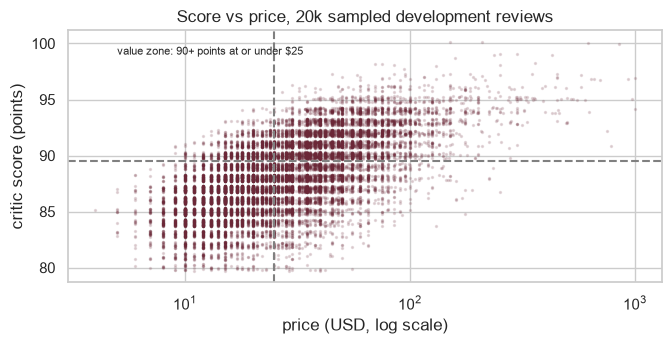

In [6]:
# Price vs score and how rare value wines are (development data only)
bands = pd.cut(dev["points"], [79, 84, 87, 90, 93, 100], labels=["80-84", "85-87", "88-90", "91-93", "94-100"])
display(dev.groupby(bands, observed=True).agg(reviews=("points", "size"), median_price=("price", "median"),
                                             p90_price=("price", lambda s: s.quantile(0.9))))
priced = dev[dev["price"].notna()]
under_cap = priced["price"] <= config.VALUE_MAX_PRICE
is_value = under_cap & (priced["points"] >= config.VALUE_MIN_POINTS)
print(f"Score: mean {dev['points'].mean():.1f}, SD {dev['points'].std():.1f}. "
      f"Corr(points, log price) = {np.corrcoef(priced['points'], np.log(priced['price']))[0, 1]:.2f}")
print(f"Wines at or under ${config.VALUE_MAX_PRICE:.0f}: {under_cap.mean():.1%} of priced reviews; "
      f"of those, {is_value[under_cap].mean():.1%} score {config.VALUE_MIN_POINTS}+ ('value wines')")

fig, ax = plt.subplots(figsize=(7, 3.6))
sample = priced.sample(20_000, random_state=config.SEED)
ax.scatter(sample["price"], sample["points"] + np.random.default_rng(0).uniform(-0.3, 0.3, len(sample)), s=2, alpha=0.15, color="#6b2737")
ax.set_xscale("log"); ax.axvline(config.VALUE_MAX_PRICE, ls="--", c="grey"); ax.axhline(config.VALUE_MIN_POINTS - 0.5, ls="--", c="grey")
ax.text(5, 99, "value zone: 90+ points at or under $25", fontsize=8)
ax.set(xlabel="price (USD, log scale)", ylabel="critic score (points)", title="Score vs price, 20k sampled development reviews")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "p1_score_vs_price.png", dpi=150); plt.show()

**What this shows (development data):**
- Price predicts quality only partly (correlation 0.63 with log price). Median prices go from $26 at 88–90 points to $74 at 94+, with a long tail of cheap wines in every band.
- About half of priced wines cost ≤ $25, and 15% of those score 90+. In the critic-fold candidate pools used for the simulations the rate is **17.6%**. (The 15% figure also includes anonymous reviews.)
- So a team sampling 100 of 1,000 candidates at random would find about **18 value wines**.

#### Business objectives
- **BO1, value shortlist:** rank each cycle's ~1,000 unscored ≤ $25 candidates so the ~100 samples contain as many 90+ wines as possible.
- **BO2, internal score estimate:** an *estimated score band* (e.g. "est. 88–91") for buyers' planning until a real review arrives. **Internal only:** never shown to customers as WineEnthusiast points (R10).
- **BO3, shelf navigation:** flavour profiles and descriptor–grape links for collection pages.
- **BO4, catalogue quality:** detect duplicate and near-duplicate listings; "similar wines".
- **BO5, critic calibration and buyer insights:** quantify how much a score depends on who tasted the wine, and which wine attributes go with value.

Out of scope: price setting, demand forecasting, personalised recommendations (no customer data).

#### Business success criteria (pre-registered; thresholds in `config.py`)
- Measured **once**, in Phase 5, on the lockbox critics. Simple rules are scored on the same data.
- **Pass rule:** the point estimate meets the target **and** the stated lower bound holds.
- **Lower bounds** are one-sided 90%, from 500 bootstrap resamples of **wineries** (wines from the same producer move together).
- Every target below is met by **every** development fold of the untuned feasibility models (see the per-fold table in 1.2).

| ID | Criterion | Target | Lower-bound condition | Weakest development fold |
|---|---|---|---|---|
| BSC1 | **Shortlist.** Expected precision@100 of the DM2 ranker over 200 simulated cycles of 1,000 ≤ $25 candidates | ≥ 0.55 **and** ≥ 1.4× the best rule in the frozen **simple-rule set** (`winevalue.rules`: price, winery track record, province track record, variety × country, winery then price; random ties), as measured on the lockbox | Top-10% lift vs that rule ≥ 1.2× | P@100 0.61; lift 1.56×; lift lower bound 1.43× |
| BSC2 | **Internal score band.** Share of ≤ $25 candidates whose price-free estimate is within ±2 points | ≥ 0.60 and ≥ +5 pp over variety × country | Gain lower bound > 0 | 0.63; +7.3 pp (lower bound +6.0) |
| BSC3 | **Navigation.** Flavour profiles | 6–15 profiles, each ≥ 1% of wines. Two independent reviewer agents (**not** the analyst), each blind to the other, can each name ≥ 80% of profiles from their top terms with confidence ≥ 3/5 | Top-10-term Jaccard ≥ 0.5 between profiles fitted on two halves of the development data | – (Phase 4) |
| BSC4 | **Usability.** One screen. Inputs: note, country, grape, vintage, price. Outputs: est. score band, P(90+), value verdict, flavour profile, 5 similar wines | All shown in the recorded demo, < 3 s per query | – | – |
| BSC5 | **Buyer insights.** Pre-registered hypotheses H1–H6 (`config.HYPOTHESES`) | **≥ 4 of 6** replicate, **including H5 or H6**: stated direction and condition met in **both** development and lockbox data | As stated per hypothesis | – (Phase 4/5) |

**Pre-registered hypotheses (BSC5):**
- *Sanity checks (strong in development data):*
  - **H1:** longer notes go with higher scores (LB > 0).
  - **H2:** within a variety × country group, pricier wines score higher (LB > 0).
  - **H3:** a named designation goes with higher scores (same variety × country; LB > 0).
- **H4:** critics differ. The SD of critic effects (vs a training-fitted variety × country expectation) exceeds 0.5 points, **LB > 0.5**. *Limitation:* the lockbox has only 4 critics.
- *Actionable:*
  - **H5:** among ≤ $25 wines, whites are more often value wines than reds (LB > 0). The colour map is frozen in Phase 3, before any lockbox use.
  - **H6:** among ≤ $25 wines, a strong winery track record (shrunk mean ≥ 89, shrink = 20) goes with a higher value-wine rate (LB > 0).

**Necessary, not sufficient.** These criteria use *critic* notes, but the real use is on importer, producer or staff notes (A1). Deployment therefore also needs a **pilot gate** on **≥ 400 ≤ $25 retailer notes** for wines that later receive a critic score. On those same pilot wines, it must beat the note-blind rules:
- ±2 accuracy ≥ +5 pp over variety × country, with a lower bound > 0;
- the ranker's top-20% precision for 90+ wines ≥ 1.3× the **best frozen simple rule**, with a lower bound > 1.0.

400 wines give about 80% power at fold-3-like effects; 100 would pass a good model only 39–67% of the time. (`config.PILOT_*`)

### 1.2 Assess situation

**CRISP-DM outputs:** Inventory of resources · Requirements, assumptions & constraints · Risks & contingencies · Terminology · Costs & benefits

#### Inventory of resources
| Type | Resource |
|---|---|
| Data | Wine Reviews (Kaggle, Zack Thoutt): 129,971 WineEnthusiast reviews, scraped June 2017, CC BY-NC-SA 4.0. One table; no sales, inventory or customer data |
| People | One analyst (the author). **The stakeholder is hypothetical**, so business parameters (A1–A7) are explicit assumptions with sensitivity checks. No sommelier or domain expert available. Reviewers: course instructor + an independent critic; independent reviewer agents for BSC3 |
| Compute / software | Laptop + Google Colab; Python 3.12, pandas, scikit-learn, LightGBM, mlxtend, datasketch, statsmodels, Streamlit (all open source) |

#### Requirements
- **R-1, prediction timing:** when a buyer considers a wine, **before any critic review exists**. Available then: note, country/province/region, grape, winery and its *past* scores, vintage, price.
- **R-2, inputs by use:**
  - The **score estimate** (BO2) and **value verdict** exclude `price`, so "quality vs price" isn't circular.
  - The **shortlist ranker** (BO1/DM2) may use price: it's known at decision time and is itself a benchmark rule.
  - Neither may use `taster_name` / `taster_twitter_handle`.
- **R-3, honest test:**
  - The lockbox is scored once.
  - Exact duplicates are removed.
  - Test reviews whose wine title also appears in training are dropped (124 of the 934 repeat titles span folds).
  - Anonymous notes that a style classifier attributes to a lockbox critic with p > 0.5 are dropped from training (859 rows; see the check below).
- **R-4, reproducibility:**
  - Fixed seeds.
  - Cycles and tie-breaks use separate RNG streams, so every rule is scored on identical cycles.
  - The simple-rule set and the masking list are frozen in `src/`.
  - The notebook runs top to bottom in Colab and is saved with outputs.
- **R-5, licence:** derived outputs are shared under CC BY-NC-SA 4.0 with attribution.

#### Assumptions
| # | Assumption | Testable? | Handling |
|---|---|---|---|
| A1 | Retailer notes carry similar descriptive signal to critic notes | **Not with this data.** Leave-critic-out tests new *critics*, not new *kinds* of writer (producers have an incentive to praise) | Masking proxy (DM1b) now; **relative pilot gate** before deployment |
| A2 | 90+ points is a meaningful value bar | No | Also reported at 88+ / 92+ |
| A3 | 2017 prices still rank wines sensibly relative to each other | No | Ranking use only; cap also tested at $20 / $30 |
| A4 | ~100 samples per cycle | No | Also k = 50 / 200 |
| A5 | ~$25 per sample (bottle + buyer time); ~2 analyst-hours per cycle to re-score | No | Illustrative economics |
| A6 | Scores are honest; whether tastings were blind is unknown | No | Critic calibration descriptive |
| A7 | **~1,000 unscored ≤ $25 candidates per cycle** (importer and distributor catalogues for a mid-size online retailer) | No | Sensitivity at 500 / 2,000 |

#### Constraints
One static 2017 snapshot, no review dates. Only 80+ wines are published. No stakeholder interviews. One analyst and an academic timeline (§1.4).

**Anonymous-review check (R-3, R8).** Could some anonymous training notes be written by lockbox critics? A style classifier uses note *text* and critic names only, no scores. The threshold is chosen from its held-out accuracy:

In [7]:
# Could some anonymous training reviews be written by lockbox critics? A writing-style check.
# Uses note TEXT and critic names only (no scores), so the lockbox seal on scores is kept.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import train_test_split
named_all = df[df["taster_name"].notna()]
tr_txt, te_txt = train_test_split(named_all, test_size=0.2, random_state=config.SEED, stratify=named_all["taster_name"])
vec = TfidfVectorizer(min_df=3, ngram_range=(1, 2), max_features=100_000, sublinear_tf=True).fit(tr_txt["description"])
clf = SGDClassifier(loss="log_loss", alpha=2e-6, max_iter=30, random_state=config.SEED).fit(vec.transform(tr_txt["description"]), tr_txt["taster_name"])
held = clf.predict_proba(vec.transform(te_txt["description"]))
held_ok = clf.classes_[held.argmax(1)] == te_txt["taster_name"].to_numpy()
anon = df[df["taster_name"].isna()]
proba = clf.predict_proba(vec.transform(anon["description"]))
top_p, top_critic = proba.max(axis=1), clf.classes_[proba.argmax(axis=1)]
lockbox_critics = [c for c, f in mapping.items() if f == config.LOCKBOX_FOLD]   # raw spellings, as the classifier sees them
assert sorted(_norm_name(pd.Series(lockbox_critics))) == config.LOCKBOX_CRITICS
sens = pd.DataFrame([{"threshold": t,
                      "accuracy on held-out named notes above threshold": held_ok[held.max(1) > t].mean(),
                      "anonymous notes above threshold": int((top_p > t).sum()),
                      "of which attributed to a lockbox critic": int(((top_p > t) & np.isin(top_critic, lockbox_critics)).sum())}
                     for t in (0.5, 0.7, 0.9)]).set_index("threshold")
display(sens.round(3))
ANON_LOCKBOX_LIKE = anon.index[(top_p > config.ATTRIBUTION_THRESHOLD) & np.isin(top_critic, lockbox_critics)]
print(f"Overall held-out accuracy {held_ok.mean():.1%}. Rows dropped from training in Phase 3 (p > {config.ATTRIBUTION_THRESHOLD}): "
      f"{len(ANON_LOCKBOX_LIKE):,} ({len(ANON_LOCKBOX_LIKE) / len(anon):.1%} of anonymous notes)")

,accuracy on held-out named notes above threshold,anonymous notes above threshold,of which attributed to a lockbox critic
threshold,,,
0.5,0.992,11872,859
0.7,0.998,4418,329
0.9,1.000,341,29


Overall held-out accuracy 98.4%. Rows dropped from training in Phase 3 (p > 0.5): 859 (3.4% of anonymous notes)


At p > 0.5 the classifier is still **99.2%** accurate on held-out named notes. Dropping the 859 anonymous notes it assigns to lockbox critics costs only 3.4% of anonymous training data, so 0.5 is used (`config.ATTRIBUTION_THRESHOLD`).

#### Risks & contingencies
| # | Risk | Likelihood | Impact | Contingency |
|---|---|---|---|---|
| R1 | **Note-source shift** (A1) | High | High | Masking test (DM1b); relative pilot gate; BSCs "necessary, not sufficient" |
| R2 | **Region confound:** holding out critics also holds out regions (variety × country coverage 29–87% by development fold), so the variety × country baseline looks weaker than on a random split | Confirmed | Medium | Both splits reported; targets set on the critic split; per-fold and per-critic results |
| R3 | **Duplicates / repeat titles:** 9,983 dups; 1,148 repeat reviews of 934 titles; 124 titles span folds | Confirmed | High if ignored | Dups removed; test rows with a training title dropped |
| R4 | **Selection bias:** only 80+ wines are published | Confirmed | Medium | Stated limitation |
| R5 | **Stale prices**, single snapshot | Confirmed | Low–Medium | Ranking use only; cap sensitivity |
| R6 | **Critic differences** for the same variety and country | Observed (descriptive) | Medium | H4 / DM6; the lockbox mixes 4 critics |
| R7 | **Long-tail categories:** 707 grapes, 16,757 wineries | Confirmed | Medium | Rare-category grouping (Phase 3) |
| R8 | **Anonymous notes by lockbox critics** | Small | Low | 859 rows (p > 0.5) dropped from training |
| R9 | **Weak lockbox result.** Development margins are smallest for fold 3 (the fold most like the lockbox) on DM1/BSC2, and for folds 1 and 4 on BSC1 | Medium | Medium | Every target is met by every development fold; winery-clustered lower bounds; per-critic reporting |
| R10 | **Misleading or infringing display** of estimated "points" | Medium | Medium | Internal "estimated band" only, labelled |
| R11 | **One critic dominates the lockbox** (O'Keefe: 50% of the ≤ $25 pool) | Confirmed | Medium | Per-critic top-10% precision; results reported with and without O'Keefe |
| R12 | **Licence (NC-SA)** limits commercial use | Confirmed | Low (academic) | Stated in README and app |

#### Terminology
**Critic score / points:** WineEnthusiast's 80–100 rating · **Value wine:** 90+ points at ≤ $25 · **Tasting note:** the `description` · **Candidate pool / cycle:** unscored ≤ $25 wines considered in one buying round (A7) · **Shortlist:** the top k to sample · **Precision@k / top-10% precision:** share of a shortlist that are value wines · **Simple-rule set:** the frozen non-ML rankings in `winevalue.rules` · **Lift:** ranker precision ÷ best simple-rule precision · **MAE:** mean absolute error · **Within ±2:** share of estimates within 2 points · **Critic fold / lockbox:** a held-out group of critics / the fold sealed until Phase 5 · **Lower bound (LB):** one-sided 90% winery-clustered bootstrap bound · **Evaluative language:** words and phrases that state a verdict or drinking window (`config.EVALUATIVE_TERMS`, `EVALUATIVE_PATTERNS`) · **TF-IDF:** word weighting for notes · **Flavour profile:** a cluster of similar notes · **Support / confidence / lift (rules):** association-rule statistics · **MinHash LSH:** fast near-duplicate search.

#### Costs & benefits
**Feasibility check.** Development folds only; untuned models; test rows with a training title dropped. Shortlists are scored over 200 simulated cycles (cycles and ties on separate RNG streams, one tie stream per rule); lower bounds use a winery-clustered bootstrap. Training here uses all anonymous rows: the R-3 attribution filter (859 rows, none of them lockbox rows) starts in Phase 3.

In [8]:
# Feasibility on development folds (lockbox untouched). Untuned models; each critic fold held out in turn;
# test rows whose title appears in training are dropped (R-3). Uncertainty: one-sided 90%, winery-clustered bootstrap.
from winevalue.models import GroupMeanBaseline, quick_text_model, mask_terms, mask_evaluative, QUALITY_INPUTS, RANKER_INPUTS
from winevalue.metrics import mae, within, cluster_bootstrap
from winevalue.rules import SIMPLE_RULES, simple_rule_scores
from winevalue.splits import drop_titles_seen_in_training
from winevalue.value import simulate_cycles, cluster_bootstrap_lift, precision_top_frac

K, N_CAND = config.SHORTLIST_K, config.CANDIDATES_PER_CYCLE
RANKER = "DM2 ranker (text + price)"
cv_folds = sorted(f for f in dev["fold"].unique() if f >= 0)
score_rows, fold_rows, shelf_rows, pools = [], [], [], {}
for f in cv_folds:
    tr = dev[dev["fold"] != f]
    te = drop_titles_seen_in_training(dev[dev["fold"] == f], tr)
    y = te["points"].to_numpy()
    fit_pred = lambda train, test: quick_text_model().fit(train[QUALITY_INPUTS], train["points"]).predict(test[QUALITY_INPUTS])
    preds = {"global mean": np.full(len(te), tr["points"].mean()),
             "variety × country": GroupMeanBaseline().fit(tr, tr["points"]).predict(te),
             "text model": fit_pred(tr, te)}
    for label, masker in [("masked, round-1 list", lambda s: mask_terms(s, config.EVALUATIVE_TERMS_V1)),
                          ("masked, frozen list", mask_evaluative)]:
        preds[f"text model, {label}"] = fit_pred(tr.assign(description=masker(tr["description"])),
                                                 te.assign(description=masker(te["description"])))
    cand = (te["price"] <= config.VALUE_MAX_PRICE).to_numpy()
    for name, p in preds.items():
        score_rows.append({"fold": f, "predictor": name, "MAE": mae(y, p), "within ±2 (≤$25)": within(y[cand], p[cand])})

    vc, tm, wineries = preds["variety × country"], preds["text model"], te["winery"].to_numpy()
    red = cluster_bootstrap(lambda i: 1 - mae(y[i], tm[i]) / mae(y[i], vc[i]), wineries, seed=config.SEED)
    c_idx = np.flatnonzero(cand)
    gain = cluster_bootstrap(lambda i: within(y[c_idx][i], tm[c_idx][i]) - within(y[c_idx][i], vc[c_idx][i]),
                             wineries[c_idx], seed=config.SEED)

    pool = te[cand]
    is_val = (pool["points"] >= config.VALUE_MIN_POINTS).to_numpy()
    rules = simple_rule_scores(tr, pool)
    rules["text model (no price)"] = tm[cand]
    rules[RANKER] = quick_text_model(with_price=True).fit(tr[RANKER_INPUTS], tr["points"]).predict(pool[RANKER_INPUTS])
    pools[f] = (pool, is_val, rules)
    res = {n: simulate_cycles(rules, is_val, n_candidates=n, k=K, n_cycles=config.N_SIM_CYCLES, seed=config.SEED + f)
           for n in (500, N_CAND, 2000)}
    for n, r in res.items():
        shelf_rows.append({"fold": f, "candidates per cycle": n, "value base rate": is_val.mean(), **r.mean().to_dict()})
    best = max(SIMPLE_RULES, key=lambda r: res[N_CAND][r].mean())
    lift = cluster_bootstrap_lift(rules[RANKER], rules[best], is_val, pool["winery"], frac=0.1, seed=config.SEED)
    fold_rows.append({
        "fold": f, "≤$25 pool": len(pool),
        "MAE reduction vs v×c": red["estimate"], "MAE reduction 90% LB": red["lower_bound"],
        "within ±2 gain (pp)": 100 * gain["estimate"], "within ±2 gain 90% LB (pp)": 100 * gain["lower_bound"],
        "best simple rule": best, "best simple P@100": res[N_CAND][best].mean(),
        "ranker P@100": res[N_CAND][RANKER].mean(), "lift (cycles)": res[N_CAND][RANKER].mean() / res[N_CAND][best].mean(),
        "lift top-10% (bootstrap point)": lift["lift"], "lift 90% LB": lift["lower_bound"],
    })

scores = pd.DataFrame(score_rows)
score_table = scores.pivot_table(index="predictor", columns="fold", values=["MAE", "within ±2 (≤$25)"])
for m in ("MAE", "within ±2 (≤$25)"):
    score_table[(m, "mean")] = score_table[m].mean(axis=1)
display(score_table.sort_index(axis=1).round(3))
mae_by = scores.pivot(index="fold", columns="predictor", values="MAE")
masking = pd.DataFrame({
    "MAE increase, round-1 list": mae_by["text model, masked, round-1 list"] - mae_by["text model"],
    "MAE increase, frozen list": mae_by["text model, masked, frozen list"] - mae_by["text model"],
    "improvement kept, frozen list": (mae_by["variety × country"] - mae_by["text model, masked, frozen list"])
                                     / (mae_by["variety × country"] - mae_by["text model"])})
masking.loc["mean"] = masking.mean()
display(masking.round(3))
per_fold = pd.DataFrame(fold_rows).set_index("fold")
display(per_fold.round(3))
shelf = pd.DataFrame(shelf_rows)
display(shelf.groupby("candidates per cycle")[["value base rate", *SIMPLE_RULES, "text model (no price)", RANKER]].mean().T.round(3))

MAE                              \
fold                                  0      1      3      4   mean   
predictor                                                             
global mean                       2.561  2.761  2.333  2.584  2.560   
text model                        1.829  1.746  2.001  1.721  1.824   
text model, masked, frozen list   1.925  1.852  2.067  1.750  1.899   
text model, masked, round-1 list  1.886  1.791  2.059  1.740  1.869   
variety × country                 2.716  2.616  2.271  2.515  2.529   

                                 within ±2 (≤$25)                              
fold                                            0      1      3      4   mean  
predictor                                                                      
global mean                                 0.490  0.420  0.580  0.534  0.506  
text model                                  0.711  0.700  0.628  0.717  0.689  
text model, masked, frozen list             0.705  0.689  0.616  0.694  0.676  
text model, masked, round-1 list            0.711  0.690  0.614  0.705  0.680  
variety × country                           0.549  0.475  0.555  0.540  0.530

,"MAE increase, round-1 list","MAE increase, frozen list","improvement kept, frozen list"
fold,,,
0,0.058,0.096,0.892
1,0.045,0.106,0.878
3,0.058,0.066,0.756
4,0.019,0.029,0.964
mean,0.045,0.074,0.872


,≤$25 pool,MAE reduction vs v×c,MAE reduction 90% LB,within ±2 gain (pp),within ±2 gain 90% LB (pp),best simple rule,best simple P@100,ranker P@100,lift (cycles),lift top-10% (bootstrap point),lift 90% LB
fold,,,,,,,,,,,
0,10794,0.327,0.315,16.268,15.203,price (pricier first),0.418,0.662,1.581,1.625,1.496
1,12659,0.332,0.323,22.443,21.377,price (pricier first),0.340,0.608,1.789,1.788,1.696
3,9032,0.119,0.105,7.263,5.998,"winery track record, then price",0.337,0.717,2.129,2.105,1.921
4,6137,0.316,0.308,17.777,16.588,"winery track record, then price",0.395,0.618,1.563,1.557,1.426


candidates per cycle,500,1000,2000
value base rate,0.176,0.176,0.176
price (pricier first),0.340,0.363,0.371
winery track record,0.224,0.260,0.305
province track record,0.181,0.166,0.140
variety × country,0.183,0.181,0.174
"winery track record, then price",0.325,0.361,0.371
text model (no price),0.489,0.603,0.699
DM2 ranker (text + price),0.517,0.651,0.759


**Is the weak baseline an artefact of the critic split?** Compare with a random, title-grouped split of the same development data:

In [9]:
# How much of the baseline's weakness comes from the critic split itself? Same comparison on a
# random split of the development data, grouped by title so no wine is on both sides.
from sklearn.model_selection import GroupShuffleSplit
tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=config.SEED).split(dev, groups=dev["title"]))
tr, te = dev.iloc[tr_i], dev.iloc[te_i]
y = te["points"].to_numpy()
rnd = {"global mean": mae(y, np.full(len(te), tr["points"].mean())),
       "variety × country": mae(y, GroupMeanBaseline().fit(tr, tr["points"]).predict(te)),
       "text model": mae(y, quick_text_model().fit(tr[QUALITY_INPUTS], tr["points"]).predict(te[QUALITY_INPUTS]))}
crit = scores.groupby("predictor")["MAE"].mean()
display(pd.DataFrame({"random split (title-grouped)": rnd,
                      "critic split (mean of 4 folds)": crit.reindex(list(rnd))}).round(3))

,random split (title-grouped),critic split (mean of 4 folds)
global mean,2.600,2.560
variety × country,2.390,2.529
text model,1.301,1.824


**Feasibility verdict (all figures from the tables above):**
- **Score estimate.** For unseen critics, the text model cuts MAE by **12–33%** vs variety × country (mean 27%; fold 3 lowest at 12%, lower bound 10.5%). ±2 accuracy on ≤ $25 candidates is 0.63–0.72, a gain of +7.3 to +22.4 pp over variety × country.
- **Not just verdict words.** With the frozen evaluative list masked (verdict words + drinking windows), MAE rises by only **0.03–0.11 points**, and **87%** of the improvement is kept on average (76% in fold 3). The narrower round-1 list kept 91%.
- **The baseline's weakness is partly the split.** On a random title-grouped split, variety × country beats the global mean by about 8% (2.39 vs 2.60); on the critic split, by about 1%. New writers in partly new regions are genuinely harder.
- **Shortlist** (cycles of 1,000):
  - The best simple rule is *price* (folds 0–1) or *winery track record, then price* (folds 3–4), at 0.34–0.42.
  - The **DM2 ranker reaches 0.61–0.72**, a lift of 1.56–2.13× (lower bounds 1.43–1.92×).
  - Precision rises with pool size: 0.52 / 0.65 / 0.76 for 500 / 1,000 / 2,000 candidates.
- **Targets:** every pre-registered target (BSC1, BSC2, DM1, DM1b) is met by **every** development fold, including its lower-bound condition.
- *Disclosure:* one exploratory check, run before the lockbox existed, used all critics. All figures here use development data only.

In [10]:
# Sampling economics per buying cycle (A4 = 100 samples, A5 = $25/sample, A7 = 1,000 candidates). Development folds.
COST_PER_SAMPLE, ANALYST_COST, RUNNING_COST_PER_CYCLE = 25.0, 70 * 50.0, 2 * 50.0   # 2 analyst-hours to re-score each cycle
ks = list(range(10, K + 1, 2))
finds = {}   # expected value wines found among the top-k, averaged over folds and cycles
for f, (pool, is_val, rules) in pools.items():
    for k in ks:
        r = simulate_cycles({"random": np.zeros(len(pool)), "best simple": rules[per_fold.loc[f, "best simple rule"]], RANKER: rules[RANKER]},
                            is_val, n_candidates=N_CAND, k=k, n_cycles=50, seed=config.SEED + f)
        for name in r:
            finds.setdefault((name, k), []).append(k * r[name].mean())
finds = pd.Series({key: np.mean(v) for key, v in finds.items()}).unstack(0)
at100 = finds.loc[K]
econ = pd.DataFrame({"value wines found in 100 samples": at100, "precision@100": at100 / K,
                     "sampling cost per value wine": COST_PER_SAMPLE * K / at100}).loc[["random", "best simple", RANKER]]
display(econ.round(2))
need = finds.index[(finds[RANKER] >= at100["best simple"]).to_numpy()].min()
opportunity = (at100[RANKER] - at100["best simple"]) * econ.loc["best simple", "sampling cost per value wine"]
cash = (K - need) * COST_PER_SAMPLE
print(f"Opportunity value: +{at100[RANKER] - at100['best simple']:.1f} value wines per cycle ≈ ${opportunity:,.0f} at the best simple rule's cost per find")
print(f"Cash framing: the ranker matches the best rule's {at100['best simple']:.1f} finds with ≈ {need} samples instead of {K}, "
      f"saving ≈ ${cash:,.0f} per cycle; net of ${RUNNING_COST_PER_CYCLE:.0f} running cost ≈ ${cash - RUNNING_COST_PER_CYCLE:,.0f}")
print(f"Break-even on ≈ ${ANALYST_COST:,.0f} of analyst time: {ANALYST_COST / (cash - RUNNING_COST_PER_CYCLE):.1f} cycles (cash), "
      f"{ANALYST_COST / (opportunity - RUNNING_COST_PER_CYCLE):.1f} cycles (opportunity value)")

,value wines found in 100 samples,precision@100,sampling cost per value wine
random,17.13,0.17,145.94
best simple,37.16,0.37,67.27
DM2 ranker (text + price),65.41,0.65,38.22


Opportunity value: +28.2 value wines per cycle ≈ $1,900 at the best simple rule's cost per find
Cash framing: the ranker matches the best rule's 37.2 finds with ≈ 50 samples instead of 100, saving ≈ $1,250 per cycle; net of $100 running cost ≈ $1,150
Break-even on ≈ $3,500 of analyst time: 3.0 cycles (cash), 1.9 cycles (opportunity value)


In [11]:
# Do critics score differently for the same variety and country? (development data; descriptive only,
# because critics also differ in which wines they review within a variety × country)
named = dev[dev["taster_name"].notna()]
resid = named["points"] - GroupMeanBaseline().fit(dev, dev["points"]).predict(named)
critic_bias = (pd.DataFrame({"critic": named["taster_name"], "score": named["points"], "vs_expected": resid})
                 .groupby("critic").agg(reviews=("score", "size"), mean_score=("score", "mean"),
                                        mean_vs_variety_country=("vs_expected", "mean"))
                 .query("reviews >= 100").sort_values("mean_vs_variety_country"))
display(critic_bias.round(2))
print(f"Range of critic averages vs variety × country expectation: "
      f"{critic_bias['mean_vs_variety_country'].min():+.2f} to {critic_bias['mean_vs_variety_country'].max():+.2f} points")

,reviews,mean_score,mean_vs_variety_country
critic,,,
Alexander Peartree,383,85.78,-2.30
Carrie Dykes,129,86.36,-1.64
Susan Kostrzewa,1023,86.58,-1.36
Lauren Buzzeo,1700,87.69,-0.48
Anna Lee C. Iijima,4017,88.42,-0.39
Michael Schachner,14046,86.86,-0.24
Joe Czerwinski,4766,88.52,-0.03
Roger Voss,23560,88.73,0.05
Jim Gordon,3766,88.60,0.33


Range of critic averages vs variety × country expectation: -2.30 to +1.35 points


**Benefits (conditional on A4, A5, A7):**

| Framing | Per cycle | Break-even on ~$3,500 of analyst time |
|---|---|---|
| **Cash** (sampling spend the ranker saves while finding as many value wines as the best simple rule) | ≈ 50 instead of 100 samples → ≈ $1,250, ≈ $1,150 after $100 running cost | ≈ 3 cycles |
| **Opportunity value** (sampling all 100 anyway) | ≈ +28 value wines, worth ≈ $1,900 at the simple rule's cost per find | ≈ 2 cycles |

- **Revenue upside:** a fuller value collection is probably worth more, but can't be quantified without sales data, so it isn't claimed.
- **Other benefits:** internal score bands (BO2), navigation (BO3), catalogue hygiene (BO4).

**Critic differences (descriptive).** For the *same variety and country*, critics' average scores range from −2.30 to +1.35 points vs expectation. Critics also differ in which wines they review, so H4 and DM6 test this properly.

**Costs:**
- About 60–80 analyst-hours (≈ $3,500 at an assumed $50/h); open-source software; free hosting.
- About 2 analyst-hours per cycle to re-score, plus a quarterly drift check.
- A pilot on about 100 retailer notes.

### 1.3 Determine data mining goals

**CRISP-DM outputs:** Data mining goals · Data mining success criteria

| ID | Data mining goal | Technique | Success criterion (lockbox, Phase 5; DM5 on the full corpus) | Uncertainty | Supports |
|---|---|---|---|---|---|
| DM1 | **Estimate the critic score** from note + origin + grape + vintage (no price, no critic) | Baselines vs ridge on TF-IDF, gradient boosting, optional transformer embeddings | MAE ≥ 10% below variety × country; plus BSC2 | Lower bound of the reduction > 5% | BO2 |
| DM1b | **Signal beyond verdict words** | Same model with the frozen evaluative list masked | Masked-model MAE ≤ DM1 MAE + 0.15 points (absolute, so it's stable even when DM1's reduction is small) | Point estimate | BO1, BO2 (A1 proxy) |
| DM2 | **Rank ≤ $25 candidates** | DM1 model + log price (or a direct P(90+) classifier) | = BSC1. Also reported at k = 50/200 and pools of 500/2,000 | = BSC1 | BO1 |
| DM3 | **Flavour profiles** | k-means / NMF on TF-IDF or embeddings; outlier notes checked | = BSC3. Silhouette or topic coherence reported | = BSC3 | BO3 |
| DM4 | **Descriptor ↔ grape links** | FP-Growth on descriptor sets + grape | ≥ 10 rules with lift ≥ 2 and support ≥ 0.5% in development data that keep lift ≥ 1.5 in the lockbox | Point estimate | BO3, BO5 |
| DM5 | **Near-duplicates and similar wines** | MinHash LSH on 5-word shingles (128 permutations): loose candidate stage (threshold 0.3), then **exact Jaccard verification ≥ τ = 0.5** (`winevalue.similarity`) | *Re-specified 2026-11-04 (Phase 2 → Phase 1 loop-back); made operational in Phase 3 (revision 2, same day); text only, no scores. *Timeline (critic round 2):* (c) was first run during Phase 3 critic round 1 (0.81 < 0.90); it was demoted to exploratory and the content-word rule amended **after** that run; the result was unchanged (35/43). (a) was not run. Original, superseded: ~~recall ≥ 0.9 of exact-Jaccard ≥ 0.8 pairs on a 10k sample; precision ≥ 0.9 on 100 hand-checked pairs~~.* **Corpus:** distinct notes after exact de-duplication, barrel-sample and duplicated-note removal (`prepare(..., stop_before="near_duplicates")`; 119,280 notes). **Pass/fail: (a) recall ≥ 0.90** (a check of the implementation, not of the data: with 37 bands × 3 rows, P(candidate | J = 0.5) = 0.993) on synthetic positives (`similarity.synthetic_copies`: 2,000 notes, seed 42; edit rate ~ U(0.02, 0.08); k = round(rate·words) positions replaced by corpus tokens; positives = copies with exact J ≥ 0.5; 1,694 at seed 42). **Reported, not pass/fail:** (b) candidate share (≤ 0.01% target; it can't fail: 1.7e-7 measured, so it's an engineering check); (c) precision under `similarity.is_true_duplicate` (same wine relisted, or recycled/mis-attached note with ≤ 3 differing content words). (c) is **exploratory**, because the 43 real pairs were inspected in Phase 2; it's 35/43 = 0.81 and is reported without re-tuning. Parameters in `config.DM5_*` | Point estimate | BO4 |
| DM6 | **Critic calibration** | Fixed / mixed effects: score ~ wine attributes + critic | Critic effects with 95% CIs; feeds H4 / BSC5 | As BSC5 | BO5 |

**Outlier analysis** (course template) is a supporting step in Phases 2–3: price outliers (up to $3,300), odd vintages, unusually short or long notes.

### 1.4 Produce project plan

**CRISP-DM outputs:** Project plan · Initial assessment of tools & techniques

Dates assume work started 2026-11-03. `instructions.txt` gives no due date. **The assignment due date still needs confirming with the project owner**, and the dates will be adjusted to fit it.

| Phase | Planned dates | Effort | Inputs → outputs | Milestone / go-no-go |
|---|---|---|---|---|
| 1 Business Understanding | Nov 3–4 | 10% | Raw data → §1; frozen evaluation design, rules, targets, hypotheses | Critic: no major issues |
| 2 Data Understanding | Nov 4–6 | 20% | §1 → description, EDA, quality report (**development data only** for score analysis) | Quality issues logged |
| 3 Data Preparation | Nov 6–9 | 25% | §2 → cleaned table, R-3 filters, features (incl. wine colour for H5), text pipeline | Leakage audit passes |
| 4 Modeling | Nov 9–12 | 20% | §3 → DM1–DM6 on development folds | DM targets met in CV, or loop back to 3 |
| *Buffer* | Nov 13 | – | Absorbs one loop-back (Phase 4 → 3) | – |
| 5 Evaluation | Nov 14 | 10% | §4 → single lockbox run, BSC1–BSC5 | Go/no-go |
| 6 Deployment | Nov 15–17 | 15% | §5 → Value Finder app, monitoring, pilot plan, report, article, video | Final critic review |

**Fallback scope:** if time runs short, DM5 (LSH) and DM6 (critic model) shrink to a minimal demonstration. DM1, DM1b, DM2 and DM3 are protected.

**Resources:** one analyst for every phase, plus an independent critic review (≥ 2 rounds) at the end of each.

**Initial assessment of tools & techniques:**
- **scikit-learn:** TF-IDF, ridge, k-means, NMF; pipelines fit inside each fold.
- **LightGBM:** non-linear models.
- **mlxtend:** FP-Growth.
- **datasketch:** MinHash LSH.
- **statsmodels:** critic effects with CIs.
- **Streamlit:** the app.
- **IBM SPSS Modeler** (suggested in the assignment) has a CRISP-DM project view, but needs a licence, handles free text poorly and can't be shared as a runnable notebook, so the structure is followed in this notebook and report instead.

> **Critic review: Phase 1.** The revisions are logged in `critiques/phase1_business_understanding_round*.md`.
> The phase is finished when every output above is filled in and the latest critic round lists no major issues.

---
# Phase 2 · Data Understanding

> **Revision 3**, after critic rounds 1 (6/10) and 2 (7.5/10); see `critiques/phase2_data_understanding_round*.md`. Main changes:
> - a **target leak** was found (score ranges written into 671 barrel-sample notes);
> - the vintage rule is corrected;
> - the human noise floor is redone properly (pairwise, same wine, √2);
> - grape synonyms and a colour map are frozen;
> - near-duplicates are explored, which led to a DM5 loop-back to Phase 1;
> - many identity and encoding checks are added.

*Rule from Phase 1: anything that looks at **scores** uses development data (`dev`) only. Counts, categories and text structure may use all reviews.*

### 2.1 Collect initial data

**CRISP-DM output:** Initial data collection report

In [12]:
# 2.1 Collect initial data: what was downloaded, what is used, and is it the file we think it is?
import hashlib, gzip
sha = hashlib.sha256(gzip.open(config.DATA_RAW, "rb").read()).hexdigest()
print(f"winemag-data-130k-v2.csv SHA-256 {sha[:16]}…  matches data/README.md: {sha == '52af2643c8ac29f010f0cc629dfbdda1c74aa0f332d11762af9ef3de4e567ac9'}")
older = PROJECT_DIR.parent / "data" / "wine" / "winemag-data_first150k.csv"     # local only (git-ignored)
if older.exists():
    f150 = pd.read_csv(older, index_col=0)
    print(f"first150k: {f150.shape[0]:,} rows, columns = {list(f150.columns)}; exact duplicates {f150.duplicated().sum():,}; "
          f"{df['description'].isin(set(f150['description'])).mean():.0%} of our reviews also appear there")
else:
    print("first150k not available here (Colab); see report 2.1 for the comparison")

winemag-data-130k-v2.csv SHA-256 52af2643c8ac29f0…  matches data/README.md: True


first150k: 150,930 rows, columns = ['country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'variety', 'winery']; exact duplicates 53,079; 40% of our reviews also appear there


**Initial data collection report:**

| Item | Detail |
|---|---|
| Source | Kaggle *Wine Reviews* (Zack Thoutt), downloaded by the project owner. Reviews scraped from WineEnthusiast.com, week of 2017-06-15 |
| Licence | CC BY-NC-SA 4.0; derived outputs use the same licence |
| Files received | `winemag-data-130k-v2.csv` (129,971 × 13) · `winemag-data-130k-v2.json` (the same reviews as JSON, per the dataset page) · `winemag-data_first150k.csv` (older scrape: 150,930 rows, **no critic names**, 53,079 exact duplicates, ~40% of our notes also appear there, matched on note text) |
| Used | **`winemag-data-130k-v2.csv` only.** It's the only file with critic names, which the critic-fold evaluation needs. SHA-256 verified above |
| Not used, and why | JSON: redundant. 150k: no critics, and mixing scrapes would double-count reviews |
| Missing data that would help | Review dates, sales or price history, the retailer's own notes (needed for the A1 pilot), whether tastings were blind |
| Access problems | None. Content issues are in 2.4 |

### 2.2 Describe data

**CRISP-DM output:** Data description report

In [13]:
# 2.2 Describe data: one row per column, with the role it may play (Phase 1, R-1/R-2)
roles = {"country": "input", "description": "input (text)", "designation": "input", "points": "TARGET",
         "price": "ranker input only / value verdict (R-2)", "province": "input", "region_1": "input", "region_2": "input (US only)",
         "taster_name": "EXCLUDED (R-2) / grouping for folds", "taster_twitter_handle": "EXCLUDED (R-2)",
         "title": "source of vintage; repeat-title key", "variety": "input", "winery": "input (track record)"}
desc = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non-null": raw.notna().mean().map("{:.1%}".format),
    "distinct": raw.nunique(),
    "example": raw.iloc[1].astype(str).str[:40],
    "role": pd.Series(roles),
})
display(desc)
words = df["description"].str.split().str.len()
print(f"tasting notes: {words.min()}–{words.max()} words (median {words.median():.0f}); "
      f"{df['description'].str.len().max()} characters at most")
tail = pd.DataFrame({c: {"categories": df[c].nunique(),
                         "share of reviews in top 10": df[c].value_counts().head(10).sum() / df[c].notna().sum(),
                         "categories with < 20 reviews": int((df[c].value_counts() < 20).sum()),
                         "reviews in those categories": int(df[c].value_counts()[lambda s: s < 20].sum())}
                     for c in ["country", "province", "variety", "winery"]}).T
display(tail.round(3))

,dtype,non-null,distinct,example,role
country,str,100.0%,43,Portugal,input
description,str,100.0%,119955,"This is ripe and fruity, a wine that is",input (text)
designation,str,71.2%,37979,Avidagos,input
points,int64,100.0%,21,87,TARGET
price,float64,93.1%,390,15.0,ranker input only / value verdict (R-2)
province,str,100.0%,425,Douro,input
region_1,str,83.7%,1229,NaN,input
region_2,str,38.9%,17,NaN,input (US only)
taster_name,str,79.8%,19,Roger Voss,EXCLUDED (R-2) / grouping for folds
taster_twitter_handle,str,76.0%,15,@vossroger,EXCLUDED (R-2)


tasting notes: 3–135 words (median 40); 829 characters at most


,categories,share of reviews in top 10,categories with < 20 reviews,reviews in those categories
country,43.0,0.960,14.0,96.0
province,425.0,0.615,264.0,1526.0
variety,707.0,0.550,501.0,2370.0
winery,16757.0,0.015,15341.0,66756.0


**Data description report:**
- **Grain:** one row per published review. Non-null and distinct counts above are on the raw file; everything else is on the 119,988 unique reviews.
- **Target, `points`:** integers 80–100 (only 80+ wines are published).
- **Text, `description`:** every review has a note, 3–135 words (median 40).
- **Long tails:** the top 10 countries cover 96%; 501 of 707 variety labels have fewer than 20 reviews; **15,341 of 16,757 wineries have fewer than 20 reviews, covering 56% of reviews**, so a winery track record is unavailable for most wines.
- **Price:** labelled USD in the data source (not independently verified), missing for 7%.
- **Vintage:** parsed from `title`. Roles follow Phase 1's R-1/R-2.

### 2.3 Explore data

**CRISP-DM output:** Data exploration report

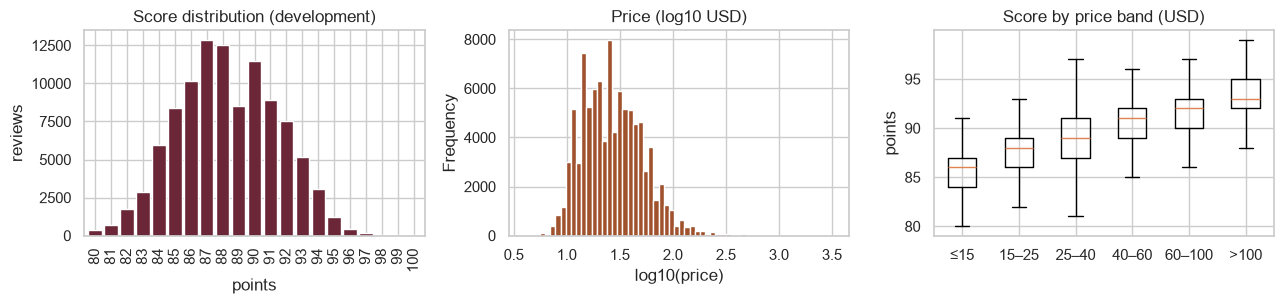

points: mean 88.32, median 88, SD 3.16, share 90+ 37.3%, share ≥95 1.92%, integer-valued: True
price: median $25, 90th pct $65, 99th $160, max $3,300


In [14]:
# 2.3a Scores and prices (development data only)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
dev["points"].value_counts().sort_index().plot.bar(ax=ax[0], color="#6b2737", width=0.85)
ax[0].set(title="Score distribution (development)", xlabel="points", ylabel="reviews")
np.log10(dev["price"].dropna()).plot.hist(ax=ax[1], bins=60, color="#a0522d")
ax[1].set(title="Price (log10 USD)", xlabel="log10(price)")
bands = pd.cut(dev["price"], [0, 15, 25, 40, 60, 100, 4000], labels=["≤15", "15–25", "25–40", "40–60", "60–100", ">100"])
ax[2].boxplot([dev.loc[bands == b, "points"] for b in bands.cat.categories], tick_labels=list(bands.cat.categories), showfliers=False)
ax[2].set(title="Score by price band (USD)", ylabel="points")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "p2_scores_prices.png", dpi=150); plt.show()
print(f"points: mean {dev.points.mean():.2f}, median {dev.points.median():.0f}, SD {dev.points.std():.2f}, "
      f"share 90+ {(dev.points >= 90).mean():.1%}, share ≥95 {(dev.points >= 95).mean():.2%}, integer-valued: {np.all(dev.points % 1 == 0)}")
print(f"price: median ${dev.price.median():.0f}, 90th pct ${dev.price.quantile(.9):.0f}, 99th ${dev.price.quantile(.99):.0f}, max ${dev.price.max():,.0f}")

In [15]:
# 2.3b Where are the value wines? (≤ $25 candidates, development data, groups with ≥ 300 candidates)
cand = dev[dev["price"] <= config.VALUE_MAX_PRICE].assign(value=lambda t: t["points"] >= config.VALUE_MIN_POINTS)
def value_table(col, min_n=300):
    t = cand.groupby(col).agg(candidates=("value", "size"), value_rate=("value", "mean"), median_price=("price", "median"))
    return t[t.candidates >= min_n].sort_values("value_rate", ascending=False)
print(f"overall value rate among ≤ $25 candidates: {cand.value.mean():.1%} ({len(cand):,} candidates)")
display(value_table("country").round(3))
vt = value_table("variety"); display(pd.concat([vt.head(6), vt.tail(4)]).round(3))

overall value rate among ≤ $25 candidates: 15.0% (49,097 candidates)


,candidates,value_rate,median_price
country,,,
Germany,930,0.303,17.0
Portugal,3274,0.210,14.0
Australia,1320,0.208,17.0
New Zealand,819,0.200,18.0
US,18227,0.179,18.0
Austria,415,0.173,19.0
France,8247,0.168,17.0
Greece,322,0.168,17.0
South Africa,845,0.114,15.0


,candidates,value_rate,median_price
variety,,,
Riesling,2284,0.278,17.0
Gamay,642,0.273,18.0
Portuguese Red,1460,0.270,14.0
Shiraz,423,0.270,17.0
Pinot Gris,813,0.262,18.0
Syrah,981,0.215,20.0
Merlot,1514,0.081,16.0
Tempranillo,943,0.070,15.0
Carmenère,430,0.067,13.0


**Value wines (selected rows; full lists below in 2.3g) mix wine effects with critic effects.** Among ≤ $25 candidates the value rate is 15.0%: Germany 30%, Portugal 21%, Australia 21%, … Italy 5%; Riesling 28% … Pinot Grigio 4%. Critics specialise by country (next cell), so these rates are descriptive only. H5, H6 and DM6 test them properly. Note also **Pinot Gris 26% vs Pinot Grigio 4%: the same grape** (2.4c). The label carries style, market and critic (Grigio is 58% Italy; Gris 60% US).

,reviews,top_countries
critic,,
(anonymous),24917,"US 64%, Italy 32%"
Roger Voss,23560,"France 73%, Portugal 22%"
Michael Schachner,14046,"Spain 43%, Chile 29%"
Kerin O’Keefe,9697,Italy 100%
Paul Gregutt,8868,"US 98%, Canada 2%"
Virginie Boone,8708,US 100%
Matt Kettmann,5730,"US 100%, Chile 0%"
Joe Czerwinski,4766,"Australia 40%, New Zealand 25%"
Sean P. Sullivan,4461,"US 99%, Canada 1%"


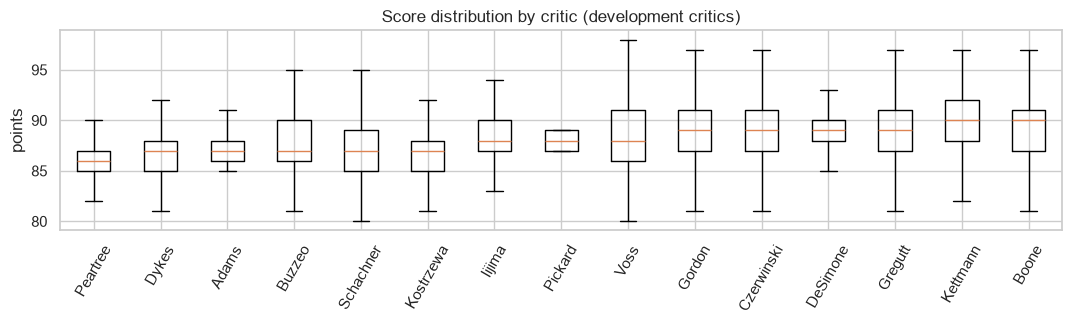

In [16]:
# 2.3c Critics: who reviews what (counts, all data) and how they score (development data)
regions = (df.assign(critic=df["taster_name"].fillna("(anonymous)"))
             .groupby("critic")["country"].agg(reviews="size", top_countries=lambda s: ", ".join(f"{c} {p:.0%}" for c, p in s.value_counts(normalize=True).head(2).items())))
display(regions.sort_values("reviews", ascending=False))
named = dev[dev["taster_name"].notna()]
order = named.groupby("taster_name")["points"].median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.boxplot([named.loc[named.taster_name == c, "points"] for c in order], tick_labels=[c.split()[-1] for c in order], showfliers=False)
ax.set(title="Score distribution by critic (development critics)", ylabel="points"); plt.xticks(rotation=60)
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "p2_scores_by_critic.png", dpi=150); plt.show()

**Critics specialise.** O'Keefe reviews only Italy, Schachner mostly Spain and Chile, and several critics only the US: the region confound of Phase 1's R2. Score distributions also differ by critic.

In [17]:
# 2.3d The tasting notes: length and vocabulary vs score (development data)
dev["n_words"] = dev["description"].str.split().str.len()
by_len = dev.groupby(pd.qcut(dev["n_words"], 5), observed=True)["points"].agg(["mean", "size"]).round(2)
by_len.index = by_len.index.astype(str); display(by_len.rename(columns={"mean": "mean points", "size": "reviews"}))
print(f"Spearman(note length, points) = {dev['n_words'].corr(dev['points'], method='spearman'):.2f}")
# Words most over-represented in 93+ vs ≤ 85 notes (log-odds ratio with a +1 prior, words in ≥ 200 notes)
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(min_df=200, stop_words="english", binary=True)
X = cv.fit_transform(dev["description"]); vocab = np.array(cv.get_feature_names_out())
hi, lo = (dev["points"] >= 93).to_numpy(), (dev["points"] <= 85).to_numpy()
p_hi = (np.asarray(X[hi].sum(0)).ravel() + 1) / (hi.sum() + 2); p_lo = (np.asarray(X[lo].sum(0)).ravel() + 1) / (lo.sum() + 2)
lor = np.log(p_hi / (1 - p_hi)) - np.log(p_lo / (1 - p_lo))
words = pd.DataFrame({"word": vocab, "log_odds_93plus_vs_85minus": lor}).sort_values("log_odds_93plus_vs_85minus")
words["evaluative (frozen list)"] = words["word"].isin(set(config.EVALUATIVE_TERMS))
display(pd.concat([words.tail(15).iloc[::-1], words.head(15)]).round(2).reset_index(drop=True))

,mean points,reviews
n_words,,
"(2.999, 31.0]",85.99,21037
"(31.0, 37.0]",87.48,21186
"(37.0, 42.0]",88.35,19237
"(42.0, 49.0]",89.28,20815
"(49.0, 135.0]",90.63,19829


Spearman(note length, points) = 0.51


,word,log_odds_93plus_vs_85minus,evaluative (frozen list)
0,2022,6.49,False
1,2025,6.39,False
2,2023,5.96,False
3,2030,5.96,False
4,2024,5.91,False
5,2021,5.51,False
6,2020,5.42,False
7,decade,5.20,False
8,superb,5.04,True
9,gorgeous,4.78,True


**The tasting notes carry the signal, and one item is a leak.**
- **Length:** longer notes go with higher scores (Spearman ρ = 0.51).
- **Drinking windows** dominate the high-score words: "2022", "2025", "2030", "decade". Then come verdict words ("superb", "gorgeous") and prestige places ("Barolo", "premier", "site").
- **The low end:** "everyday", "watery", "bland", "simple", "generic", "pizza".
- **⚠ The token "92" is a target leak, not vocabulary.** 671 barrel-sample notes *open with the score range* ("90–92. Barrel sample."). See 2.4a.

In [18]:
# 2.3e Vintage, designation and wine colour vs score (development data)
by_vintage = dev[dev["vintage"].between(2000, 2016)].groupby("vintage")["points"].agg(["mean", "size"]).round(2)
display(by_vintage.T)
des = dev.assign(has_designation=dev["designation"].notna()).groupby("has_designation")["points"].agg(["mean", "size"]).round(2)
display(des)
# Preliminary colour map from variety names (frozen properly in Phase 3 for H5)
reds = ["Pinot Noir", "Cabernet Sauvignon", "Red Blend", "Bordeaux-style Red Blend", "Syrah", "Merlot", "Zinfandel", "Malbec",
        "Sangiovese", "Nebbiolo", "Tempranillo", "Rhône-style Red Blend", "Cabernet Franc", "Grenache", "Shiraz", "Gamay", "Petite Sirah", "Barbera"]
whites = ["Chardonnay", "Sauvignon Blanc", "Riesling", "White Blend", "Pinot Gris", "Grüner Veltliner", "Pinot Grigio",
          "Gewürztraminer", "Viognier", "Chenin Blanc", "Albariño", "Bordeaux-style White Blend", "Vermentino", "Moscato"]
col = np.select([dev["variety"].isin(reds), dev["variety"].isin(whites), dev["variety"].str.contains("Rosé|Rose", na=False)], ["red", "white", "rosé"], "other / unmapped")
print("preliminary colour coverage:", pd.Series(col).value_counts(normalize=True).round(3).to_dict())

vintage,2000.0,2001.0,2002.0,2003.0,2004.0,2005.0,2006.0,2007.0,2008.0,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0
mean,87.39,87.38,87.74,88.43,88.73,88.33,88.18,88.11,88.16,88.29,88.11,88.04,88.62,88.84,88.88,88.33,87.36
size,750.00,682.00,351.00,568.00,1692.00,3465.00,5498.00,6578.00,6749.00,8536.00,9969.00,9392.00,10903.00,10931.00,11128.00,6852.00,2596.00


,mean,size
has_designation,,
False,87.57,29811
True,88.62,72293


preliminary colour coverage: {'red': 0.502, 'white': 0.258, 'other / unmapped': 0.21, 'rosé': 0.03}


**Vintage, designation, colour:** 2004–2014 vintages average about 88–89, while 2000–02 and 2016 average about 87.4 (vintage interacts with review timing, see 2.3g). A named designation averages 88.6 vs 87.6 without (H3 sanity check). The preliminary colour map here is superseded by the map in 2.4c (frozen in Phase 2 revision 3; known false positives from winery names are fixed in Phase 3, before H5 uses it).

In [19]:
# 2.3g Score heaping around the value threshold; price by vintage; full value tables; R3 evidence (development data)
display(dev["points"].value_counts().sort_index().loc[85:93].to_frame("reviews").T)
display(dev[dev["vintage"].between(2000, 2016)].groupby("vintage")["price"].median().to_frame("median price").T)
display(value_table("country").round(3)); display(value_table("variety").round(3))
r3 = {f: int(len(dev[dev.fold == f]) - len(drop_titles_seen_in_training(dev[dev.fold == f], dev[dev.fold != f]))) for f in sorted(dev.fold.unique()) if f >= 0}
print("R3 evidence, test rows dropped because their title appears in training, by development fold:", r3)

points,85,86,87,88,89,90,91,92,93
reviews,8370,10162,12837,12509,8505,11450,8913,7539,5159


vintage,2000.0,2001.0,2002.0,2003.0,2004.0,2005.0,2006.0,2007.0,2008.0,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0
median price,20.0,18.0,19.0,39.0,40.0,32.0,27.0,26.0,27.0,26.0,25.0,24.0,28.0,28.0,25.0,20.0,16.0


,candidates,value_rate,median_price
country,,,
Germany,930,0.303,17.0
Portugal,3274,0.210,14.0
Australia,1320,0.208,17.0
New Zealand,819,0.200,18.0
US,18227,0.179,18.0
Austria,415,0.173,19.0
France,8247,0.168,17.0
Greece,322,0.168,17.0
South Africa,845,0.114,15.0


,candidates,value_rate,median_price
variety,,,
Riesling,2284,0.278,17.0
Gamay,642,0.273,18.0
Portuguese Red,1460,0.270,14.0
Shiraz,423,0.270,17.0
Pinot Gris,813,0.262,18.0
Syrah,981,0.215,20.0
Albariño,357,0.213,19.0
Gewürztraminer,470,0.209,18.0
Viognier,540,0.198,20.0


R3 evidence, test rows dropped because their title appears in training, by development fold: {np.int64(0): 40, np.int64(1): 30, np.int64(3): 16, np.int64(4): 51}


**More exploration:**
- **Score heaping:** critics avoid 89. In development data 88 has 12,509 reviews, **89 only 8,505**, and 90 has 11,450. So the 90+ value label sits right where critics round up. That's a reason for Phase 1's A2 sensitivity check at 88+ / 92+.
- **Price by vintage:** medians rise with age (older vintages reviewed in 2017 are pricier, later-release wines), which supports the review-timing explanation of the vintage pattern.
- **Full ≥ 300-candidate value tables** are shown above.
- **R3 evidence:** test rows dropped because their title appears in training are 40 / 30 / 16 / 51 in development folds 0 / 1 / 3 / 4.

In [20]:
# 2.3f Near-duplicate notes (structure only, all reviews): how many exist? This decides whether DM5 is measurable
from datasketch import MinHash, MinHashLSH
def shingles(t, n=5):
    w = t.lower().split(); return {" ".join(w[i:i + n]) for i in range(max(1, len(w) - n + 1))}
texts = df["description"].drop_duplicates()
lsh, sigs = MinHashLSH(threshold=0.3, num_perm=config.DM5_NUM_PERM), {}   # loose LSH for candidates, then EXACT Jaccard
for i, t in texts.items():
    m = MinHash(num_perm=config.DM5_NUM_PERM, seed=config.SEED); m.update_batch([s.encode() for s in shingles(t)]); sigs[i] = m; lsh.insert(i, m)
cand = {tuple(sorted((i, j))) for i in sigs for j in lsh.query(sigs[i]) if i != j}
sh = {i: shingles(texts[i]) for pair in cand for i in pair}
jac = pd.Series({p: len(sh[p[0]] & sh[p[1]]) / len(sh[p[0]] | sh[p[1]]) for p in cand})
print(f"distinct notes: {len(texts):,}; LSH candidate pairs: {len(cand):,}")
display(pd.Series({f"pairs with Jaccard ≥ {t}": int((jac >= t).sum()) for t in (0.4, 0.5, 0.7, 0.8)}).to_frame("count"))
top = jac.sort_values(ascending=False).head(3)
for (i, j), v in top.items():
    print(f"J={v:.2f} | {df.loc[i, 'title'][:60]} || {df.loc[j, 'title'][:60]}")
hi = jac[jac >= config.DM5_TAU]
kind = pd.Series({p: ("same winery" if df.loc[p[0], "winery"] == df.loc[p[1], "winery"] else "different wineries") for p in hi.index})
same_fold = all(df.loc[p[0], "fold"] == df.loc[p[1], "fold"] for p in hi.index)
print(f"{len(hi)} pairs at J ≥ {config.DM5_TAU}: {kind.value_counts().to_dict()}; all within one fold: {same_fold}")

distinct notes: 119,955; LSH candidate pairs: 1,196


,count
pairs with Jaccard ≥ 0.4,50
pairs with Jaccard ≥ 0.5,43
pairs with Jaccard ≥ 0.7,20
pairs with Jaccard ≥ 0.8,8


J=1.00 | Hargrave 1998 Merlot (North Fork of Long Island) || Castello di Borghese 1998 Hargrave Vineyard Merlot (North Fo
J=0.95 | Torbreck 2006 The Struie Shiraz (Barossa) || Torbreck 2006 The Struie Shiraz (Barossa)
J=0.92 | Herdade da Capela 2013 Terras de Pias Reserva Red (Alentejan || Herdade da Capela 2013 Terras de Pias Reserva Red (Alentejo)
43 pairs at J ≥ 0.5: {'different wineries': 24, 'same winery': 19}; all within one fold: True


**Near-duplicate notes are rare, and most aren't relistings.** Across 119,955 distinct notes, exact Jaccard (after loose LSH candidate generation) gives 50 / **43** / 20 / 8 pairs at ≥ 0.4 / **0.5** / 0.7 / 0.8 (5-word shingles).
- **About a third are the same wine relisted** ("Alentejano" vs "Alentejo"; a vineyard name moved into the winery field).
- **Most are the same critic's note recycled or attached to a different wine:** near-verbatim notes on wines from different producers, or on a producer's red and white (per critic round 3).
- **Every pair is within one fold,** so nothing leaks across folds or the lockbox (printed above).
- So catalogue hygiene (BO4) matters more as **mis-attached notes** than as duplicate listings. Phase 3 flags these ~80 rows as possible label noise.

**DM5 as written in Phase 1 can't be measured:** "recall ≥ 0.9 on a 10k sample" would contain fewer than one true pair. **Loop back to Phase 1** (CRISP-DM's Business ↔ Data Understanding loop): DM5 is re-specified in §1.3 (original kept, struck through and dated). It now uses the **full corpus**: recall on ~1,670 synthetic positives (2–8% word edits, exact J ≥ 0.5; sized by a Phase 2 simulation), a false-flag rate on random pairs, and precision on the 43 real pairs with a labelling rule fixed in advance.

### 2.4 Verify data quality

**CRISP-DM output:** Data quality report

In [21]:
# 2.4 Verify data quality: every issue found, with the rows affected
title_years = df["title"].str.count(r"\b(?:19|20)\d{2}\b")
rt = df[df["title"].duplicated(keep=False)]
g = rt.groupby("title")
issues = pd.DataFrame([
    ("Exact duplicate rows", raw.duplicated().sum()),
    ("Repeat reviews of an already-reviewed title", int((df["title"].value_counts() - 1).clip(lower=0).sum())),
    ("…titles reviewed only by one named critic", int(rt[rt.taster_name.notna()].groupby("title")["taster_name"].agg(lambda s: s.nunique() == 1 and len(s) > 1).sum())),
    ("Duplicated note text (development data; see 2.4c)", int(dev["description"].duplicated(keep=False).groupby(dev["description"]).any().sum())),
    ("Missing price", int(df["price"].isna().sum())),
    ("Missing critic name (anonymous)", int(df["taster_name"].isna().sum())),
    ("Missing country / province", int(df["country"].isna().sum())),
    ("Missing variety", int(df["variety"].isna().sum())),
    ("Missing designation", int(df["designation"].isna().sum())),
    ("Missing region_1 / region_2", f"{df['region_1'].isna().sum():,} / {df['region_2'].isna().sum():,} (region_2 only exists for US)"),
    ("No vintage year in title (non-vintage wines)", int(df["vintage"].isna().sum())),
    ("Title has more than one year (vintage parse ambiguous)", int((title_years > 1).sum())),
    ("Parsed vintage before 1990 (often a winery name, e.g. '1912 Winemakers')", int((df["vintage"] < 1990).sum())),
    ("Price above $1,000", int((df["price"] > 1000).sum())),
    ("Critic name containing a non-breaking space", int(df["taster_name"].dropna().str.contains("\xa0").sum())),
    ("Notes shorter than 10 words", int((df["description"].str.split().str.len() < 10).sum())),
], columns=["check", "rows affected"]).set_index("check")
display(issues)

,rows affected
check,
Exact duplicate rows,9983
Repeat reviews of an already-reviewed title,1148
…titles reviewed only by one named critic,729
Duplicated note text (development data; see 2.4c),13
Missing price,8395
Missing critic name (anonymous),24917
Missing country / province,59
Missing variety,1
Missing designation,34545


*Basic checks; the deeper audits follow.*

In [22]:
# 2.4a Leakage audit of the note text
from winevalue.text_audit import flag_score_leaks, is_barrel_sample, SCORE_RANGE_AT_START
flags = flag_score_leaks(df["description"]).assign(barrel_sample=is_barrel_sample(df["title"], df["description"]), fold=df["fold"])
display(flags.groupby("fold")[["score_range_at_start", "explicit_points", "verdict_label", "currency_amount", "barrel_sample"]].sum()
             .rename(index={LOCKBOX: f"{LOCKBOX} (lockbox: counts only)"}))
# How much does a leading score range reveal? (development data only)
rng = dev["description"].str.extract(r"^\s*\(?(8\d|9\d|100)\s*[-–—]\s*(8\d|9\d|100)").astype(float).dropna()
mid = rng.mean(axis=1); pts = dev.loc[rng.index, "points"]
print(f"development notes opening with a score range: {len(rng)}; recorded score == range midpoint: {(pts == mid).mean():.1%}; "
      f"inside the range: {pts.between(rng[0], rng[1]).mean():.1%}; MAE of the midpoint: {(pts - mid).abs().mean():.3f} points")
print(f"barrel-sample reviews with a price: {df.loc[flags.barrel_sample, 'price'].notna().mean():.1%} (so they're almost never ≤ $25 candidates)")
starts = df.loc[flags.score_range_at_start, "description"]
print(f"range forms: em dash {int(starts.str.match(r'^\s*\(?\d+\s*—').sum())}, '98-100'-type {int(starts.str.match(r'^\s*\(?\d{2}\s*[-–—]\s*100').sum())}; "
      f"duplicated-note groups overall: {int(df['description'].duplicated(keep=False).groupby(df['description']).any().sum())}")

,score_range_at_start,explicit_points,verdict_label,currency_amount,barrel_sample
fold,,,,,
-1,0,7,65,71,4
0,671,0,4,0,672
1,0,11,57,171,0
2 (lockbox: counts only),0,0,0,0,0
3,0,2,64,84,1
4,0,0,1,37,0


development notes opening with a score range: 671; recorded score == range midpoint: 99.7%; inside the range: 99.9%; MAE of the midpoint: 0.008 points
barrel-sample reviews with a price: 2.2% (so they're almost never ≤ $25 candidates)
range forms: em dash 41, '98-100'-type 3; duplicated-note groups overall: 33


**2.4a The target is written into some notes.**
- **What:** 671 development notes (all fold 0, Roger Voss **barrel samples**; 41 use an em dash, three use "98-100") open with the score range, e.g. "90–92. Barrel sample.". The **recorded score equals the range midpoint 99.7% of the time** (MAE 0.008 points).
- **Other text leaks:** 20 notes state a score ("rated 92 points", "a 90-point wine", "90+ rating"), 184 carry WineEnthusiast labels ("Best Buy", "Editors' Choice", "Cellar Selection"), and 333 contain a price ("an under-$15 red", "10 bucks"), which matters for the price-free model (R-2). Regexes are restricted to plausible scores (80–100), so "14-15% alcohol" can't match (tested).
- **Who it affects:** barrel samples are pre-release assessments and almost never priced (1.5%), so they barely touch the ≤ $25 shortlist (BSC1/BSC2). But they teach any model trained on fold 0 that "9x" tokens are scores.
- **Decision (Phase 3, all models):** drop barrel-sample reviews (671) from training and evaluation; strip explicit score mentions and verdict labels; replace prices with a `_price_` token. This is a leakage fix, separate from the frozen evaluative list.

In [23]:
# Does the leak change the Phase 1 feasibility numbers? Fold 0 (where all barrel samples are), re-run without them
from winevalue.models import GroupMeanBaseline, quick_text_model, QUALITY_INPUTS
from winevalue.metrics import mae, within
from winevalue.splits import drop_titles_seen_in_training
barrel = is_barrel_sample(dev["title"], dev["description"])
out = []
for f in sorted(x for x in dev["fold"].unique() if x >= 0):
    for label, data in [("as in Phase 1", dev), ("barrel samples removed", dev[~barrel])]:
        tr = data[data["fold"] != f]; te = drop_titles_seen_in_training(data[data["fold"] == f], tr)
        p = quick_text_model().fit(tr[QUALITY_INPUTS], tr["points"]).predict(te[QUALITY_INPUTS])
        b = GroupMeanBaseline().fit(tr, tr["points"]).predict(te)
        out.append({"fold": f, "version": label, "MAE reduction vs v×c": 1 - mae(te.points, p) / mae(te.points, b)})
display(pd.DataFrame(out).pivot(index="fold", columns="version", values="MAE reduction vs v×c").round(3))

version,as in Phase 1,barrel samples removed
fold,,
0,0.327,0.349
1,0.332,0.330
3,0.119,0.117
4,0.316,0.316


**Effect on Phase 1's feasibility numbers:** removing barrel samples *raises* fold 0's MAE reduction from 32.7% to 34.9%, and folds 1/3/4 change by ≤ 0.2 pp (33.2 → 33.0, 11.9 → 11.7, 31.6 → 31.6%). The leak didn't inflate Phase 1, and the pre-registered targets stand.

In [24]:
# What does the frozen evaluative mask leave behind? (DM1b limitation; the frozen list itself is unchanged)
from winevalue.models import mask_evaluative
hi93 = dev[dev["points"] >= 93]
masked = mask_evaluative(hi93["description"])
resid = pd.Series({
    "93+ development notes with a 20xx year (before masking)": int(hi93["description"].str.contains(r"\b20\d{2}\b").sum()),
    "…still containing a 20xx year after masking (e.g. 'now–2025')": int(masked.str.contains(r"\b20\d{2}\b").sum()),
    "…containing 'decade' (not in the frozen list)": int(masked.str.contains(r"\bdecades?\b", case=False).sum()),
    "…containing 'N years' phrases": int(masked.str.contains(r"\b\d+\s+years?\b|\b(?:five|ten|several|many)\s+years\b", case=False).sum()),
})
display(resid.to_frame("notes"))

,notes
93+ development notes with a 20xx year (before masking),3923
…still containing a 20xx year after masking (e.g. 'now–2025'),920
…containing 'decade' (not in the frozen list),250
…containing 'N years' phrases,1038


**What the frozen mask leaves behind (a DM1b limitation; the frozen list isn't changed):** of 3,923 development 93+ notes with a 20xx year, 920 still contain one after masking (e.g. "now–2025"). 250 contain "decade" and 1,038 contain "N years" phrases. So DM1b's 87% retention is an upper bound on "signal beyond verdict words". Phase 4 reports a stricter mask alongside it as a sensitivity check.

In [25]:
# Vintage rule: Phase 1 parser vs the revised rule (strip winery prefix, first year)
v_new = extract_vintage(df["title"], df["winery"])
changed = df.loc[(df["vintage"] != v_new) & ~(df["vintage"].isna() & v_new.isna()), ["title", "winery"]].assign(old=df["vintage"], new=v_new)
print(f"titles whose vintage changes: {len(changed)}; parsed vintages before 1990: {int((df['vintage'] < 1990).sum())} → {int((v_new < 1990).sum())}")
display(changed.head(8))

titles whose vintage changes: 17; parsed vintages before 1990: 69 → 52


,title,winery,old,new
review_id,,,,
7986,Guidi 1929 2012 Aurea Riserva (Vernaccia di San Gimignano),Guidi 1929,1929.0,2012.0
9728,1912 Winemakers 2011 Vinhas Velhas Branco White (Douro),1912 Winemakers,1912.0,2011.0
38689,1912 Winemakers 2009 Piorro Reserva Red (Douro),1912 Winemakers,1912.0,2009.0
41070,1912 Winemakers 2013 Piorro Branco Colheita White (Douro),1912 Winemakers,1912.0,2013.0
54720,1912 Winemakers 2009 Encosta do Bocho Grand Reserva Red (Douro),1912 Winemakers,1912.0,2009.0
54748,Alvear NV Solera 1927 Pedro Ximénez (Montilla-Moriles),Alvear,1927.0,NaN
56426,Arthur Metz NV 1904 Cuvée Spéciale Brut Sparkling (Crémant d'Alsace),Arthur Metz,1904.0,NaN
61105,1912 Winemakers 2011 Piorro Colheita Red (Douro),1912 Winemakers,1912.0,2011.0


**Vintage rule, corrected.** The Phase 1 parser took the first year in the title, which picks years inside winery names. The revised rule strips the winery name (titles always start with it), treats a title with **"NV" before the first year as non-vintage** ("Alvear NV Solera 1927", "Arthur Metz NV 1904"), and then takes the **first** remaining year. It changes 17 titles, and pre-1990 vintages fall from 69 to **52, all genuine** (Rivesaltes 1945, Port, Mosel). Later years in a title are planting or cuvée years ("Vignes de 1939"), so "nearest the end" (round-1 draft) would have been wrong. Implemented in `extract_vintage(title, winery)` and unit-tested; applied from Phase 3.

In [26]:
# 2.4c Identity checks: is `title` a wine key? duplicate notes; synonyms; encodings; pseudo-provinces; prices
rt = df[df["title"].duplicated(keep=False)]
g = rt.groupby("title")
named_same = int(rt[rt.taster_name.notna()].groupby("title")["taster_name"].agg(lambda s: s.nunique() == 1 and len(s) > 1).sum())
print(f"repeat titles: {rt.title.nunique()}; with different varieties (so different wines): {int((g['variety'].nunique() > 1).sum())}; "
      f"with different prices: {int((g['price'].nunique() > 1).sum())}; reviewed only by one named critic: {named_same}")
dup_notes = dev[dev["description"].duplicated(keep=False)]
dn = dup_notes.groupby("description")
print(f"development: duplicated note texts {dn.ngroups}; attached to different titles {int((dn['title'].nunique() > 1).sum())}, "
      f"different wineries {int((dn['winery'].nunique() > 1).sum())}, different varieties {int((dn['variety'].nunique() > 1).sum())}")
syn = df.assign(grape=grape_canonical(df["variety"]))
merged = syn[syn["grape"] != syn["variety"]].groupby(["grape", "variety"]).size().sort_values(ascending=False)
print(f"labels merged by the synonym map: {merged.index.get_level_values(1).nunique()} labels, {int(merged.sum()):,} reviews")
display(syn[syn["grape"].isin(["Pinot Gris", "Syrah"])].groupby(["grape", "variety"])["country"]
          .agg(reviews="size", top_country=lambda s: f"{s.value_counts().index[0]} {s.value_counts(normalize=True).iloc[0]:.0%}"))
colour = wine_colour(df["variety"], df["title"])
print("frozen colour map coverage:", colour.value_counts(normalize=True).round(3).to_dict())
print("largest unmapped labels:", df.loc[colour == "unmapped", "variety"].value_counts().head(8).to_dict())
text_cols = ["title", "winery", "designation", "description", "taster_name", "province", "region_1"]
enc = pd.DataFrame({c: {"non-breaking space": int(df[c].dropna().str.contains("\xa0").sum()),
                        "mojibake (Ã or Â)": int(df[c].dropna().str.contains("Ã|Â").sum())} for c in text_cols}).T
display(enc[enc.sum(axis=1) > 0])
wk = df["winery"].str.casefold().str.replace(r"\s+", " ", regex=True).str.strip()
print(f"winery names that differ only by case/whitespace: {int((df.groupby(wk)['winery'].nunique() > 1).sum())} groups")
pseudo = df["province"].str.contains(r"(?:^| )Other$", regex=True, na=False) | (df["province"] == df["country"])
print("pseudo-provinces:", df.loc[pseudo, "province"].value_counts().head(8).to_dict(), f"(total {int(pseudo.sum())})")
hi = df[df["price"] > 1000][["title", "price", "variety"]].sort_values("price", ascending=False)
year_price = df[df["price"].between(1900, 2017) & (df["price"] == df["vintage"])]
display(hi)
print(f"rows where price equals the vintage year: {len(year_price)}")

repeat titles: 934; with different varieties (so different wines): 250; with different prices: 474; reviewed only by one named critic: 729
development: duplicated note texts 13; attached to different titles 13, different wineries 6, different varieties 5
labels merged by the synonym map: 57 labels, 6,131 reviews


reviews    top_country
grape      variety                              
Pinot Gris Grauburgunder       14    Germany 50%
           Pinot Grigio       980      Italy 58%
           Pinot Gris        1324         US 60%
Syrah      Shiraz             790  Australia 74%
           Syrah             3828         US 79%

frozen colour map coverage: {'red': 0.593, 'white': 0.308, 'sparkling': 0.043, 'rosé': 0.034, 'unmapped': 0.015, 'fortified': 0.007}
largest unmapped labels: {'Carricante': 32, 'Rkatsiteli': 30, 'Castelão': 29, 'Picolit': 26, 'Catarratto': 25, 'Scheurebe': 24, 'Charbono': 23, 'Welschriesling': 23}


,non-breaking space,mojibake (Ã or Â)
title,22,2
winery,15,0
designation,7,2
description,2,1
taster_name,3290,0


winery names that differ only by case/whitespace: 29 groups
pseudo-provinces: {'France Other': 623, 'Other': 506, 'Australia Other': 231, 'Italy Other': 126, 'England': 63, 'Spain Other': 58, 'Moldova': 51, 'Chile': 48} (total 1921)


,title,price,variety
review_id,,,
80290,Château les Ormes Sorbet 2013 Médoc,3300.0,Bordeaux-style Red Blend
15840,Château Pétrus 2014 Pomerol,2500.0,Bordeaux-style Red Blend
98380,Domaine du Comte Liger-Belair 2010 La Romanée,2500.0,Pinot Noir
120391,Blair 2013 Roger Rose Vineyard Chardonnay (Arroyo Seco),2013.0,Chardonnay
65352,Château Pétrus 2011 Pomerol,2000.0,Bordeaux-style Red Blend
113564,Domaine du Comte Liger-Belair 2005 La Romanée,2000.0,Pinot Noir
1558,Château Margaux 2009 Margaux,1900.0,Bordeaux-style Red Blend
111753,Château Lafite Rothschild 2010 Pauillac,1500.0,Bordeaux-style Red Blend
111755,Château Cheval Blanc 2010 Saint-Émilion,1500.0,Bordeaux-style Red Blend


rows where price equals the vintage year: 1


**2.4c Identity and encoding checks:**
- **`title` isn't a wine key.** 250 of 934 repeat titles cover *different wines* (e.g. a red and a white sold under one title), and 474 have different prices. Repeat-title analyses therefore use title + variety.
- **Duplicated notes** (13 groups in development data, 33 overall) are attached to *different* titles. Some are the same wine relisted (Hargrave ≡ "Castello di Borghese Hargrave Vineyard"), some are notes pasted onto another wine, and 2 are barrel samples. Decision: keep **one** row per duplicated note (the first), drop the rest.
- **Grape synonyms.** `grape_canonical` (in `winevalue.grapes`) merges 43 labels / 5,891 reviews (Shiraz → Syrah, Pinot Grigio → Pinot Gris, Garnacha → Grenache, …), using standard ampelographic synonyms only, never scores. Raw `variety` stays unchanged for the frozen simple rules and the variety × country baseline (pre-registration kept). The canonical grape is used for DM4, H5 and the app.
- **Colour map (frozen now, for H5).** `wine_colour(variety, title)`: title style words (rosé, Brut / sparkling, Port / Sherry) override the grape; blends take the first-listed grape's colour. It covers **97.9%** of reviews (59.0% red, 30.3% white, 4.3% sparkling, 3.5% rosé, 0.7% fortified), built from grape knowledge and title text only, before any colour × value table. Unmapped labels are listed above (largest: "Gros and Petit Manseng", 46).
- **Encoding.** Non-breaking spaces appear in 3,290 critic names (only Anne Krebiehl MW, consistent across folds), 22 titles, 15 winery rows and 7 designations; mojibake ("Ã"/"Â") in 5 cells across 3 fields; 29 winery names differ only by case or whitespace. Decision: normalise whitespace and case-fold winery keys for models. The frozen winery track-record rule keeps the raw name (pre-registration), with an effect of ≤ 29 groups.
- **Pseudo-provinces** ("France Other", "Other", "Australia Other", province = country; 1,921 rows) become "Unknown province" for models; the frozen province rule is unchanged.
- **Prices > $1,000**, checked by hand:
  - the first-growth Bordeaux and Burgundy prices are plausible;
  - **"Château les Ormes Sorbet 2013 Médoc" at $3,300** and **Blair 2013 Chardonnay at $2,013** (price = vintage year) are errors;
  - Knoll Smaragd Grüner Veltliner at $1,100 is implausible.
  - Decision: set those 3 to missing (the real maximum is then $2,500, Pétrus).

In [27]:
# 2.4b Human noise floor, done properly (development data only)
from itertools import combinations
def pairs(frame, same_critic):
    keys = ["title", "variety", "taster_name"] if same_critic else ["title", "variety"]
    rows = []
    for _, g in frame[frame["taster_name"].notna()].groupby(keys):
        if len(g) < 2: continue
        for (i, a), (j, b) in combinations(g[["points", "taster_name", "price"]].iterrows(), 2):
            if same_critic or a.taster_name != b.taster_name:
                rows.append((abs(a.points - b.points), min(a.price, b.price) if pd.notna(a.price) and pd.notna(b.price) else np.nan))
    return pd.DataFrame(rows, columns=["diff", "price"])
from scipy.stats import norm
res = []
for label, same in [("same critic, same title + variety", True), ("different critics, same title + variety", False)]:
    p = pairs(dev, same)
    for band, q in [("all prices", p), ("≤ $25", p[p.price <= config.VALUE_MAX_PRICE])]:
        if len(q) < 20: continue
        # one review = expected score + noise e, e ~ N(0, σ²); a pair difference has variance 2σ², so σ = RMS(diff) / √2.
        # A perfect predictor of the expected score (continuous) is within ±2 of a single review with P = 2Φ(2/σ) − 1.
        sigma = np.sqrt((q["diff"] ** 2).mean() / 2)
        res.append({"comparison": label, "price band": band, "pairs": len(q), "mean |diff|": q["diff"].mean(),
                    "exact match": (q["diff"] == 0).mean(), "within ±2": (q["diff"] <= 2).mean(),
                    "implied single-read σ": sigma,
                    "ceiling: P(|error| ≤ 2) for a perfect predictor": 2 * norm.cdf(2 / sigma) - 1})
display(pd.DataFrame(res).set_index(["comparison", "price band"]).round(3))

pairs  mean |diff|  \
comparison                              price band                       
same critic, same title + variety       all prices    728        1.527   
                                        ≤ $25         304        1.618   
different critics, same title + variety all prices     39        2.256   
                                        ≤ $25          20        1.700   

                                                    exact match  within ±2  \
comparison                              price band                           
same critic, same title + variety       all prices        0.225      0.793   
                                        ≤ $25             0.181      0.770   
different critics, same title + variety all prices        0.205      0.641   
                                        ≤ $25             0.150      0.800   

                                                    implied single-read σ  \
comparison                              price band                          
same critic, same title + variety       all prices                  1.446   
                                        ≤ $25                       1.491   
different critics, same title + variety all prices                  2.166   
                                        ≤ $25                       1.565   

                                                    ceiling: P(|error| ≤ 2) for a perfect predictor  
comparison                              price band                                                   
same critic, same title + variety       all prices                                            0.833  
                                        ≤ $25                                                 0.820  
different critics, same title + variety all prices                                            0.644  
                                        ≤ $25                                                 0.799

**2.4b The human noise floor, done properly.** Pairs are now pairwise (not ranges), on the same **title + variety** (a stricter wine key), development data only. Assume one review = the wine's expected score + noise.

| Comparison | Price band | Pairs | Mean \|diff\| | Within ±2 | Implied single-review σ | Ceiling: P(within ±2) for a perfect predictor |
|---|---|---|---|---|---|---|
| Same critic | all | 728 | 1.53 | 79% | 1.45 | 0.83 |
| Same critic | ≤ $25 | 304 | 1.62 | 77% | 1.49 | **0.82** |
| Different critics | all | 39 | 2.26 | 64% | 2.17 | 0.64 |
| Different critics | ≤ $25 | 20 | 1.70 | 80% | 1.57 | 0.80 (n tiny) |

- **The √2 correction.** A difference between two reviews contains two noises, so σ = RMS(diff)/√2 and the ceiling is 2Φ(2/σ) − 1: about **0.82** for one critic at ≤ $25.
- **Correct comparison.** The Phase 1 model is scored on *unseen* critics, so the relevant ceiling lies between the **cross-critic** values (0.64 at all prices, n = 39; 0.80 at ≤ $25, n = 20) and the same-critic value (0.82). The ceiling is roughly **0.64–0.83**, and every figure rests on small, selected samples. The model's 0.69 is therefore **not** "close to critics' own consistency". There is likely, but uncertain, headroom.
- **Caveat:** re-reviewed wines are a selected sample.

In [28]:
# Co-author pair across the lockbox boundary: Jeff Jenssen (lockbox) and Mike DeSimone (fold 4) share @worldwineguys.
# Text-only check with the Phase 1 style classifier: how often is one mistaken for the other on held-out notes?
pred = clf.classes_[held.argmax(1)]
truth = te_txt["taster_name"].to_numpy()
for a, b in [("Jeff Jenssen", "Mike DeSimone"), ("Mike DeSimone", "Jeff Jenssen")]:
    m = truth == a
    print(f"held-out {a} notes: {m.sum()}; predicted as {b}: {(pred[m] == b).mean():.1%}; correctly attributed: {(pred[m] == a).mean():.1%}")

held-out Jeff Jenssen notes: 87; predicted as Mike DeSimone: 5.7%; correctly attributed: 82.8%
held-out Mike DeSimone notes: 92; predicted as Jeff Jenssen: 6.5%; correctly attributed: 87.0%


**Co-author pair across the lockbox boundary.** Jeff Jenssen (lockbox) and Mike DeSimone (fold 4) share the handle @worldwineguys. On held-out notes, the text-only style classifier confuses them only 6–7% of the time (83% and 87% correctly attributed), and they share no titles. So the "unseen writer" premise for Jenssen is weakened only slightly. Noted as a limitation.

**Data quality report: decisions (applied in Phase 3; none changes the frozen Phase 1 design or targets):**

| Issue | Rows | Decision |
|---|---|---|
| Exact duplicate rows | 9,983 | Drop |
| **Score written in note (barrel samples)** | 671 | **Drop barrel samples** from training and evaluation |
| Explicit score / verdict label / price in note | 20 / 184 / 333 | Strip scores and labels; replace prices with `_price_` (R-2) |
| Duplicated note on different titles | 13 groups (dev), 33 overall | Keep one row per note, drop the rest |
| Repeat titles | 1,148 reviews / 934 titles (250 cover different wines) | Wine key = title + variety; keep genuine re-reviews in training; drop test rows whose title appears in training (R-3, evidence in 2.3g) |
| Missing price | 8,395 (+3 set missing) | Keep for score models; excluded from the ≤ $25 pool and the value verdict |
| Implausible prices | 3 | Set to missing |
| Anonymous critic | 24,917 | Training only; 859 style-attributed to lockbox critics dropped (R8) |
| Missing country/province/variety | 60 | "Unknown" |
| Pseudo-provinces | 1,921 | "Unknown province" for models; frozen rule unchanged |
| Missing designation / region | 28% / 16% | Missing indicator |
| Vintage parse | 17 changed | Strip the winery prefix; NV before the first year → non-vintage; else first year (tested) |
| Non-vintage | 4,285 | Non-vintage flag |
| Grape synonyms | 43 labels / 5,891 reviews | `grape_canonical` for DM4/H5/app; raw label for the frozen rules |
| Encoding / winery case variants | see 2.4c | Normalise; case-fold winery keys for models |
| Notes < 10 words | 39 | Keep; flag |
| Mask residuals (years, "decade") | see 2.4a | DM1b limitation; a stricter mask as a Phase 4 sensitivity check |
| Co-author pair Jenssen/DeSimone | – | Limitation |
| No review date | all | Limitation (vintage ↔ timing) |

> **Critic review: Phase 2.** The revisions are logged in `critiques/phase2_data_understanding_round*.md`.

---
# Phase 3 · Data Preparation

> **Revision 3**, after critic round 2 (8/10, no major issues; `critiques/phase3_data_preparation_round2.md`): "Blanc de Noir(s)" now yields to sparkling cues (40 sparkling wines had been labelled white); the mojibake repair no longer damages correct text; descriptive "a point" is kept; "bang for the buck", "price point" and `_price_` join the strict DM1b mask; DM5 timeline and the meaning of (a) are stated; the R8 filter takes a `critics=` argument for per-fold CV.
>
> **Revision 2**, after critic round 1 (7/10; `critiques/phase3_data_preparation_round1.md`). Main changes:
> - the **lockbox mapping is pinned** as a frozen constant;
> - **DM5's corpus is named**, its labelling rule is self-contained, and (c) is reported as exploratory;
> - leak patterns are widened (score commentary, verdict labels, prices in words, text-only barrel samples);
> - the **leakage audit has checks that can fail**;
> - `n_words` is counted on the model text;
> - the colour map has a dated amendment;
> - variety is encoded once (grape + "label differs" flag).

All preparation is one deterministic function, `winevalue.prepare.prepare()`. It applies every Phase 2 decision in order and logs each step, so the cleaning report below is generated, not hand-written.

**Items carried from Phase 2 critic round 3, resolved here (before any DM5 run or H5 use):**

| Item | Resolution |
|---|---|
| N1 DM5 parameters | LSH threshold 0.3 + exact verification (`config.DM5_LSH_THRESHOLD`); the synthetic construction is fully specified and implemented (`similarity.synthetic_copies`); the corpus is named |
| N2 untestable false-flag test | Removed. False flags vs Jaccard can't happen after exact verification. The candidate-share check is reported as an engineering check, not a test |
| N3 DM5(c) labelling and set | Self-contained rule `similarity.is_true_duplicate` (computes its own vintage and grape). Evaluated on all flagged pairs of the named corpus. **Exploratory**, because the pairs were seen in Phase 2 |
| N4 colour false positives | Override on the **winery-stripped** title with strict patterns + negative tests. Re-frozen 2026-11-04, amended in revision 2 (US "Port", still Blanc de Noir, Clairet) and revision 3 (Blanc de Noir yields to sparkling cues). All before any colour × value table |
| N5 Muscat family, unmapped grapes | Merged and mapped. Remaining unmapped wines (1.5%) are **excluded from H5** |

### Frozen folds (pinned after Phase 3 critic round 1)
Phase 1 derived the critic → fold mapping on the *de-duplicated* reviews. Recomputing it on a different row set (e.g. the raw file) would give a different lockbox. It's now a frozen constant (`config.CRITIC_FOLDS`, `config.LOCKBOX_CRITICS`). `assign_folds()` uses it and fails on any unknown critic, and a test checks that it equals the Phase 1 derivation.

In [29]:
pd.DataFrame({"fold": config.CRITIC_FOLDS}).reset_index(names="critic").groupby("fold")["critic"].apply(", ".join).to_frame() \
  .assign(role=lambda t: ["LOCKBOX (Phase 5 only)" if f == config.LOCKBOX_FOLD else "cross-validation" for f in t.index])

,critic,role
fold,,
0,Roger Voss,cross-validation
1,"Michael Schachner, Jim Gordon",cross-validation
2,"Kerin O’Keefe, Sean P. Sullivan, Anne Krebiehl MW, Jeff Jenssen",LOCKBOX (Phase 5 only)
3,"Paul Gregutt, Joe Czerwinski, Anna Lee C. Iijima, Carrie Dykes, Fiona Adams, Christina...",cross-validation
4,"Virginie Boone, Matt Kettmann, Lauren Buzzeo, Susan Kostrzewa, Mike DeSimone, Alexande...",cross-validation


### 3.1 Select data

**CRISP-DM output:** Rationale for inclusion / exclusion

In [30]:
from winevalue.prepare import prepare, outlier_report, leakage_audit, INDEPENDENT_LEAK_TERMS
from winevalue.features import QUALITY_INPUTS_V2, RANKER_INPUTS_V2, build_preprocessor
from winevalue.splits import anon_lockbox_like
raw = load_raw()
anon_drop = anon_lockbox_like(raw.drop_duplicates())          # Phase 1 R8 (text only)
prep, prep_log = prepare(raw, anon_lockbox_like=anon_drop)
sparse = {c: prep[c].nunique() for c in ["region_1", "region_2", "designation"]}
roles = pd.DataFrame([
    ("points", "target", "the critic score to estimate"),
    ("note (from description)", "input: quality + ranker", "note with scores, score commentary, verdict labels and prices stripped"),
    ("country, province_model, grape (+ label_differs), colour", "input: quality + ranker", "origin; ONE grape encoding (canonical grape + 'label differs' flag) instead of raw variety and grape"),
    ("vintage, is_nonvintage, n_words, has_designation, has_region_1", "input: quality + ranker", "constructed in 3.3"),
    ("price", "input: ranker only; value verdict", "R-2: excluded from the quality model so 'quality vs price' isn't circular"),
    ("winery / winery_key", "simple-rule set + DM6; not a model input yet", "56% of reviews come from wineries with < 20 reviews. Producer names also appear in about 6% of notes, a known channel"),
    ("variety (raw label)", "frozen simple rules + variety × country baseline only", "kept unchanged for the pre-registered benchmarks"),
    ("region_1, region_2, designation (text)", "excluded as raw categories", f"too sparse ({sparse['region_1']:,} / {sparse['region_2']} / {sparse['designation']:,} values in the prepared table); represented by flags"),
    ("taster_name, critic, taster_twitter_handle", "EXCLUDED (R-2)", "new notes come from unseen writers; used only for folds and DM6"),
    ("title, raw description", "excluded as inputs", "sources for vintage, colour and audits"),
], columns=["column(s)", "role", "rationale"])
display(roles)

,column(s),role,rationale
0,points,target,the critic score to estimate
1,note (from description),input: quality + ranker,"note with scores, score commentary, verdict labels and prices stripped"
2,"country, province_model, grape (+ label_differs), colour",input: quality + ranker,origin; ONE grape encoding (canonical grape + 'label differs' flag) instead of raw var...
3,"vintage, is_nonvintage, n_words, has_designation, has_region_1",input: quality + ranker,constructed in 3.3
4,price,input: ranker only; value verdict,R-2: excluded from the quality model so 'quality vs price' isn't circular
5,winery / winery_key,simple-rule set + DM6; not a model input yet,56% of reviews come from wineries with < 20 reviews. Producer names also appear in abo...
6,variety (raw label),frozen simple rules + variety × country baseline only,kept unchanged for the pre-registered benchmarks
7,"region_1, region_2, designation (text)",excluded as raw categories,"too sparse (1,226 / 17 / 37,665 values in the prepared table); represented by flags"
8,"taster_name, critic, taster_twitter_handle",EXCLUDED (R-2),new notes come from unseen writers; used only for folds and DM6
9,"title, raw description",excluded as inputs,"sources for vintage, colour and audits"


**Rows: inclusion and exclusion** (each counted in the 3.2 log, including how many **lockbox** rows each text rule removed):
- **Excluded:**
  - exact duplicates;
  - barrel samples (the score is written in the note, or the note says "barrel sample");
  - all but one copy of each duplicated note, and of each near-duplicate pair (exact Jaccard ≥ 0.5, the same definition DM5 uses);
  - anonymous notes attributed to a lockbox critic (R8).
- **Kept but sealed:** lockbox reviews (`is_lockbox`), used only in Phase 5.
- **Kept, missing price:** used for score models; excluded from the ≤ $25 pool.
- **Kept, outliers:** see 3.2.

### 3.2 Clean data

**CRISP-DM output:** Data cleaning report (incl. outlier analysis)

In [31]:
display(prep_log.astype(object).fillna("").set_index("step"))
print(f"modeling table: {len(prep):,} reviews; development {int((~prep.is_lockbox).sum()):,}; lockbox (sealed) {int(prep.is_lockbox.sum()):,}")
display(outlier_report(prep))

,rows before,rows after,rows affected,lockbox rows affected,note
step,,,,,
drop exact duplicate rows,129971.0,119988.0,9983.0,,
drop barrel samples (score written in note),119988.0,119311.0,677.0,0.0,Phase 2 §2.4a
keep one row per duplicated note,119311.0,119280.0,31.0,20.0,Phase 2 §2.4c (text rule)
keep one row per near-duplicate pair (exact Jaccard ≥ 0.5),119280.0,119237.0,43.0,16.0,43 pairs; all within one fold: True (text rule)
drop anonymous notes attributed to a lockbox critic,119237.0,118378.0,859.0,0.0,"Phase 1 R8, p > 0.5"
set implausible prices to missing,,,3.0,,"hand-checked, Phase 2 §2.4c"
constructed attributes,,,,,"note, province_model, grape, colour, vintage (rev. rule), is_nonvintage, age_at_scrape..."


modeling table: 118,378 reviews; development 100,530; lockbox (sealed) 17,848


,rows
log price outside 1.5×IQR,1078
note length outside 1.5×IQR,1965
"Isolation Forest outliers (1% contamination; price, length, age)",1071


**Data cleaning report** (counts above):
- **Removed:**
  - 9,983 exact duplicates;
  - 677 barrel samples (none in the lockbox);
  - 31 duplicated notes, keeping one copy (20 of them lockbox rows; a text-only rule);
  - 43 near-duplicates, keeping one per pair (16 lockbox; all pairs within one fold);
  - 859 lockbox-like anonymous notes.
  - **118,378 reviews remain** (17,848 lockbox). The lockbox lost 36 rows to text-only rules, which is reported, not hidden.
- **Repaired:**
  - mojibake repaired only where the Latin-1 → UTF-8 round trip succeeds ("crÃ¨me" → "crème"; correct text such as "Âme" is untouched), whitespace normalised in every text column;
  - 3 implausible prices set to missing;
  - missing categories → "Unknown";
  - pseudo-provinces → "Unknown province";
  - vintage re-parsed with the corrected rule.
- **Model text `note`:** explicit scores, **score commentary** ("too ripe to score higher", "loses a few points"; a descriptive "a point of acidity" is kept), WineEnthusiast labels ("Best Buy(s)", "Editor's Choice") removed; prices, including words like "six bucks", → `_price_`.
- **Known residual (R-2):** price-*relative* wording ("at the price", "value-priced", "bang for the buck", "price point") and the `_price_` placeholder with its context stay in `note`. The stricter mask `text_audit.strict_price_mask` removes both in the Phase 4 sensitivity check.
- **Outlier analysis** (inputs only): 1,078 log-price / 1,965 note-length / 1,071 Isolation-Forest outliers. **Kept**, because they're genuine wines.

### 3.3 Construct data

**CRISP-DM outputs:** Derived attributes · Generated records

In [32]:
derived = pd.DataFrame([
    ("note", "description minus scores, score commentary, verdict labels; prices → _price_", "leak-free model text"),
    ("grape / label_differs", "grape_canonical(variety) / grape ≠ raw label", "one grape encoding; label style kept as a flag"),
    ("colour", "wine_colour(variety, title, winery, description); text only, never scores", "H5 (unmapped → excluded); navigation"),
    ("province_model", "province with pseudo-provinces → 'Unknown province'", "cleaner origin category"),
    ("vintage / is_nonvintage", "extract_vintage(title, winery) (revised rule + NV guard)", "age signal"),
    ("age_at_scrape", "2017 − vintage", "interpretable age (no review date exists)"),
    ("n_words / short_note", "word count of NOTE (model text) / < 10 words", "length signal (H1); flag"),
    ("has_designation", "designation (named cuvée / bottling) present", "H3; specificity"),
    ("has_region_1", "region_1 (sub-region / appellation) present", "specificity"),
    ("winery_key", "case-folded winery", "consistent producer key"),
    ("in_value_pool", "price ≤ $25 (and not missing)", "BSC1/BSC2 candidate pool"),
], columns=["attribute", "definition", "purpose"])
display(derived)
display(prep[["colour", "label_differs", "is_nonvintage", "short_note", "has_designation", "has_region_1", "in_value_pool"]]
        .apply(lambda s: s.value_counts(normalize=True).round(3).to_dict()).to_frame("distribution (all reviews; no scores)"))

,attribute,definition,purpose
0,note,"description minus scores, score commentary, verdict labels; prices → _price_",leak-free model text
1,grape / label_differs,grape_canonical(variety) / grape ≠ raw label,one grape encoding; label style kept as a flag
2,colour,"wine_colour(variety, title, winery, description); text only, never scores",H5 (unmapped → excluded); navigation
3,province_model,province with pseudo-provinces → 'Unknown province',cleaner origin category
4,vintage / is_nonvintage,"extract_vintage(title, winery) (revised rule + NV guard)",age signal
5,age_at_scrape,2017 − vintage,interpretable age (no review date exists)
6,n_words / short_note,word count of NOTE (model text) / < 10 words,length signal (H1); flag
7,has_designation,designation (named cuvée / bottling) present,H3; specificity
8,has_region_1,region_1 (sub-region / appellation) present,specificity
9,winery_key,case-folded winery,consistent producer key


,distribution (all reviews; no scores)
colour,"{'red': 0.593, 'white': 0.309, 'sparkling': 0.043, 'rosé': 0.034, 'unmapped': 0.015, '..."
label_differs,"{False: 0.95, True: 0.05}"
is_nonvintage,"{False: 0.965, True: 0.035}"
short_note,"{False: 1.0, True: 0.0}"
has_designation,"{True: 0.71, False: 0.29}"
has_region_1,"{True: 0.835, False: 0.165}"
in_value_pool,"{False: 0.527, True: 0.473}"


**Generated records:** none in the modeling table. DM5's synthetic near-duplicate copies are generated from note text only, for the DM5 evaluation, from its named corpus:

In [33]:
from winevalue.similarity import detect_near_duplicates, is_true_duplicate, synthetic_copies
dm5_corpus, _ = prepare(raw, stop_before="near_duplicates")
syn = synthetic_copies(dm5_corpus["description"])
pairs = detect_near_duplicates(dm5_corpus["description"])
n_pairs_total = len(dm5_corpus) * (len(dm5_corpus) - 1) / 2
labels = [is_true_duplicate(dm5_corpus.loc[i], dm5_corpus.loc[j]) for i, j in zip(pairs.i, pairs.j)]
print(f"DM5 corpus: {len(dm5_corpus):,} notes. Synthetic positives (exact J ≥ {config.DM5_TAU}): {(syn.jaccard >= config.DM5_TAU).sum():,} of {len(syn):,}")
print(f"(b) candidate share: {pairs.attrs['n_candidates']:,} candidates / {n_pairs_total:,.0f} pairs = {pairs.attrs['n_candidates'] / n_pairs_total:.1e} (engineering check)")
print(f"(c) EXPLORATORY precision on the {len(pairs)} real pairs (seen in Phase 2): {sum(labels)}/{len(labels)} = {np.mean(labels):.2f} (not re-tuned)")

DM5 corpus: 119,280 notes. Synthetic positives (exact J ≥ 0.5): 1,694 of 2,000
(b) candidate share: 1,192 candidates / 7,113,799,560 pairs = 1.7e-07 (engineering check)
(c) EXPLORATORY precision on the 43 real pairs (seen in Phase 2): 35/43 = 0.81 (not re-tuned)


*DM5 status before Phase 4:*
- **(a) recall** on synthetic positives is the only pass/fail criterion, and it hasn't been run yet. It checks the **implementation**, not the data: with 37 bands × 3 rows, P(candidate | J) = 0.993 at J = 0.5 and 0.9999 at J = 0.6, and exact verification accepts every true positive. Phase 4 also reports recall in the 0.5–0.6 band.
- **(b)** can't fail (1.7e-7 vs 1e-4).
- **(c)** is 0.81 under the frozen rule, reported as **exploratory** and below the 0.90 aspiration. *Timeline:* it was first run in critic round 1; the demotion and the content-word rule change came after that run, and the result was unchanged (35/43). Eight flagged pairs are different wines that merely share recycled phrases. `prepare()` still removes all 43 by Jaccard alone, which is conservative for training.

### 3.4 Integrate data

**CRISP-DM output:** Merged data

- **One review table, plus external reference knowledge** (`winevalue.grapes`, documented sources):
  - a grape-synonym table;
  - a grape-colour table with a title-style override on the winery-stripped title.
- **Both frozen before any colour × value view:** Phase 2 rev. 3, re-frozen in Phase 3 on 2026-11-04, amended the same day in revision 2 and again in revision 3 (critic round 2 N1): "Blanc de Noir(s)" is applied only after the sparkling title cues and a sparkling variety label have failed, then sparkling if the note describes bubbles (text only), else white. 47 rows changed (40 → sparkling, 4 → rosé); 1 ambiguous row (Treveri Cellars, likely sparkling, no bubble cue in its note) is left white rather than tuned.
- **Not added:** no other sources exist (no sales, inventory or customers). Price, exchange-rate and vintage-chart data aren't added (A3; region-specific curation is out of scope).

In [34]:
merge_view = (prep.query("label_differs").groupby(["grape", "variety"]).size().sort_values(ascending=False).head(10).rename("reviews"))
display(merge_view.to_frame())
print("colour coverage:", prep["colour"].value_counts(normalize=True).round(3).to_dict())

,,reviews
grape,variety,
Pinot Gris,Pinot Grigio,939
Syrah,Shiraz,788
Sangiovese,Sangiovese Grosso,655
Muscat,Moscato,316
Grenache,Garnacha,308
Sauvignon Blanc,Sauvignon,272
Melon de Bourgogne,Melon,256
Glera,Prosecco,209
Zinfandel,Primitivo,207


colour coverage: {'red': 0.593, 'white': 0.309, 'sparkling': 0.043, 'rosé': 0.034, 'unmapped': 0.015, 'fortified': 0.007}


### 3.5 Format data

**CRISP-DM outputs:** Reformatted data · Dataset · Dataset description

In [35]:
audit = leakage_audit(prep, QUALITY_INPUTS_V2, RANKER_INPUTS_V2)
display(audit)
assert (audit["result"] == "PASS").all(), "leakage audit failed"
# what the INDEPENDENT term list still finds (e.g. "to the point of", "price point"; price-relative ones are removed by the strict DM1b mask)
import re
residual = prep["note"].str.extract("(.{0,30}(?:" + INDEPENDENT_LEAK_TERMS + ").{0,30})", flags=re.I)[0].dropna()
display(residual.sample(8, random_state=config.SEED).to_frame("examples of remaining matches"))
pre = build_preprocessor(with_price=True)
X_demo = pre.fit_transform(prep.loc[~prep.is_lockbox, RANKER_INPUTS_V2].sample(5000, random_state=config.SEED))
print(f"model matrix (demo fit on 5,000 development reviews): {X_demo.shape[0]:,} × {X_demo.shape[1]:,} features")
config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
prep.to_parquet(config.DATA_PROCESSED / "wine_prepared.parquet")          # git-ignored; rebuilt by prepare()
definitions = dict(derived.set_index("attribute")["definition"])
def define(col):
    for k, v in definitions.items():
        if col in [x.strip() for x in k.split("/")]: return v
    return {"points": "WineEnthusiast score 80–100 (target)", "description": "raw tasting note (audit only)", "price": "USD, 2017; 3 implausible set missing",
            "taster_name": "raw critic name (folds only)", "critic": "normalised critic name", "fold": "frozen critic fold (-1 = anonymous)",
            "is_lockbox": "sealed lockbox row (fold 2)"}.get(col, "source column, normalised")
dictionary = pd.DataFrame({"column": prep.columns, "dtype": prep.dtypes.astype(str).values, "non-null": prep.notna().mean().round(4).values,
                           "definition": [define(c) for c in prep.columns],
                           "provenance": ["derived (prepare.py)" if c in "note grape label_differs colour province_model vintage is_nonvintage age_at_scrape n_words short_note has_designation has_region_1 winery_key in_value_pool critic fold is_lockbox".split() else "source" for c in prep.columns]})
dictionary.to_csv(config.DATA_PROCESSED / "wine_prepared_dictionary.csv", index=False)
display(dictionary)

,detail,result
check,,
"inputs: quality model excludes price, critic, target, raw text",,PASS
"inputs: ranker excludes critic, target, raw text (price allowed)",,PASS
text: no score range / explicit score / verdict label / price (stripping regexes),,PASS
text: independent give-away term list,723 notes (0.61%) still match; inspected in the notebook,PASS
text: no note text shared across folds,0 shared,PASS
rows: no barrel samples,,PASS
folds: lockbox = the four frozen critics,"Anne Krebiehl MW, Jeff Jenssen, Kerin O’Keefe, Sean P. Sullivan",PASS
folds: every named critic in the frozen mapping,,PASS
probe: top-40 score-correlated tokens contain no give-away term (development only),"from, years, rich, black, simple, vineyard, through, complex, long, the, of, age, conc...",PASS


,examples of remaining matches
review_id,
56776,are perfect from a technical point of view but also show loads o
90902,"is is high in acidity, to the point of feeling shearing. Sour her"
104784,e best of class at this price point. —S.H.
6654,"my, but there are a few sharp points of acidity that help move it"
75063,"ther and tobacco are the main points, dark plum fruit the aftertho"
73993,"los Apalta, depending on your point of view, is arguably Chile's"
11638,"B feels soft, without a focal point. Flavors of creamy white frui"
19164,"Side-by-side, Sheldrake Point's two Riesling ice wines are"


model matrix (demo fit on 5,000 development reviews): 5,000 × 8,675 features


,column,dtype,non-null,definition,provenance
0,points,int64,1.0000,WineEnthusiast score 80–100 (target),source
1,description,str,1.0000,raw tasting note (audit only),source
2,note,str,1.0000,"description minus scores, score commentary, verdict labels; prices → _price_",derived (prepare.py)
3,title,str,1.0000,"source column, normalised",source
4,winery,str,1.0000,"source column, normalised",source
5,winery_key,str,1.0000,case-folded winery,derived (prepare.py)
6,designation,str,0.7104,"source column, normalised",source
7,has_designation,bool,1.0000,designation (named cuvée / bottling) present,derived (prepare.py)
8,country,str,1.0000,"source column, normalised",source
9,province,str,1.0000,"source column, normalised",source


**Reformatted data and dataset description:**
- **Dataset:** `data/processed/wine_prepared.parquet` (118,378 × 29; `review_id` index; lockbox flagged). It's rebuilt deterministically by `prepare()` and git-ignored. The dictionary (definitions + provenance) is committed.
- **Model format:** `features.build_preprocessor()` does TF-IDF (1–2-grams) on `note`, one-hot on origin, grape and colour, standardised vintage and length, plus flags. The ranker version adds log price. It's fitted **inside** each training fold.
- **Leakage audit, revision 2, with checks that can fail (all PASS):**
  - an **independent** give-away term list (< 1% of notes). The 1% bar is a coarse tolerance with no deeper justification (observed 0.61%). On its own it would **not** catch a single leak family of the barrel-sample size (≈ 0.6%), so it is backed by the per-pattern counts in the 3.2 log and the development-only token probe below; the price-relative residue ("price point") is handled by the strict DM1b mask;
  - **no note text shared across folds**;
  - the **lockbox is exactly the four frozen critics**;
  - a **development-only probe**: the 40 tokens most correlated with the score contain no give-away term (they're "years", "rich", "simple", "complex", "concentrated"…).
- **R-3** stays an evaluation-time filter, keyed on **title only**. That's deliberately more conservative than Phase 2's title + variety wine key.
- **Carried to Phases 4–5:**
  - apply the R8 attribution filter **per development fold** in cross-validation (`anon_lockbox_like(..., critics=<fold critics>)`). Pre-registered: CV uses the per-fold filter, the final Phase 5 fit uses the lockbox filter. The per-fold filters are larger (critic round 2 measured 2,048 / 1,823 / 4,039 / 3,095 for folds 0/1/3/4 vs 859 for the lockbox), and Phase 4 reports this size difference;
  - a Phase 5 sensitivity run without any anonymous notes whose top guess is a lockbox critic (1,257 remain below p = 0.5);
  - the stricter DM1b mask (`strict_price_mask`: price-relative wording + `_price_`).

> **Critic review: Phase 3.** The revisions are logged in `critiques/phase3_data_preparation_round*.md`.

---
# Phase 4 · Modeling

> **Revision 4** (after critic rounds 1–3, 2026-11-07; revisions 3 and 4 changed interpretation and diagnostics only, no model or selection). Development data only; the lockbox (fold 2) stays sealed. Everything is in notebook §4 (saved with outputs) and `winevalue.cv`, `scoring`, `evaluate`, `clustering`, `descriptors`, `insights`. The result tables and fold predictions are in `reports/tables/phase4_*`. The order of every fit is in [`reports/phase4_run_log.md`](phase4_run_log.md).
>
> **What changed in revision 2, and why it matters:** the DM1 model and the DM3 vocabulary were both re-chosen after the outer-fold results of revision 1 had been seen. The new rules were written down before the new runs, and DM1 is now chosen on inner folds only. But these are **post-hoc revised settings** (CRISP-DM 4.4), not fresh tests. The lockbox remains the only unbiased estimate.

**Phase 4 in brief:**
- **DM1 / BSC2:** the selected score model is a **calibrated ridge**: the ridge prediction, rescaled by two numbers (a + b × score) fitted on out-of-fold predictions. It had the lowest inner critic-held-out MAE (1.762) and meets every DM1 and BSC2 target in every fold. On fold 3 it cuts MAE by **23.0%** (LB 21.9%). The revision 1 choice, the stack, came out worse (16.3%); adding origin inputs made it worse in all four inner folds, for reasons not established.
- **Why the calibration helps, and where it doesn't:** every held-out fold is under-predicted by plain ridge, and so are **10 of 13 writers (96% of reviews)**. Two pooled calibration numbers shift scores up by 0.6–0.9 points: review-weighted writer bias falls from 0.98 to 0.38 points, and mean outer MAE from 1.83 to 1.66. The shift **hurts the writers ridge already over-predicts** (Buzzeo −13.3 pp of reduction, Dykes −12.2, Kostrzewa −9.9) and slightly overshoots two others. Knowing each critic's own level would cut MAE by a further **6%**.
- **The per-fold R8 filter** removes notes that matter. On fold 3, about two-thirds of the plain ridge's drop is specific to the attributed notes, and a third is plain data loss. Across the filter variants the selected model moves by about 2 points of reduction at most. The gap to Phase 1's 11.9% comes from the change of inputs and model (α alone is about 1.8 pp), not from data or leakage. Note length is involved on fold 3, but the mechanism is **not established**.
- **DM2 / BSC1:** ridge + log price is still the selection (P@100 0.63–0.68, 1.55–1.96× the best simple rule, top-10% lift LB ≥ 1.47). It now has a frozen **P(90+)** and **score band** for the app.
- **DM3:** the profiles now use only the frozen aroma lexicon. They're stable across producers (10 of 10 winery splits) but **not shown to be independent of writers** (critic-disjoint Jaccard 0.23, bar 0.5).
- **DM6:** the §1.3 model (fixed effects for wine and critic) gives a critic SD of **1.49** points. With a richer wine description it gives **0.93**, and the two rankings correlate at only 0.56. Six critics have a clear, same-sign effect in both.
- **H1–H6** all hold in development data, but H5 changes sign across folds (−7.8 to +6.9 pp) and within critics (−1.1 pp).

### 4.1 Select modeling technique

**CRISP-DM outputs:** Modeling technique · Modeling assumptions

| Goal | Candidates | Why | Key assumptions (and where they're tested) |
|---|---|---|---|
| DM1 score (price-free) | Baselines (global mean, **variety × country**); **ridge** on TF-IDF of `note` + one-hot origin, grape, colour + vintage, length, flags; **calibrated ridge** (a + b × ridge score, fitted by least squares on out-of-fold scores of all training rows, or of named rows only); **stack** (LightGBM on the out-of-fold ridge score + the structured inputs) **with or without origin** | Ridge is the transparent text baseline. Calibration is the smallest model that can carry a new writer's average level, and the stack the most flexible. Calibrated ridge and the no-origin stack were added in revision 2 | (a) A new writer differs from training writers partly by a level offset: **partly supported** (4.4: held-out named groups +0.35 to +2.08; per-writer offsets after calibration explain about 6% of the remaining MAE). **The selected model's working assumption:** a new house's writers sit, on average, above the ridge prediction by about the pooled shift (+0.6–0.9 points). That holds for 10 of 13 development writers, not for all. (b) The vocabulary transfers across writers: **partly** (note length transfers poorly to some writers, 4.4). (c) **For Italy, the training data is 96.4% anonymous notes**, and the lockbox is 54% Italy (4.2): the model relies on anonymous notes resembling a named critic. **Not testable in development**; Phase 5 reports Italy vs non-Italy |
| DM1b | The DM1 candidates refit on masked text: frozen list; round-1 list; frozen + strict price mask; and, as a stress test, the 200 strongest ridge words per fold | The MAE increase isolates how much the model leans on the masked words | Masking removes the verdict, not the description |
| DM2 ranker | **Ridge + log price**; **stack classifier** P(90+) + log price; the same **+ winery track record** | Only order within a pool matters, so α is now tuned on inner pool precision | Price and the winery's record are known at decision time |
| DM3 profiles | **NMF** and **k-means**, k = 6–15, on three vocabularies (pre-registered 5,000-term TF-IDF; revised, minus grape names and verdict words; **lexicon**, the 139 frozen aroma terms), each fitted on all notes or a writer-capped sample | NMF gives additive term weights; the lexicon keeps writers' non-flavour habits out | "Stable across producers" is necessary but not sufficient for meaning; writer independence is tested separately (4.4) |
| DM4 rules | **FP-Growth** on descriptor items + grape | Exhaustive for ~180 items | A fixed lexicon captures descriptors; lift corrects for grape popularity |
| DM5 | MinHash LSH + exact Jaccard (Phase 3) | Fixed in Phase 3 | – |
| DM6 | **§1.3 model:** score = wine cell (fixed effect) + critic (fixed effect), within-cell OLS on all named development rows, winery-clustered SEs; two wine descriptions (A: variety × country; B: variety × province + log price) | One common baseline for every critic, unlike revision 1's per-fold residuals | Critics are compared only inside cells that two or more of them reviewed. Effects still include whatever the cell definition leaves out |

**Not run: transformer embeddings** (optional in §1.3). This is a scope and compute decision. The project runs end to end on a laptop CPU and a free Colab runtime, and the TF-IDF models already meet every development target. Whether embeddings would transfer better to new writers is untested. §1.4's fallback scope is about DM5 and DM6, so it doesn't apply here.

### 4.2 Generate test design

**CRISP-DM outputs:** Test design

- **Outer CV:** each development critic fold (0, 1, 3, 4) is held out in turn. **The lockbox never enters Phase 4.**
- **Training set:** the other development folds + anonymous notes, **minus anonymous notes attributed (p > 0.5) to the held-out fold's critics** (per-fold R8).
- **Test set:** the held-out fold minus titles seen in training (R-3).
- **Inner CV (revision 2):**
  - the remaining named folds;
  - each anonymous note goes to the inner fold of its **top-guess critic**, so it's held out with its likely writer (top guess outside the inner folds: random);
  - R-3 applies to inner validation;
  - **all inner scores are on named rows**, so they are critic-held-out;
  - caveat: for inner fold g, the calibration and the stack's inner curve use other folds' out-of-fold scores, whose ridge models saw g's labels. That mildly favours calibrated and stacked candidates over plain ridge. It can't change ridge vs calibrated ridge (1.762 vs 1.917), but the margin over the no-origin stack is only 0.012.
- **Tuning:**
  - ridge α ∈ {0.25, 0.5, 1, 2, 4, 8}: inner MAE (DM1), or inner top-10% pool precision (ranker);
  - LightGBM: leaves {15, 63} × trees {25, 50, 100, 200, 400} on one **pooled inner curve**, which replaces early stopping and the mean best iteration.
- **Metrics:**
  - as pre-registered, with one-sided 90% winery-cluster bootstrap lower bounds (500 resamples);
  - these LBs hold the writers fixed, so they **don't** bound new-writer risk; see the per-critic table.
- **Selection:**
  - DM1 (revision 2, written before the runs): lowest mean inner MAE, within 0.01 the simplest, and the winner must meet the targets in every outer fold;
  - DM2 (unchanged): best mean outer P@100 among rankers meeting BSC1 in every fold, within 0.01 the simplest.
- **Provenance:** the revision 1 design was written at 22:29 on Nov 4, before the first fit at 22:30, per the session record. No commit exists from before fitting, and two fold-3 looks happened before the full run ([run log](phase4_run_log.md)). The Phase 4 commit is tagged before any Phase 5 run.

In [36]:
# 4.2 Test design: outer critic folds (lockbox never enters), per-fold R8, R-3; sizes per held-out fold
import time, warnings
from sklearn.linear_model import Ridge
from winevalue import evaluate as ev4
from winevalue.cv import per_fold_anon_drop, outer_split, fold_critics, development, top_guess_fold, inner_groups, inner_splits
from winevalue.splits import anon_attribution
warnings.filterwarnings("ignore", category=UserWarning)
attr_cv = anon_attribution(prep)                     # text-only top-guess critic for every anonymous note
anon_drop_cv = per_fold_anon_drop(prep, attr_cv)     # per-fold R8: p > 0.5 on the held-out fold's critics
top_fold = top_guess_fold(attr_cv)
design = []
for f in config.OUTER_FOLDS:
    tr, te = outer_split(prep, f, anon_drop_cv)
    design.append({"held-out fold": f, "critics": ", ".join(fold_critics(f)),
                   "anonymous notes dropped (per-fold R8)": len(anon_drop_cv[f]), "anonymous top guess in this fold": int((top_fold == f).sum()),
                   "training rows": len(tr), "test rows (after R-3)": len(te), "≤ $25 pool": int(te["in_value_pool"].sum())})
display(pd.DataFrame(design).set_index("held-out fold"))
dev_all = development(prep)
print(f"Phase 5 fit: all {len(dev_all):,} development rows; CV training sets are "
      f"{1 - max(d['training rows'] for d in design) / len(dev_all):.0%}–{1 - min(d['training rows'] for d in design) / len(dev_all):.0%} smaller")
# Lockbox exposure, counts only (no scores): how far do lockbox regions rest on anonymous notes in development data?
lb = prep[prep["is_lockbox"]]
exposure = pd.DataFrame({"lockbox rows": lb["province_model"].value_counts(), "development rows": dev_all["province_model"].value_counts(),
                         "anonymous share of development": dev_all["fold"].eq(-1).groupby(dev_all["province_model"]).mean()}).dropna().sort_values("lockbox rows", ascending=False).head(10)
display(exposure.round(3))
print(f"lockbox Italy share {lb['country'].eq('Italy').mean():.1%}; development Italy anonymous share {dev_all.loc[dev_all['country'].eq('Italy'), 'fold'].eq(-1).mean():.1%}")
print("share of anonymous notes by top-guess fold (fold 2 = lockbox):", top_fold.value_counts(normalize=True).round(3).sort_index().to_dict())
# Frozen Phase 5 sensitivity set: anonymous development notes whose top guess is a lockbox critic (ID list, no scores)
sens_ids = attr_cv.index[attr_cv["critic"].isin(config.LOCKBOX_CRITICS)].intersection(dev_all.index)
print(f"Phase 5 sensitivity set: {len(sens_ids):,} notes, {int((attr_cv.loc[sens_ids, 'p'] > 0.5).sum())} with p > 0.5 on this refit")

,critics,anonymous notes dropped (per-fold R8),anonymous top guess in this fold,training rows,test rows (after R-3),≤ $25 pool
held-out fold,,,,,,
0,Roger Voss,2163,3961,75492,22836,10786
1,"Jim Gordon, Michael Schachner",1775,3991,80945,17781,12658
3,"Anna Lee C. Iijima, Carrie Dykes, Christina Pickard, Fiona Adams, Joe Czerwinski, Paul...",4189,8596,78541,17784,9024
4,"Alexander Peartree, Lauren Buzzeo, Matt Kettmann, Mike DeSimone, Susan Kostrzewa, Virg...",3022,6263,79508,17949,6134


Phase 5 fit: all 100,530 development rows; CV training sets are 19%–25% smaller


,lockbox rows,development rows,anonymous share of development
province_model,,,
Washington,4075.0,3883.0,0.002
Tuscany,3093.0,2113.0,0.953
Piedmont,2146.0,1149.0,0.998
Alsace,1257.0,960.0,0.088
Northeastern Italy,1004.0,877.0,0.863
Veneto,995.0,1319.0,0.970
Sicily & Sardinia,811.0,725.0,1.000
Central Italy,589.0,494.0,1.000
Southern Italy,567.0,626.0,1.000


lockbox Italy share 54.2%; development Italy anonymous share 96.4%
share of anonymous notes by top-guess fold (fold 2 = lockbox): {0: 0.165, 1: 0.166, 2: 0.051, 3: 0.357, 4: 0.26}
Phase 5 sensitivity set: 1,234 notes, 67 with p > 0.5 on this refit


**Design notes** (from the table above):

- **Size:** CV training sets are **19–25% smaller** than the Phase 5 training set (100,530 rows).
- **Why these counts differ from §3.5's (2,048 / 1,823 / 4,039 / 3,095):** §3.5's classifier was fitted on the table before preparation, and this one on the prepared table.
- **Fold 3 isn't a fair lockbox proxy for this filter:** 35.7% of anonymous notes have a fold-3 top guess, against 5.1% for the lockbox critics.
- **Phase 5 sensitivity set, now frozen as an ID list** (`reports/tables/phase5_sensitivity_anon_ids.csv`): 1,234 anonymous development notes whose top guess is a lockbox critic. This replaces the "1,257" from the earlier classifier fit. On this refit, 67 of them have p > 0.5 and are still in the 100,530-row Phase 5 training set, because the pre-registered lockbox filter used the Phase 3 classifier. The sensitivity run covers them.
- **Lockbox exposure (counts only):**
  - Tuscany, Piedmont, Veneto, Sicily & Sardinia, Central Italy, Southern Italy and Lombardy are 95–100% anonymous in development data and make up 8,557 lockbox rows;
  - Washington (4,075 lockbox rows) is 0.2% anonymous.

### 4.3 Build model

**CRISP-DM outputs:** Parameter settings · Models · Model descriptions

- **Ridge α:** the inner MAE curve is flat between 1 and 2 in every fold, so the extended grid didn't move the DM1 α off the old edge. The ranker's inner precision rises to α = 4–8 in folds 0 and 3 (the old grid cut those short), and peaks at an interior α = 2 in folds 1 and 4.
- **Stack:** the pooled curve picks 25–50 trees everywhere.
- **Grid edges, left as they are:**
  - the ranker's α = 8 in fold 3 is the new top edge (inner precision 0.634 at 4, 0.635 at 8, so the curve is flat);
  - the rejected stack's 25 trees in fold 1 is the bottom edge;
  - LightGBM uses an L2 objective for an MAE target, and `objective="l1"` wasn't tried. Neither model is selected.


**Model descriptions:**
- **Calibrated ridge (selected DM1):**
  - the ridge prediction, raised by about **0.6–0.9 points** around a typical score and slightly compressed (b = 0.89–0.96);
  - the two numbers come from out-of-fold predictions, where every named row's writer was held out;
  - the ridge leans on evaluative words ("beautiful", "gorgeous", "superb" raise it; "lacks", "strange", "sour", "odd", "watery" lower it), drinking windows ("2030", "drink through") and note length.
- **Ridge + log price (selected DM2):**
  - the same inputs plus standardised log price (0.92 points per SD of log price);
  - the score is only used to order wines inside a pool.
  - **P(90+)** is a logistic map of its out-of-fold score fitted on training ≤ $25 rows.
  - **Score band** is the DM1 score ± the 80th percentile of the out-of-fold absolute error on named rows (±2.6–2.8 points).
- **Stack (rejected):** 76% of its gain comes from the ridge score, 11% from province, 9% from length. The "ridge score" is the full ridge (text + structured inputs), so the stack sees the structured inputs twice.
- **NMF profiles (DM3):** each profile is a non-negative weight over the 139 lexicon terms; a note's profile is its largest weight. 6.0% of notes contain no lexicon term and get no profile.
- **FP-Growth rules (DM4):** {descriptors} → {grape}, with support ≥ 0.5% and lift ≥ 2, from the item table.
- **Saved models:** `reports/tables/phase4_fold_predictions.csv.gz` holds every test-row prediction of the baseline, ridge, the selected DM1, the stack and the selected ranker. Phase 5 refits the final models on all development data, and Phase 6 saves the pipeline.

In [37]:
# 4.3 Fit every candidate on each outer fold (about 25 minutes on a 14-core laptop, much longer on a free Colab runtime)
runs = {}
for f in config.OUTER_FOLDS:
    t0 = time.time()
    runs[f] = ev4.run_fold(prep, f, anon_drop_cv, top_fold)
    print(f"fold {f}: {time.time() - t0:.0f} s")
info = lambda r, k: r["info"][k]
tree = lambda r, k: f"{info(r, k)['chosen']['num_leaves']} / {info(r, k)['n_estimators']}"
params = pd.DataFrame([{"fold": f, "ridge α (DM1)": info(r, "ridge alpha"), "ridge α (ranker)": info(r, "ranker ridge alpha"),
                        "calibration a": info(r, "calibration")[ev4.CAL_ALL][0], "calibration b": info(r, "calibration")[ev4.CAL_ALL][1],
                        "shift at score 88": sum(info(r, "calibration")[ev4.CAL_ALL] * np.array([1, 88])) - 88,
                        "stack: leaves / trees": tree(r, "stack"), "stack, no origin": tree(r, ev4.STACK_NO_ORIGIN),
                        "ranker stack": tree(r, "rank stack"), "ranker stack + winery": tree(r, "rank stack winery")} for f, r in runs.items()]).set_index("fold")
display(params.round(3))
print("inner critic-held-out MAE by ridge α, per outer fold (named rows):")
display(pd.concat({f: r["info"]["ridge tuning"]["mean"] for f, r in runs.items()}, axis=1).round(3))
print("inner value precision (top 10% of inner pool) by ranker α, per outer fold:")
display(pd.concat({f: r["info"]["ranker ridge tuning"]["mean"] for f, r in runs.items()}, axis=1).round(3))

fold 0: 393 s


fold 1: 390 s


fold 3: 361 s


fold 4: 375 s


,ridge α (DM1),ridge α (ranker),calibration a,calibration b,shift at score 88,stack: leaves / trees,"stack, no origin",ranker stack,ranker stack + winery
fold,,,,,,,,,
0,1.0,4.0,6.154,0.937,0.625,15 / 50,15 / 50,63 / 50,63 / 50
1,1.0,2.0,9.424,0.902,0.813,15 / 25,15 / 50,15 / 50,15 / 50
3,2.0,8.0,4.745,0.956,0.864,15 / 50,15 / 50,63 / 50,63 / 50
4,1.0,2.0,10.690,0.887,0.754,15 / 50,15 / 50,15 / 50,15 / 50


inner critic-held-out MAE by ridge α, per outer fold (named rows):


,0,1,3,4
alpha,,,,
0.25,1.847,2.044,1.928,2.006
0.50,1.812,2.018,1.896,1.983
1.00,1.798,2.009,1.883,1.978
2.00,1.800,2.012,1.883,1.988
4.00,1.814,2.023,1.892,2.008
8.00,1.837,2.038,1.905,2.032


inner value precision (top 10% of inner pool) by ranker α, per outer fold:


,0,1,3,4
alpha,,,,
0.25,0.618,0.610,0.584,0.620
0.50,0.642,0.625,0.601,0.646
1.00,0.647,0.637,0.618,0.651
2.00,0.653,0.642,0.629,0.654
4.00,0.654,0.640,0.634,0.653
8.00,0.647,0.634,0.635,0.646


In [38]:
# 4.3 Model descriptions (refit on all development data for DESCRIPTION only; Phase 5 refits with the full procedure)
from winevalue.features import build_preprocessor
from winevalue.scoring import ridge_fit_predict, fit_calibration
pre_d = build_preprocessor(False)
X_d = pre_d.fit_transform(dev_all[QUALITY_INPUTS_V2])
alpha_d = float(np.median([r["info"]["ridge alpha"] for r in runs.values()]))
coef = pd.Series(Ridge(alpha=alpha_d).fit(X_d, dev_all["points"]).coef_, index=pre_d.get_feature_names_out())
text_coef = coef[coef.index.str.startswith("text__")].rename(lambda s: s[6:])
display(pd.DataFrame({"raises the estimate": text_coef.nlargest(15).index, "coef +": text_coef.nlargest(15).round(2).values,
                      "lowers the estimate": text_coef.nsmallest(15).index, "coef −": text_coef.nsmallest(15).round(2).values}))
pre_r = build_preprocessor(True)
X_r = pre_r.fit_transform(dev_all[RANKER_INPUTS_V2])
coef_r = Ridge(alpha=float(np.median([r["info"]["ranker ridge alpha"] for r in runs.values()]))).fit(X_r, dev_all["points"]).coef_
print(f"ranker: coefficient on standardised log price (last column) {coef_r[-1]:.3f} points per SD")
imp = pd.concat({f: r["info"]["stack"]["importance"] for f, r in runs.items()}, axis=1)
display(imp.assign(mean=imp.mean(axis=1)).sort_values("mean", ascending=False).round(3))   # gain share in the rejected stack

,raises the estimate,coef +,lowers the estimate,coef −
0,beautiful,9.40,lacks,-6.80
1,gorgeous,8.59,strange,-6.38
2,drink through,7.94,sour,-6.03
3,beautifully,7.78,odd,-5.72
4,superb,7.68,simple,-5.63
5,delicious,7.66,vegetal,-5.46
6,complex,7.45,watery,-5.34
7,impressive,7.42,thin,-5.15
8,opulent,6.93,bitter,-5.05
9,2030,6.85,weird,-5.04


ranker: coefficient on standardised log price (last column) 0.917 points per SD


,0,1,3,4,mean
ridge_score,0.769,0.751,0.763,0.746,0.757
province_model,0.110,0.102,0.084,0.126,0.106
n_words,0.080,0.115,0.082,0.080,0.089
grape,0.021,0.024,0.026,0.020,0.023
country,0.010,0.002,0.027,0.015,0.014
vintage,0.007,0.005,0.017,0.012,0.010
has_designation,0.002,0.002,0.001,0.001,0.001
has_region_1,0.000,0.000,0.000,0.000,0.000
is_nonvintage,0.000,0.000,0.000,0.000,0.000
colour,0.000,0.000,0.000,0.000,0.000


### 4.4 Assess model

**CRISP-DM outputs:** Model assessment · Revised parameter settings

**Assessment against the development analogue of the Phase 1 targets** (each fold's held-out critics are 'new writers').

In [39]:
# 4.4a DM1 / BSC2. Revision 2 rule: inner critic-held-out MAE chooses, outer folds only confirm targets (config)
score = pd.concat([ev4.score_table(r) for r in runs.values()], ignore_index=True)
show = ["MAE", "bias (pred − actual)", "MAE reduction", "MAE reduction LB", "within ±2 (≤$25)", "within gain (pp)", "within gain LB (pp)"]
main_models = ["variety × country", "ridge", ev4.CAL_ALL, ev4.CAL_NAMED, ev4.STACK_NO_ORIGIN, "stack"]
display(score[score["model"].isin(main_models)].set_index(["model", "fold"])[show].round(3))
inner_tab = pd.concat([r["inner"] for r in runs.values()])
print("inner critic-held-out MAE per outer fold (mean of its inner folds):")
display(inner_tab.groupby("fold").mean().T.assign(mean=lambda t: t.mean(axis=1)).sort_values("mean").round(3))
cand = score[score["model"].isin(ev4.SCORE_CANDIDATES)].reset_index(drop=True)
DM1_MODEL, dm1_sel = ev4.select_inner(inner_tab, cand, ev4.meets_dm1(cand))
dm1_sel["mean outer MAE"] = cand.groupby("model")["MAE"].mean()
display(dm1_sel.round(3))
print(f"selected DM1 model: {DM1_MODEL}"); assert DM1_MODEL == config.SELECTED_DM1

,,MAE,bias (pred − actual),MAE reduction,MAE reduction LB,within ±2 (≤$25),within gain (pp),within gain LB (pp)
model,fold,,,,,,,
variety × country,0,2.670,-1.141,NaN,NaN,0.548,NaN,NaN
ridge,0,1.801,-0.652,0.325,0.314,0.714,16.605,15.646
calibrated ridge (all OOF),0,1.756,-0.027,0.342,0.331,0.671,12.303,11.336
calibrated ridge (named OOF),0,1.781,0.228,0.333,0.321,0.638,9.002,8.027
stack,0,1.809,-0.561,0.322,0.313,0.718,16.994,16.019
"stack, no origin",0,1.742,-0.255,0.347,0.338,0.708,15.956,14.986
variety × country,1,2.631,0.935,NaN,NaN,0.459,NaN,NaN
ridge,1,1.651,-0.869,0.373,0.363,0.724,26.481,25.316
calibrated ridge (all OOF),1,1.505,0.105,0.428,0.422,0.738,27.943,27.121


inner critic-held-out MAE per outer fold (mean of its inner folds):


fold,0,1,3,4,mean
calibrated ridge (all OOF),1.722,1.865,1.697,1.765,1.762
"stack, no origin",1.752,1.801,1.754,1.787,1.774
calibrated ridge (named OOF),1.758,1.880,1.711,1.791,1.785
stack,1.833,1.912,1.827,1.904,1.869
ridge,1.798,2.009,1.883,1.978,1.917


,mean inner MAE,outer folds meeting targets,mean outer MAE
calibrated ridge (all OOF),1.762,4,1.655
"stack, no origin",1.774,4,1.665
calibrated ridge (named OOF),1.785,4,1.662
stack,1.869,4,1.767
ridge,1.917,3,1.827


selected DM1 model: calibrated ridge (all OOF)


In [40]:
# 4.4b DM1b: MAE increase when verdict words are masked (target ≤ 0.15), and the DM1 targets on the masked model.
# "top 200 ridge words" is a stress test, reported only: the 100 strongest words each way per fold, whatever they are.
rows, rows_t = [], []
for base in ["ridge", DM1_MODEL, "stack"]:
    for mask in ev4.MASKS:
        mm = score[score["model"] == f"{base}, masked ({mask})"].set_index("fold")
        b = score[score["model"] == base].set_index("fold")["MAE"]
        rows.append({"model": base, "mask": mask, **{f"fold {f}": mm.loc[f, "MAE"] - b[f] for f in config.OUTER_FOLDS}})
        if base == DM1_MODEL:
            rows_t.append({"mask": mask, **{f"fold {f}": f"{mm.loc[f, 'MAE reduction']:.1%} (LB {mm.loc[f, 'MAE reduction LB']:.1%})" for f in config.OUTER_FOLDS}})
dm1b = pd.DataFrame(rows).set_index(["model", "mask"])
dm1b["max"] = dm1b.max(axis=1); dm1b["meets ≤ 0.15"] = dm1b["max"] <= config.TARGET_MASKED_MAE_INCREASE
display(dm1b.round(3)); display(pd.DataFrame(rows_t).set_index("mask"))
print("strongest words masked in fold 3:", runs[3]["info"]["top terms"][:12], "…", runs[3]["info"]["top terms"][-12:])

fold 0  fold 1  \
model                      mask                                              
ridge                      frozen list                       0.132   0.056   
                           round-1 list                      0.067   0.035   
                           frozen list + strict price mask   0.134   0.051   
                           top 200 ridge words               0.147   0.225   
calibrated ridge (all OOF) frozen list                       0.068   0.044   
                           round-1 list                      0.034   0.010   
                           frozen list + strict price mask   0.070   0.045   
                           top 200 ridge words               0.122   0.168   
stack                      frozen list                       0.098   0.055   
                           round-1 list                      0.043   0.034   
                           frozen list + strict price mask   0.095   0.059   
                           top 200 ridge words               0.180   0.150   

                                                            fold 3  fold 4  \
model                      mask                                              
ridge                      frozen list                       0.073   0.024   
                           round-1 list                      0.059   0.017   
                           frozen list + strict price mask   0.069   0.024   
                           top 200 ridge words               0.164   0.044   
calibrated ridge (all OOF) frozen list                       0.013   0.037   
                           round-1 list                      0.023   0.023   
                           frozen list + strict price mask   0.012   0.037   
                           top 200 ridge words               0.094   0.067   
stack                      frozen list                       0.064   0.019   
                           round-1 list                      0.042   0.010   
                           frozen list + strict price mask   0.069   0.022   
                           top 200 ridge words               0.151   0.041   

                                                              max  \
model                      mask                                     
ridge                      frozen list                      0.132   
                           round-1 list                     0.067   
                           frozen list + strict price mask  0.134   
                           top 200 ridge words              0.225   
calibrated ridge (all OOF) frozen list                      0.068   
                           round-1 list                     0.034   
                           frozen list + strict price mask  0.070   
                           top 200 ridge words              0.168   
stack                      frozen list                      0.098   
                           round-1 list                     0.043   
                           frozen list + strict price mask  0.095   
                           top 200 ridge words              0.180   

                                                            meets ≤ 0.15  
model                      mask                                           
ridge                      frozen list                              True  
                           round-1 list                             True  
                           frozen list + strict price mask          True  
                           top 200 ridge words                     False  
calibrated ridge (all OOF) frozen list                              True  
                           round-1 list                             True  
                           frozen list + strict price mask          True  
                           top 200 ridge words                     False  
stack                      frozen list                              True  
                           round-1 list                             True  
       

,fold 0,fold 1,fold 3,fold 4
mask,,,,
frozen list,31.7% (LB 30.5%),41.1% (LB 40.5%),22.5% (LB 21.4%),34.2% (LB 33.4%)
round-1 list,32.9% (LB 31.8%),42.4% (LB 41.8%),22.0% (LB 20.9%),34.8% (LB 33.9%)
frozen list + strict price mask,31.6% (LB 30.5%),41.1% (LB 40.5%),22.5% (LB 21.4%),34.2% (LB 33.4%)
top 200 ridge words,29.7% (LB 28.5%),36.4% (LB 35.7%),18.9% (LB 17.7%),33.0% (LB 32.2%)


strongest words masked in fold 3: ['sour', 'lacks', 'thin', 'strange', 'simple', 'odd', 'vegetal', 'sugary', 'bitter', 'flat', 'puckering', 'rustic'] … ['superb', 'rich', 'years', 'elegant', 'powerful', 'opulent', 'complex', 'beautifully', 'delicious', 'impressive', 'gorgeous', 'beautiful']


In [41]:
# 4.4c Error analysis by writer. The winery bootstrap holds critics fixed, so its LBs say nothing about new-writer risk.
by_critic = pd.concat([ev4.per_critic_table(r, DM1_MODEL) for r in runs.values()], ignore_index=True)
display(by_critic.round(3))
# What the pooled calibration does to each writer: plain ridge vs calibrated ridge (it helps writers ridge under-predicts,
# and hurts those it already over-predicts)
by_ridge = pd.concat([ev4.per_critic_table(r, "ridge") for r in runs.values()], ignore_index=True)
cal_effect = by_ridge.merge(by_critic, on=["fold", "critic", "rows"], suffixes=(" ridge", " calibrated"))
cal_effect["change (pp)"] = 100 * (cal_effect["MAE reduction calibrated"] - cal_effect["MAE reduction ridge"])
display(cal_effect[["fold", "critic", "rows", "bias ridge", "bias calibrated", "MAE reduction ridge", "MAE reduction calibrated", "change (pp)"]].round(3))
under = cal_effect["bias ridge"] < 0
wabs = lambda col: np.average(cal_effect[col].abs(), weights=cal_effect["rows"])
print(f"writers under-predicted by ridge: {int(under.sum())} of {len(cal_effect)} ({cal_effect.loc[under, 'rows'].sum() / cal_effect['rows'].sum():.0%} of reviews); "
      f"review-weighted |writer bias| {wabs('bias ridge'):.2f} (ridge) → {wabs('bias calibrated'):.2f} (calibrated); calibration hurts {int((cal_effect['change (pp)'] < 0).sum())} writers")
crit = []
for f, r in runs.items():
    te, P = r["test"], r["score_preds"]
    for c, d in te.groupby("critic"):
        e = P.loc[d.index, DM1_MODEL] - d["points"]
        crit.append({"fold": f, "critic": c, "reviews": len(d), "bias (pred − actual)": e.mean(), "MAE": e.abs().mean(),
                     "MAE if the critic's level were known": (e - e.mean()).abs().mean()})
crit = pd.DataFrame(crit)
w = lambda col: np.average(crit[col], weights=crit["reviews"])
print(f"review-weighted MAE {w('MAE'):.3f}; with each critic's average level known {w('MAE if the critic' + chr(39) + 's level were known'):.3f}")
pool_err = pd.concat([r["test"].assign(err=(r["score_preds"][DM1_MODEL] - r["test"]["points"]).abs(),
                                        base_err=(r["score_preds"][ev4.BASELINE] - r["test"]["points"]).abs()) for r in runs.values()])
by = lambda col, n: pool_err.groupby(col)[["err", "base_err"]].agg(["mean", "size"]).sort_values(("err", "size"), ascending=False).head(n)
display(by("colour", 6).round(3)); display(by("country", 6).round(3))
# Why is a held-out named writer under-predicted? Named and anonymous rows differ in level, not only in style
oof_res = pd.concat({f: (r["train"]["points"] - r["info"]["oof"]).groupby(r["train"]["fold"]).mean() for f, r in runs.items()}, axis=1)
print("mean out-of-fold residual by training fold (−1 = anonymous), per outer fold:"); display(oof_res.round(2))
print("development mean score: named", round(dev_all.loc[dev_all["fold"] >= 0, "points"].mean(), 2), "anonymous", round(dev_all.loc[dev_all["fold"] == -1, "points"].mean(), 2))

,fold,critic,rows,baseline MAE,MAE,MAE reduction,bias
0,0,Roger Voss,22836,2.670,1.756,0.342,-0.027
1,1,Jim Gordon,3736,2.248,1.331,0.408,0.498
2,1,Michael Schachner,14045,2.733,1.552,0.432,0.000
3,3,Anna Lee C. Iijima,4015,1.995,1.471,0.262,-0.671
4,3,Carrie Dykes,127,2.145,1.328,0.381,1.003
5,3,Joe Czerwinski,4753,2.349,1.543,0.343,0.104
6,3,Paul Gregutt,8860,2.340,1.977,0.155,-1.629
7,4,Alexander Peartree,383,2.361,1.141,0.517,0.630
8,4,Lauren Buzzeo,1700,2.174,1.665,0.234,1.431
9,4,Matt Kettmann,5715,2.598,1.567,0.397,-0.299


,fold,critic,rows,bias ridge,bias calibrated,MAE reduction ridge,MAE reduction calibrated,change (pp)
0,0,Roger Voss,22836,-0.652,-0.027,0.325,0.342,1.712
1,1,Jim Gordon,3736,-0.283,0.498,0.420,0.408,-1.238
2,1,Michael Schachner,14045,-1.024,0.000,0.362,0.432,7.001
3,3,Anna Lee C. Iijima,4015,-1.586,-0.671,0.034,0.262,22.787
4,3,Carrie Dykes,127,0.072,1.003,0.503,0.381,-12.182
5,3,Joe Czerwinski,4753,-0.771,0.104,0.295,0.343,4.861
6,3,Paul Gregutt,8860,-2.557,-1.629,-0.152,0.155,30.711
7,4,Alexander Peartree,383,-0.423,0.630,0.506,0.517,1.055
8,4,Lauren Buzzeo,1700,0.724,1.431,0.367,0.234,-13.302
9,4,Matt Kettmann,5715,-0.925,-0.299,0.350,0.397,4.659


writers under-predicted by ridge: 10 of 13 (96% of reviews); review-weighted |writer bias| 0.98 (ridge) → 0.38 (calibrated); calibration hurts 5 writers
review-weighted MAE 1.662; with each critic's average level known 1.565


err        base_err       
            mean   size     mean   size
colour                                 
red        1.665  43730    2.594  43730
white      1.688  24558    2.438  24558
rosé       1.515   3411    2.334   3411
sparkling  1.497   2920    2.623   2920
unmapped   1.604    983    2.144    983
fortified  1.987    748    2.807    748

err        base_err       
            mean   size     mean   size
country                                
US         1.653  29936    2.434  29936
France     1.742  18110    2.704  18110
Spain      1.599   6052    2.680   6052
Portugal   1.744   5247    2.532   5247
Chile      1.402   4073    2.401   4073
Argentina  1.593   3541    3.126   3541

mean out-of-fold residual by training fold (−1 = anonymous), per outer fold:


,0,1,3,4
fold,,,,
-1,-0.02,-0.05,-0.04,-0.02
1,0.61,NaN,1.18,1.36
3,1.84,2.08,NaN,1.83
4,0.35,0.69,0.60,NaN
0,NaN,0.85,1.71,0.43


development mean score: named 88.46 anonymous 87.8


In [42]:
# 4.4c (cont.) The per-fold R8 filter, measured properly on all four folds: baseline MAE shown, a matched control separates
# the style leak from plain data loss, and "all top-guess notes dropped" is the CV analogue of the Phase 5 sensitivity
abl = pd.concat([ev4.ablation(prep, f, attr_cv, anon_drop_cv, top_fold, r["info"]["ridge alpha"]) for f, r in runs.items()], ignore_index=True)
abl["variant"] = abl["training set"].str.replace(r"matched control \d", "matched control (mean of 3)", regex=True)
abl_view = abl.groupby(["fold", "model", "variant"], sort=False)[["train rows", "baseline MAE", "MAE", "MAE reduction", "bias"]].mean()
display(abl_view.round(3))
# Decomposition of the filter's effect: data loss (no filter − matched control) vs attribution-specific (control − design)
red = abl.pivot_table(index=["fold", "model"], columns="training set", values="MAE reduction")
ctrl = red[[c for c in red.columns if c.startswith("matched control")]]
decomp = pd.DataFrame({"no filter": red["no filter"], "matched control (mean)": ctrl.mean(axis=1), "control draws min": ctrl.min(axis=1),
                       "control draws max": ctrl.max(axis=1), "design": red["per-fold R8 (design)"]})
decomp["data loss (pp)"] = 100 * (decomp["no filter"] - decomp["matched control (mean)"])
decomp["attribution-specific (pp)"] = 100 * (decomp["matched control (mean)"] - decomp["design"])
display(decomp.round(3))
# How much of Phase 1's fold-3 11.9% survives each change? Same fold, one change at a time (no per-fold filter in any row)
def p1_style(tr, te, text="description"):
    cols = [text] + QUALITY_INPUTS[1:]
    m = quick_text_model().fit(tr[cols].rename(columns={text: "description"}), tr["points"])
    p = m.predict(te[cols].rename(columns={text: "description"}))
    vc = GroupMeanBaseline().fit(tr, tr["points"]).predict(te)
    return 1 - mae(te["points"], p) / mae(te["points"], vc)
from winevalue.splits import drop_titles_seen_in_training
tr_a, te_a = dev[dev["fold"] != 3], drop_titles_seen_in_training(dev[dev["fold"] == 3], dev[dev["fold"] != 3])
tr_b = dev_all[dev_all["fold"] != 3]; te_b = drop_titles_seen_in_training(dev_all[dev_all["fold"] == 3], tr_b)
fp_b = ridge_fit_predict(runs[3]["info"]["ridge alpha"])(tr_b, te_b)
vc_b = GroupMeanBaseline().fit(tr_b, tr_b["points"]).predict(te_b)
gap = pd.DataFrame([
    {"step": "A. Phase 1 as run: raw rows, raw text, untuned text model", "fold-3 reduction": p1_style(tr_a, te_a)},
    {"step": "B. + Phase 3 rows (duplicates, lockbox R8)", "fold-3 reduction": p1_style(tr_b, te_b)},
    {"step": "C. + Phase 3 cleaned text (leak stripping)", "fold-3 reduction": p1_style(tr_b, te_b, "note")},
    {"step": "D. + Phase 4 inputs and tuned ridge", "fold-3 reduction": 1 - mae(te_b["points"], fp_b) / mae(te_b["points"], vc_b)},
]).set_index("step")
display(gap.round(3))

train rows  baseline MAE  \
fold model            variant                                                 
0    ridge            per-fold R8 (design)            75492.0         2.670   
     calibrated ridge per-fold R8 (design)            75492.0         2.670   
     ridge            no filter                       77655.0         2.668   
     calibrated ridge no filter                       77655.0         2.668   
     ridge            all top-guess notes dropped     73694.0         2.674   
     calibrated ridge all top-guess notes dropped     73694.0         2.674   
     ridge            named folds only                53610.0         2.644   
     calibrated ridge named folds only                53610.0         2.644   
     ridge            matched control (mean of 3)     75492.0         2.666   
     calibrated ridge matched control (mean of 3)     75492.0         2.666   
1    ridge            per-fold R8 (design)            80945.0         2.631   
     calibrated ridge per-fold R8 (design)            80945.0         2.631   
     ridge            no filter                       82720.0         2.613   
     calibrated ridge no filter                       82720.0         2.613   
     ridge            all top-guess notes dropped     78729.0         2.656   
     calibrated ridge all top-guess notes dropped     78729.0         2.656   
     ridge            named folds only                58675.0         2.787   
     calibrated ridge named folds only                58675.0         2.787   
     ridge            matched control (mean of 3)     80965.0         2.633   
     calibrated ridge matched control (mean of 3)     80965.0         2.633   
3    ridge            per-fold R8 (design)            78541.0         2.263   
     calibrated ridge per-fold R8 (design)            78541.0         2.263   
     ridge            no filter                       82730.0         2.270   
     calibrated ridge no filter                       82730.0         2.270   
     ridge            all top-guess notes dropped     74134.0         2.276   
     calibrated ridge all top-guess notes dropped     74134.0         2.276   
     ridge            named folds only                58685.0         2.303   
     calibrated ridge named folds only                58685.0         2.303   
     ridge            matched control (mean of 3)     78569.0         2.267   
     calibrated ridge matched control (mean of 3)     78569.0         2.267   
4    ridge            per-fold R8 (design)            79508.0         2.513   
     calibrated ridge per-fold R8 (design)            79508.0         2.513   
     ridge            no filter                       82530.0         2.515   
     calibrated ridge no filter                       82530.0         2.515   
     ridge            all top-guess notes dropped     76267.0         2.509   
     calibrated ridge all top-guess notes dropped     76267.0         2.509   
     ridge            named folds only                58485.0         2.410   
     calibrated ridge named folds only                58485.0         2.410   
     ridge            matched control (mean of 3)     79510.0         2.503   
     calibrated ridge matched control (mean of 3)     79510.0         2.503   

                                                     MAE  MAE reduction   bias  
fold model            variant                                                   
0    ridge            per-fold R8 (design)         1.801          0.325 -0.652  
     calibrated ridge per-fold R8 (design)         1.756          0.342 -0.027  
     ridge            no filter                    1.795          0.327 -0.644  
     calibrated ridge no filter                    1.748          0.345 -0.051  
     ridge            all top-guess notes dropped  1.808          0.324 -0.649  
     calibrated ridge all top-guess notes dropped  1.766          0.340 -0.000  
     ridge            named folds only             1.931          0.270 -1.052  
   

no filter  matched control (mean)  control draws min  \
fold model                                                                    
0    calibrated ridge      0.345                   0.342              0.340   
     ridge                 0.327                   0.326              0.325   
1    calibrated ridge      0.429                   0.431              0.428   
     ridge                 0.384                   0.391              0.383   
3    calibrated ridge      0.251                   0.248              0.237   
     ridge                 0.071                   0.051              0.046   
4    calibrated ridge      0.362                   0.356              0.355   
     ridge                 0.355                   0.351              0.350   

                       control draws max  design  data loss (pp)  \
fold model                                                         
0    calibrated ridge              0.344   0.342           0.289   
     ridge                         0.327   0.325           0.160   
1    calibrated ridge              0.434   0.428          -0.243   
     ridge                         0.398   0.373          -0.776   
3    calibrated ridge              0.258   0.230           0.283   
     ridge                         0.056   0.014           1.971   
4    calibrated ridge              0.357   0.357           0.566   
     ridge                         0.352   0.354           0.395   

                       attribution-specific (pp)  
fold model                                        
0    calibrated ridge                     -0.046  
     ridge                                 0.046  
1    calibrated ridge                      0.364  
     ridge                                 1.871  
3    calibrated ridge                      1.799  
     ridge                                 3.677  
4    calibrated ridge                     -0.032  
     ridge                                -0.222

,fold-3 reduction
step,
"A. Phase 1 as run: raw rows, raw text, untuned text model",0.119
"B. + Phase 3 rows (duplicates, lockbox R8)",0.123
C. + Phase 3 cleaned text (leak stripping),0.124
D. + Phase 4 inputs and tuned ridge,0.071


In [43]:
# 4.4c (cont.) Note length. Diagnostic only: the fold-3 gap to Phase 1 was traced to `n_words` on an OUTER fold, so this
# doesn't change the selection; it is an exploratory Phase 5 sensitivity. Shown on ALL four design training sets.
from scipy.stats import spearmanr
from winevalue.features import build_preprocessor
def ridge_len(tr, te, a, drop_len):
    pre = build_preprocessor(False)
    if drop_len:
        pre.transformers = [(n, t, [c for c in cc if c != "n_words"]) if isinstance(cc, list) else (n, t, cc) for n, t, cc in pre.transformers]
    return Ridge(alpha=a).fit(pre.fit_transform(tr[QUALITY_INPUTS_V2]), tr["points"]).predict(pre.transform(te[QUALITY_INPUTS_V2]))
len_rows, len_crit = [], []
for f, r in runs.items():
    tr, te, a = r["train"], r["test"], r["info"]["ridge alpha"]
    vc = r["score_preds"][ev4.BASELINE].to_numpy(); y = te["points"].to_numpy(float)
    for drop_len in (False, True):
        q = ridge_len(tr, te, a, drop_len)
        len_rows.append({"fold": f, "note length": "dropped" if drop_len else "kept", "MAE reduction": 1 - mae(y, q) / mae(y, vc), "bias": float(np.mean(q - y))})
        for c_, d in te.groupby("critic"):
            if len(d) >= 300:
                i = te.index.get_indexer(d.index)
                len_crit.append({"fold": f, "critic": c_, "note length": "dropped" if drop_len else "kept", "MAE reduction": 1 - mae(y[i], q[i]) / mae(y[i], vc[i])})
display(pd.DataFrame(len_rows).pivot_table(index="fold", columns="note length", values=["MAE reduction", "bias"]).round(3))
display(pd.DataFrame(len_crit).pivot_table(index=["fold", "critic"], columns="note length", values="MAE reduction").round(3))
diag = [{"α": a, "note length": "dropped" if d_ else "kept", "fold-3 reduction (no per-fold filter)": 1 - mae(te_b["points"], ridge_len(tr_b, te_b, a, d_)) / mae(te_b["points"], vc_b)}
        for a in (1.0, 2.0) for d_ in (False, True)]
display(pd.DataFrame(diag).round(3))
named_dev = dev_all[dev_all["fold"] >= 0]
slopes = named_dev.groupby("critic").filter(lambda g: len(g) >= 300).groupby("critic").apply(
    lambda g: pd.Series({"fold": g["fold"].iloc[0], "reviews": len(g), "mean words": g["n_words"].mean(),
                         "points per 10 words": 10 * np.polyfit(g["n_words"], g["points"], 1)[0], "Spearman ρ": spearmanr(g["n_words"], g["points"]).statistic}))
display(slopes.sort_values("points per 10 words").round(2))
print(f"pooled slope: {10 * np.polyfit(named_dev['n_words'], named_dev['points'], 1)[0]:.2f} points per 10 words (marginal slopes, not the model's partial coefficient)")

MAE reduction           bias       
note length       dropped   kept dropped   kept
fold                                           
0                   0.342  0.325  -0.155 -0.652
1                   0.340  0.373  -0.945 -0.869
3                   0.093  0.014  -1.517 -1.836
4                   0.325  0.354  -0.503 -0.479

note length              dropped   kept
fold critic                            
0    Roger Voss            0.342  0.325
1    Jim Gordon            0.404  0.420
     Michael Schachner     0.326  0.362
3    Anna Lee C. Iijima    0.043  0.034
     Joe Czerwinski        0.326  0.295
     Paul Gregutt         -0.020 -0.152
4    Alexander Peartree    0.518  0.506
     Lauren Buzzeo         0.433  0.367
     Matt Kettmann         0.286  0.350
     Mike DeSimone        -0.425 -0.397
     Susan Kostrzewa       0.261  0.267
     Virginie Boone        0.362  0.386

,α,note length,fold-3 reduction (no per-fold filter)
0,1.0,kept,0.089
1,1.0,dropped,0.152
2,2.0,kept,0.071
3,2.0,dropped,0.139


,fold,reviews,mean words,points per 10 words,Spearman ρ
critic,,,,,
Susan Kostrzewa,4.0,1022.0,40.32,0.59,0.20
Mike DeSimone,4.0,461.0,45.85,0.77,0.38
Alexander Peartree,4.0,383.0,38.57,0.98,0.63
Paul Gregutt,3.0,8864.0,43.30,1.00,0.45
Anna Lee C. Iijima,3.0,4017.0,40.01,1.25,0.38
Joe Czerwinski,3.0,4760.0,41.03,1.30,0.46
Lauren Buzzeo,4.0,1700.0,47.38,1.48,0.76
Matt Kettmann,4.0,5727.0,48.11,1.55,0.49
Virginie Boone,4.0,8707.0,39.95,1.59,0.55


pooled slope: 1.39 points per 10 words (marginal slopes, not the model's partial coefficient)


**DM1 / DM1b / BSC2 assessment** (tables above):

- **Selection (revision 2 rule):** calibrated ridge (all OOF) has the lowest inner MAE (1.762, next 1.774) and meets every target in every outer fold. Its outer mean is also the lowest, but the outer folds didn't choose it.
- **All LB conditions hold for the selected model:** reduction LBs 21.9–42.2%; ±2 gain LBs +9.6 to +27.1 pp.
- **Trade-off:** calibration lowers MAE but compresses the scale, so ±2 accuracy on ≤ $25 wines drops in folds 0 and 4 (0.71 → 0.67, 0.73 → 0.65). It stays above 0.60.
- **Why the stack lost:** repairing the inner folds didn't rescue it. Adding origin worsens the stack in all four inner folds and in three of four outer folds (fold 3: 16.3% with origin, 25.4% without; fold 4 is the exception). **Why is not established.** Anonymous notes' near-zero out-of-fold residuals can't be read as "no level gap", because anonymous rows aren't reliably writer-held-out.

**DM1b:**
- masking the frozen verdict list raises the selected model's MAE by **0.07 / 0.04 / 0.01 / 0.04** (target ≤ 0.15), and the round-1 list and strict price mask change little;
- with the frozen mask applied, the model still cuts MAE by 31.7 / 41.1 / 22.5 / 34.2% (LB 21.4% on fold 3);
- **stress test** (reported only): masking each fold's 200 strongest ridge words, including non-listed ones like "odd", "weird", "disappointing", costs up to **0.17**. Fold-3 reduction is then 18.9%. The model does lean on evaluative language beyond the frozen list, which matters if a new house's writers phrase verdicts differently.

**Error analysis.**
- **Level gap:**
  - mean out-of-fold residual is **+0.35 to +2.08** for every named fold held out of training (anonymous rows: −0.02 to −0.05, but they aren't reliably writer-held-out, so this isn't evidence about anonymous writers' level);
  - the pooled calibration recovers most of this: mean outer MAE 1.83 (ridge) → 1.66;
  - ridge trained on named folds only still under-predicts in all four folds (bias −1.05 / −0.76 / −2.33 / −0.27), so the gap isn't caused by anonymous notes.
- **Per critic** (MAE reduction, selected model):
  - Gregutt **15.5%** (half of fold 3), Iijima 26.2%, Czerwinski 34.3%;
  - DeSimone **−1.0%** (fold 4, 461 reviews);
  - Kostrzewa 16.8%, Buzzeo 23.4%;
  - all others 34–52%.
  - So the fold-level LBs don't bound what happens with one new writer. O'Keefe writes 50% of the lockbox pool (counts only).
- **What the pooled calibration does to each writer** (ridge → calibrated, MAE reduction and bias; writers with ≥ 30 test reviews):
  - helps the under-predicted: Gregutt −15.2% → 15.5% (bias −2.56 → −1.63), DeSimone −39.7% → −1.0%, Iijima 3.4% → 26.2%, Schachner 36.2% → 43.2%, Czerwinski, Kettmann, Voss, Peartree;
  - hurts those ridge already over-predicts: Buzzeo 36.7% → 23.4% (+0.72 → +1.43), Dykes 50.3% → 38.1%, Kostrzewa 26.7% → 16.8% (+0.18 → +1.07);
  - slightly overshoots two others: Gordon −1.2 pp, Boone −0.8 pp;
  - fold 3's bias only halves (−1.84 → −0.93).
- **Knowing each critic's average level** after calibration would cut the review-weighted MAE from 1.66 to **1.56** (6%). Per-writer offsets range from −1.7 to +1.4, but they're a modest part of the remaining error, and segment differences (fortified 1.99 vs Chile 1.40) are about as large.
- **By segment:** red, white, rosé and sparkling 1.50–1.69; fortified hardest (1.99, n = 748). Of the six largest countries, Chile is easiest (1.40) and France and Portugal hardest (1.74).
- **Note length** (diagnostic, found on an outer fold, so **not acted on**). Ridge MAE reduction with and without `n_words` on each design training set:

| Fold | With length | Without length | Bias with / without |
|---|---|---|---|
| 0 | 32.5% | 34.2% | −0.65 / −0.16 |
| 1 | 37.3% | 34.0% | −0.87 / −0.95 |
| 3 | 1.4% | 9.3% | −1.84 / −1.52 |
| 4 | 35.4% | 32.5% | −0.48 / −0.50 |

  - Dropping length helps folds 0 and 3 and hurts folds 1 and 4.
  - The fold-3 gain is mostly Gregutt (−15.2% → −2.0%).
  - The per-critic gains don't track the per-critic length slopes: Kostrzewa and DeSimone have the flattest slopes (0.59 and 0.77 points per 10 words) and don't gain. Those slopes are marginal, not the model's partial coefficient.
  - Dropping length also changes bias (fold 0: −0.65 → −0.16), so length and level are entangled.
  - **The mechanism is not established.** The Phase 5 sensitivity "calibrated ridge without length" is exploratory.

**What the per-fold R8 filter actually did** (MAE reduction: ridge / selected model; matched control = the same number of non-attributed anonymous notes dropped, matched on province, mean of 3 draws):

| Training set | Fold 0 | Fold 1 | Fold 3 | Fold 4 |
|---|---|---|---|---|
| Per-fold R8 (design) | 32.5 / 34.2% | 37.3 / 42.8% | 1.4 / 23.0% | 35.4 / 35.7% |
| No filter | 32.7 / 34.5% | 38.4 / 42.9% | 7.1 / 25.1% | 35.5 / 36.2% |
| Matched control | 32.6 / 34.2% | 39.1 / 43.1% | 5.1 / 24.8% | 35.1 / 35.6% |
| All top-guess notes dropped (Phase 5 sensitivity analogue) | 32.4 / 34.0% | 37.6 / 42.9% | 0.1 / 22.9% | 35.2 / 35.1% |
| Named folds only | 27.0 / 30.8% | 41.7 / 40.9% | −15.0 / 24.6% | 32.1 / 29.0% |

- **Decomposition** (no filter − matched control = data loss; matched control − design = specific to the attributed notes):
  - fold-3 ridge: **2.0 pp** data loss and **3.7 pp** attribution-specific, so about two-thirds of the drop comes from the attributed notes (control draws 4.6–5.6%);
  - fold-3 selected model: 0.3 pp and 1.8 pp;
  - folds 0 and 4: both parts below 0.6 pp for either model;
  - fold 1 ridge: −0.8 pp data loss and 1.9 pp attribution-specific.
- **What that means:** the attributed notes carry something about their writers that a random sample doesn't. Removing them costs the plain ridge on fold 3, which is what the filter is for. Across the filter variants (design, no filter, matched control, all top-guess dropped) the selected model moves by at most 2.2 pp on fold 3 (22.9–25.1%).
- **Phase 1's 11.9% on fold 3**, rebuilt one change at a time:

| Step | Fold-3 reduction |
|---|---|
| Phase 1 as run | 11.9% |
| + Phase 3 rows | 12.3% |
| + Phase 3 cleaned text | 12.4% |
| + Phase 4 inputs and tuned ridge | 7.1% |

  Neither the Phase 3 rows nor the cleaned text explain the gap; the change of inputs, TF-IDF set-up and α does (α alone moves the no-filter fold 3 from 8.9% at α = 1 to 7.1% at α = 2). On fold 3, dropping length more than closes it (13.9% at α = 2, 15.2% at α = 1), but it hurts folds 1 and 4 (table above). Revision 1's "optimism found and fixed" was wrong.

In [44]:
# 4.4d DM2 / BSC1: simulated buying cycles (1,000 candidates, k = 100) on each held-out fold's ≤ $25 pool
sl = [ev4.shortlist_table(r) for r in runs.values()]
short = pd.concat([s[0] for s in sl], ignore_index=True); sims = pd.concat([s[1] for s in sl], ignore_index=True)
display(short.set_index(["ranker", "fold"]).round(3))
DM2_MODEL, dm2_sel = ev4.select(short, "ranker", "P@100", ev4.meets_bsc1(short), higher_is_better=True)
display(dm2_sel.round(4))
print(f"selected DM2 ranker: {DM2_MODEL}"); assert DM2_MODEL == config.SELECTED_DM2
alt = sims.groupby(["candidates", "k"])[[DM2_MODEL, "price (pricier first)", "winery track record, then price"]].mean()
display(alt.round(3))   # sensitivity to cycle size and shortlist length (mean over folds)
# Writer mix at the top of the ranking, and what knowing each critic's level would add (oracle, not available in use)
mix = [ev4.shortlist_mix(r, DM2_MODEL) for r in runs.values()]
display(pd.DataFrame([m[1] for m in mix]).set_index("fold").round(3))
mix_tab = pd.concat([m[0] for m in mix], ignore_index=True)
display(mix_tab[mix_tab["pool share"] >= 0.05].set_index(["fold", "critic"]).round(3))
# BSC4 outputs fixed before Phase 5: P(90+) and score band, checked on held-out folds
apps = pd.DataFrame([{"fold": f, **{k: v for k, v in r["app_maps"].items() if not isinstance(v, np.ndarray)}} for f, r in runs.items()]).set_index("fold")
display(apps.round(3))
rel = pd.concat([pd.DataFrame({"p": r["app_maps"]["P(90+)"], "y": r["app_maps"]["is value"]}) for r in runs.values()])
rel["bin"] = pd.cut(rel["p"], [0, .1, .2, .4, .6, .8, 1], include_lowest=True)
display(rel.groupby("bin", observed=True).agg(wines=("y", "size"), mean_P=("p", "mean"), value_rate=("y", "mean")).round(3))

,,pool,value base rate,best simple rule,best simple P@100,P@100,lift (cycles),top-10% lift,top-10% lift LB
ranker,fold,,,,,,,,
ridge + log price,0,10786,0.186,price (pricier first),0.418,0.649,1.553,1.548,1.470
stack P(90+) + log price,0,10786,0.186,price (pricier first),0.418,0.644,1.542,1.533,1.459
stack P(90+) + log price + winery record,0,10786,0.186,price (pricier first),0.418,0.640,1.532,1.526,1.452
ridge + log price,1,12658,0.102,price (pricier first),0.342,0.632,1.848,1.842,1.759
stack P(90+) + log price,1,12658,0.102,price (pricier first),0.342,0.614,1.795,1.803,1.720
stack P(90+) + log price + winery record,1,12658,0.102,price (pricier first),0.342,0.620,1.812,1.823,1.737
ridge + log price,3,9024,0.223,"winery track record, then price",0.346,0.678,1.959,2.037,1.769
stack P(90+) + log price,3,9024,0.223,"winery track record, then price",0.346,0.692,2.000,2.094,1.823
stack P(90+) + log price + winery record,3,9024,0.223,"winery track record, then price",0.346,0.693,2.004,2.094,1.829


,mean,folds_meeting,folds,eligible
ranker,,,,
ridge + log price,0.6494,4,4,True
stack P(90+) + log price,0.6549,4,4,True
stack P(90+) + log price + winery record,0.6545,4,4,True


selected DM2 ranker: ridge + log price


ridge + log price  price (pricier first)  \
candidates k                                               
500        50               0.646                  0.365   
           100              0.516                  0.337   
           200              0.364                  0.289   
1000       50               0.755                  0.370   
           100              0.649                  0.361   
           200              0.516                  0.337   
2000       50               0.818                  0.372   
           100              0.755                  0.372   
           200              0.650                  0.364   

                winery track record, then price  
candidates k                                     
500        50                             0.357  
           100                            0.325  
           200                            0.269  
1000       50                             0.370  
           100                            0.359  
           200                            0.324  
2000       50                             0.377  
           100                            0.372  
           200                            0.361

,value base rate,as run,oracle critic level
fold,,,
0,0.186,0.649,0.649
1,0.102,0.632,0.631
3,0.223,0.678,0.736
4,0.194,0.639,0.671


pool share  top 10% share  value rate
fold critic                                                   
0    Roger Voss               1.000          1.000       0.186
1    Michael Schachner        0.825          0.580       0.075
     Jim Gordon               0.175          0.420       0.229
3    Paul Gregutt             0.411          0.262       0.274
     Joe Czerwinski           0.300          0.549       0.201
     Anna Lee C. Iijima       0.282          0.184       0.176
4    Virginie Boone           0.362          0.346       0.224
     Matt Kettmann            0.250          0.333       0.271
     Lauren Buzzeo            0.188          0.263       0.099
     Susan Kostrzewa          0.124          0.054       0.090

,Brier,Brier base rate,mean P(90+),value rate,band half-width,band coverage
fold,,,,,,
0,0.109,0.151,0.182,0.186,2.615,0.772
1,0.054,0.091,0.118,0.102,2.807,0.866
3,0.140,0.173,0.137,0.223,2.641,0.778
4,0.124,0.156,0.253,0.194,2.747,0.832


,wines,mean_P,value_rate
bin,,,
"(-0.001, 0.1]",21286,0.036,0.035
"(0.1, 0.2]",6546,0.144,0.156
"(0.2, 0.4]",6004,0.285,0.309
"(0.4, 0.6]",2781,0.488,0.512
"(0.6, 0.8]",1453,0.690,0.681
"(0.8, 1.0]",532,0.868,0.846


**DM2 / BSC1 assessment** (tables above):

- **Selection:** all three meet BSC1 in every fold and sit within 0.01 (0.649 vs 0.655), so the simplest wins.
- **Sensitivity (mean over folds):**
  - P@50 = 0.76 and P@200 = 0.52 with 1,000 candidates;
  - P@100 = 0.52 with 500 candidates and 0.76 with 2,000;
  - the simple rules stay at 0.27–0.38.
- **Writer mix matters for ranking too.** In a one-writer pool (fold 0), a writer's level can't change the order. In mixed pools it can:
  - fold 3's top 10% is 55% Czerwinski (30% of the pool), but only 26% Gregutt (41% of the pool, highest value rate);
  - if each critic's level were known, P@100 would rise from 0.68 to **0.74** (fold 3) and from 0.64 to **0.67** (fold 4). This is an oracle, not available in use.
  - The lockbox mixes four critics, so a similar loss can apply there; Phase 5 reports the shortlist writer mix.
- **BSC4 outputs, frozen before Phase 5:**

| Fold | Brier (base rate) | Mean P(90+) vs value rate | Band half-width | Band coverage |
|---|---|---|---|---|
| 0 | 0.109 (0.151) | 0.18 vs 0.19 | 2.6 | 0.77 |
| 1 | 0.054 (0.091) | 0.12 vs 0.10 | 2.8 | 0.87 |
| 3 | 0.140 (0.173) | 0.14 vs 0.22 | 2.6 | 0.78 |
| 4 | 0.124 (0.156) | 0.25 vs 0.19 | 2.7 | 0.83 |

  - **P(90+):** pooled reliability is close: predicted 0.04 / 0.14 / 0.29 / 0.49 / 0.69 / 0.87 against actual 0.04 / 0.16 / 0.31 / 0.51 / 0.68 / 0.85 by bin. Per fold it inherits the writer level (fold 3 under, fold 4 over).
  - **The 80% band covers 77–87%.**

In [45]:
# 4.4e DM3, revision 2: multi-split stability for 3 vocabularies × 2 fit sets (development notes only, text only). Rule in config.
# Winery splits can't detect writer styles because the same writers sit on both sides, so critic-disjoint splits are added.
from winevalue.clustering import dm3_settings, choose_dm3, profile_summary, writer_association, writer_capped
dm3_table, dm3_runs = dm3_settings(dev_all)
display(dm3_table[["vocabulary", "fit set", "method", "notes", "k", "splits_passing", "median_min_J", "mean_J", "smallest_share", "passes rule",
                   "critic-disjoint mean J", "critic-disjoint best split"]].round(3))
r1 = dm3_runs[(dm3_runs["vocabulary"] == "pre-registered") & (dm3_runs["fit_set"] == "all") & (dm3_runs["method"] == "nmf") & (dm3_runs["k"] == 8)]
print("revision 1 rule on its own split (split 0):", r1[r1["split"] == 0][["min J", "mean J"]].round(3).to_dict("records"), "| min J across the 10 splits:", r1["min J"].round(3).tolist())
from winevalue.clustering import doc_term, matched_null
X_lex, _ = doc_term(dev_all, "lexicon")  # second value: the 139 lexicon terms
df_lex = np.asarray((X_lex > 0).sum(0)).ravel()
nulls = {"uniform": matched_null(np.ones_like(df_lex), 8), "document-frequency weighted": matched_null(df_lex, 8)}
print("chance level of the matched mean Jaccard (lexicon, k = 8, 500 simulations):", {k: {kk: round(vv, 3) for kk, vv in v.items()} for k, v in nulls.items()})
ch = choose_dm3(dm3_table)
keep_lex = np.asarray(X_lex.sum(1)).ravel() > 0
from winevalue.clustering import critic_disjoint_stability
cd_split = critic_disjoint_stability(dev_all[keep_lex], X_lex[keep_lex], np.array(_), int(ch["k"]), ch["method"])
print("critic-disjoint splits of the selected setting ({0,1} v {3,4}, {0,3} v {1,4}, {0,4} v {1,3}):"); display(cd_split.round(3))
DM3_CHOICE = (ch["vocabulary"], ch["fit set"], ch["method"], int(ch["k"]))
print("selected DM3 setting:", DM3_CHOICE, "| critic-disjoint bar met:", bool(ch["critic-disjoint mean J"] >= config.DM3_MIN_JACCARD))
assert DM3_CHOICE == (config.DM3_VOCABULARY, config.DM3_FIT_SET, *config.SELECTED_DM3)
profs = {"primary (lexicon)": profile_summary(dev_all, config.SELECTED_DM3[1], config.SELECTED_DM3[0], config.DM3_VOCABULARY),
         "secondary (revised vocabulary)": profile_summary(dev_all, config.DM3_SECONDARY[3], config.DM3_SECONDARY[2], config.DM3_SECONDARY[0])}
for label, prof in profs.items():
    wa = writer_association(prof["labels"].to_numpy(), dev_all.loc[prof["labels"].index])
    print(f"{label}: {prof['notes']:,} notes ({prof['covered']:.1%} covered); cosine silhouette {prof['silhouette']:.3f}; Cramér's V with critic {wa['V critic']:.2f}, with colour {wa['V colour']:.2f}")
    display(pd.DataFrame({"share of notes": prof["share"].round(3), "UMass coherence": prof["coherence"].round(2), "top terms": [", ".join(t) for t in prof["terms"]]}).join(wa["by profile"].round(3)))
weak = profs["primary (lexicon)"]["weak_fit"]
print(f"weakest-fitting 1% of notes (strongest profile < {weak.quantile(0.01):.2f} of total weight), examples:")
display(dev_all.loc[weak.nsmallest(5).index, ["note"]])
print("notes with no lexicon term, examples:"); display(dev_all.loc[dev_all.index.difference(weak.index)[:5], ["note"]])

/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 400 reached. Increase it to improve convergence.
  warnings.warn(


/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 400 reached. Increase it to improve convergence.
  warnings.warn(


/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 400 reached. Increase it to improve convergence.
  warnings.warn(


/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 400 reached. Increase it to improve convergence.
  warnings.warn(


/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 400 reached. Increase it to improve convergence.
  warnings.warn(


/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/.venv/lib/python3.12/site-packages/sklearn/decomposition/_nmf.py:1723: ConvergenceWarning: Maximum number of iterations 400 reached. Increase it to improve convergence.
  warnings.warn(


... (32 outputs left out)

weakest-fitting 1% of notes (strongest profile < 0.27 of total weight), examples:


,note
review_id,
128358,"A Bordeaux-inspired blend of 54% Cabernet Franc, 28% Merlot and 18% Cabernet Sauvignon..."
98585,"Very young wine, dominated by its textured spiciness and ripe tropical fruits. It is r..."
121929,"Harsh, grassy, weedy berry aromas mix with a heavy amount of clove. In the mouth, this..."
2959,"A ripe, crisp, very fresh Chablis bursting with green fruits, with a light layer of ca..."
28438,"Pure Merlot, with muscle and sharp tannins. The scent suggests butter and caramel, but..."


notes with no lexicon term, examples:


,note
review_id,
1,"This is ripe and fruity, a wine that is smooth while still structured. Firm tannins ar..."
39,"Part of the natural wine movement, this wine is made from organic grapes, and the labe..."
42,"This is a festive wine, with soft, ripe fruit and acidity, plus a red berry flavor."
65,"From the warm 2015 vintage, this is a soft and fruity wine. It's open with broad white..."
69,"This cooperative, based in Aÿ, has benefited from the fine Pinot Noir in the village t..."


In [46]:
# 4.4f DM4: descriptor -> grape rules (FP-Growth). Development data; dev replication = mine on folds −1/0/1, check on 3/4
from winevalue.descriptors import item_matrix, mine_rules, rule_stats_on, prune_rules
items_dev = item_matrix(dev_all)
rules_dev = mine_rules(items_dev)
grapes_dm4 = [c[2:] for c in items_dev.columns if c.startswith("g:")]
ra = mine_rules(item_matrix(dev_all[dev_all["fold"].isin([-1, 0, 1])], grapes_dm4))
rb = rule_stats_on(item_matrix(dev_all[dev_all["fold"].isin([3, 4])], grapes_dm4), ra)
pruned = prune_rules(rules_dev)
print(f"{len(rules_dev)} rules on development data (target ≥ {config.DM4_MIN_RULES}); {len(pruned)} after dropping rules no better than a parent; "
      f"{int((rules_dev['confidence'] >= 0.2).sum())} with confidence ≥ 0.20 (min {rules_dev['confidence'].min():.3f})")
print(f"replication analogue: {int((rb['lift'] >= config.DM4_LOCKBOX_MIN_LIFT).sum())} of {len(ra)} rules mined on folds −1/0/1 keep lift ≥ 1.5 on folds 3/4; {int((rb['lift'] >= 2).sum())} keep lift ≥ 2")
print("non-grape consequents (style or blend):", sorted(c for c in rules_dev["consequents"].unique() if "Blend" in c or c in ("Rosé", "Sparkling")))
display(pruned.sort_values("confidence", ascending=False).head(15).round(3))

88 rules on development data (target ≥ 10); 84 after dropping rules no better than a parent; 53 with confidence ≥ 0.20 (min 0.025)
replication analogue: 71 of 82 rules mined on folds −1/0/1 keep lift ≥ 1.5 on folds 3/4; 52 keep lift ≥ 2
non-grape consequents (style or blend): ['Bordeaux-style Red Blend', 'Red Blend', 'Rhône-style Red Blend', 'Rosé', 'Sparkling Blend']


,antecedents,consequents,support,confidence,lift
1,oak + pineapple,Chardonnay,0.006,0.845,8.211
3,oak + pear,Chardonnay,0.005,0.781,7.589
4,apple + oak,Chardonnay,0.008,0.773,7.517
11,pomegranate,Pinot Noir,0.007,0.665,5.506
6,apple + vanilla,Chardonnay,0.005,0.640,6.216
7,butter,Chardonnay,0.005,0.602,5.853
16,cherry + cranberry,Pinot Noir,0.006,0.577,4.778
18,cranberry,Pinot Noir,0.013,0.551,4.563
17,pineapple,Chardonnay,0.017,0.488,4.740
26,oak + raspberry,Pinot Noir,0.006,0.481,3.986


In [47]:
# 4.4g DM5(a): recall on synthetic near-duplicates (named corpus from Phase 3; the only pass/fail DM5 criterion)
from winevalue.similarity import synthetic_recall
dm5a = synthetic_recall(dm5_corpus["description"], syn)
print(dm5a)

{'positives': 1694, 'recall': 1.0, 'band 0.5-0.6 positives': 537, 'band 0.5-0.6 recall': 1.0, 'passes': True}


In [48]:
# 4.4h DM6 (§1.3): score ~ wine attributes + critic on all named development rows, one common baseline, CIs clustered by winery.
# Only cells reviewed by two or more critics compare critics. The specification matters, so two are shown.
from winevalue.insights import add_training_columns, critic_effects, critic_fixed_effects, hypothesis_tests
dm6_a = critic_fixed_effects(dev_all)
d6 = dev_all[dev_all["price"].notna()].assign(log_price=lambda x: np.log(x["price"]))
dm6_b = critic_fixed_effects(d6, cell_keys=("variety", "province_model"), covariates=("log_price",))
for label, t in [("A. variety × country", dm6_a), ("B. variety × province + log price", dm6_b)]:
    print(label, {k: round(v, 3) for k, v in t.attrs.items()}); display(t.round(2))
m6 = dm6_a.merge(dm6_b, on="critic", suffixes=(" A", " B"))
m6["clear in both, same sign"] = (np.sign(m6["CI low A"]) == np.sign(m6["CI high A"])) & (np.sign(m6["CI low B"]) == np.sign(m6["CI high B"])) & (np.sign(m6["effect A"]) == np.sign(m6["effect B"]))
print(f"correlation A vs B: {np.corrcoef(m6['effect A'], m6['effect B'])[0, 1]:.2f}; same clear sign in both: {sorted(m6.loc[m6['clear in both, same sign'], 'critic'])}")
# Where the specification sensitivity comes from: add log price and province cells one at a time (same priced rows)
d6v = {"A on priced rows": critic_fixed_effects(d6), "A + log price": critic_fixed_effects(d6, covariates=("log_price",)),
       "variety × province cells": critic_fixed_effects(d6, cell_keys=("variety", "province_model")), "B (both)": dm6_b}
ref = d6v["A on priced rows"].set_index("critic")["effect"]
display(pd.DataFrame([{"variant": k, "SD across critics": v.attrs["SD across critics"], "r with A": np.corrcoef(ref.reindex(v["critic"]), v["effect"])[0, 1]}
                      for k, v in d6v.items()]).set_index("variant").round(3))
m6["moved (A to B)"] = (m6["effect B"] - m6["effect A"]).abs()
flip = (np.sign(m6["CI low A"]) == np.sign(m6["CI high A"])) & (np.sign(m6["CI low B"]) == np.sign(m6["CI high B"])) & (np.sign(m6["effect A"]) != np.sign(m6["effect B"]))
print("largest movers:", m6.nlargest(5, "moved (A to B)")[["critic", "moved (A to B)"]].round(2).to_dict("records"))
print("CI excludes zero in both, with OPPOSITE signs:", sorted(m6.loc[flip, "critic"]))
# H4 keeps its pre-registered statistic (separate from DM6), then the development half of BSC5 (H1-H6)
ev_frame = pd.concat([add_training_columns(r["test"], r["train"]) for r in runs.values()])
effects = critic_effects(ev_frame)
display(effects.round(2))
hyp_dev = hypothesis_tests(ev_frame)
display(hyp_dev.drop(columns="statement").round(3))
print(f"replicated in development: {int(hyp_dev['replicates'].sum())} of 6 (BSC5 needs ≥ {config.BSC5_MIN_REPLICATED} in BOTH development and lockbox)")
# H5 by fold and within critic; H6 group sizes
wr = ev_frame[ev_frame["in_value_pool"] & ev_frame["colour"].isin(["white", "red"])].assign(v=lambda x: x["points"] >= config.VALUE_MIN_POINTS)
t5 = wr.pivot_table(index="fold", columns="colour", values="v", aggfunc="mean"); t5["white − red (pp)"] = 100 * (t5["white"] - t5["red"]); display(t5.round(3))
c5 = wr.pivot_table(index="critic", columns="colour", values="v", aggfunc=["mean", "size"]).dropna()
wt = c5[("size", "white")] + c5[("size", "red")]
print(f"H5 review-weighted within-critic difference: {100 * np.average(c5[('mean', 'white')] - c5[('mean', 'red')], weights=wt):+.1f} pp")
h5_seeds = pd.concat([hypothesis_tests(ev_frame, seed=s, which=("H5",)) for s in range(20)])
print(f"H5 over 20 bootstrap seeds: LB {h5_seeds['90% LB'].min():.4f} to {h5_seeds['90% LB'].max():.4f}; replicates in {int(h5_seeds['replicates'].sum())} of 20")
pool6 = ev_frame[ev_frame["in_value_pool"]]; strong = pool6["winery_track"] >= 89
print(f"H6 strong-record group: {int(strong.sum())} of {len(pool6):,} wines ({strong.mean():.2%}); by fold {strong.groupby(pool6['fold']).sum().to_dict()}")

A. variety × country {'rows': 58715, 'cells': 320, 'residual SD': 2.766, 'SD across critics': 1.493, 'SD noise-corrected': 1.459}


,critic,identifying reviews,partner critics,effect,SE,CI low,CI high
0,Susan Kostrzewa,623,14,-3.17,0.14,-3.44,-2.90
1,Michael Schachner,4336,14,-2.38,0.32,-3.00,-1.76
2,Lauren Buzzeo,1604,14,-2.33,0.18,-2.68,-1.98
3,Alexander Peartree,373,13,-1.99,0.18,-2.34,-1.65
4,Joe Czerwinski,2184,13,-1.47,0.14,-1.74,-1.20
5,Carrie Dykes,127,12,-1.34,0.29,-1.91,-0.77
6,Fiona Adams,24,12,-1.32,0.40,-2.11,-0.53
7,Christina Pickard,6,13,-0.66,0.93,-2.49,1.16
8,Roger Voss,18420,12,-0.58,0.14,-0.85,-0.31
9,Anna Lee C. Iijima,3816,14,-0.53,0.13,-0.78,-0.27


B. variety × province + log price {'rows': 45572, 'cells': 472, 'residual SD': 2.172, 'SD across critics': 0.932, 'SD noise-corrected': 0.854}


,critic,identifying reviews,partner critics,effect,SE,CI low,CI high
0,Michael Schachner,3098,11,-1.44,0.20,-1.83,-1.05
1,Christina Pickard,6,7,-1.29,0.92,-3.10,0.52
2,Susan Kostrzewa,490,9,-1.28,0.21,-1.70,-0.86
3,Joe Czerwinski,1954,11,-1.06,0.18,-1.41,-0.71
4,Lauren Buzzeo,1255,7,-0.97,0.21,-1.38,-0.56
5,Virginie Boone,8625,9,-0.18,0.20,-0.57,0.21
6,Roger Voss,11605,11,-0.14,0.18,-0.49,0.21
7,Paul Gregutt,5169,12,0.26,0.20,-0.13,0.65
8,Fiona Adams,15,3,0.54,0.67,-0.78,1.85
9,Anna Lee C. Iijima,3423,12,0.56,0.20,0.16,0.96


correlation A vs B: 0.56; same clear sign in both: ['Jim Gordon', 'Joe Czerwinski', 'Lauren Buzzeo', 'Matt Kettmann', 'Michael Schachner', 'Susan Kostrzewa']


,SD across critics,r with A
variant,,
A on priced rows,1.498,1.000
A + log price,1.254,0.938
variety × province cells,1.309,0.833
B (both),0.932,0.555


... (3 outputs left out)

replicated in development: 6 of 6 (BSC5 needs ≥ 4 in BOTH development and lockbox)


colour,red,white,white − red (pp)
fold,,,
0,0.230,0.151,-7.846
1,0.117,0.079,-3.835
3,0.184,0.253,6.886
4,0.178,0.206,2.859


H5 review-weighted within-critic difference: -1.1 pp


H5 over 20 bootstrap seeds: LB 0.0002 to 0.0017; replicates in 20 of 20
H6 strong-record group: 283 of 38,602 wines (0.73%); by fold {0: 11, 1: 87, 3: 34, 4: 151}


In [49]:
# Save the Phase 4 result tables and fold predictions (small files, committed) for the report and critic review
tables = config.PROJECT_DIR / "reports" / "tables"; tables.mkdir(parents=True, exist_ok=True)
to_csv = {"score_models": score, "rankers": short, "ranker_sensitivity": sims, "dm3_settings": dm3_table, "dm3_splits": dm3_runs, "dm4_rules": rules_dev,
          "dm6_fixed_effects_A": dm6_a, "dm6_fixed_effects_B": dm6_b, "h4_critic_effects": effects, "hypotheses_dev": hyp_dev, "bias_by_critic": crit,
          "reduction_by_critic": by_critic, "calibration_by_critic": cal_effect, "ablation": abl, "ablation_decomposition": decomp.reset_index(),
          "length_diagnostic": pd.DataFrame(len_rows), "length_by_critic": pd.DataFrame(len_crit), "dm3_critic_disjoint": cd_split,
          "dm3_nulls": pd.DataFrame(nulls).T.reset_index(names="null"), "h5_seeds": h5_seeds,
          "dm6_decomposition": pd.DataFrame([{"variant": k, "SD": v.attrs["SD across critics"]} for k, v in d6v.items()]), "dm1_inner": inner_tab, "shortlist_mix": mix_tab}
for k, v in to_csv.items():
    v.to_csv(tables / f"phase4_{k}.csv", index=False)
(tables / "phase4_dm6_critic_effects.csv").unlink(missing_ok=True)
pd.Series(sorted(sens_ids), name="review_id").to_csv(tables / "phase5_sensitivity_anon_ids.csv", index=False)
preds = pd.concat([r["test"][["fold", "critic", "points"]].join(r["score_preds"][[ev4.BASELINE, "ridge", DM1_MODEL, "stack"]]).join(r["rank_scores"][[DM2_MODEL]]) for r in runs.values()])
preds.round(3).to_csv(tables / "phase4_fold_predictions.csv.gz")
print(sorted(p.name for p in tables.glob("phase*")))

['phase4_ablation.csv', 'phase4_ablation_decomposition.csv', 'phase4_bias_by_critic.csv', 'phase4_calibration_by_critic.csv', 'phase4_dm1_inner.csv', 'phase4_dm3_critic_disjoint.csv', 'phase4_dm3_nulls.csv', 'phase4_dm3_settings.csv', 'phase4_dm3_splits.csv', 'phase4_dm4_rules.csv', 'phase4_dm6_decomposition.csv', 'phase4_dm6_fixed_effects_A.csv', 'phase4_dm6_fixed_effects_B.csv', 'phase4_fold_predictions.csv.gz', 'phase4_h4_critic_effects.csv', 'phase4_h5_seeds.csv', 'phase4_hypotheses_dev.csv', 'phase4_length_by_critic.csv', 'phase4_length_diagnostic.csv', 'phase4_ranker_sensitivity.csv', 'phase4_rankers.csv', 'phase4_reduction_by_critic.csv', 'phase4_rev1_dm3_scan.csv', 'phase4_rev1_score_models.csv', 'phase4_score_models.csv', 'phase4_shortlist_mix.csv', 'phase5_by_critic.csv', 'phase5_critic_pools.csv', 'phase5_dm4_rules.csv', 'phase5_dm6_fixed_effects.csv', 'phase5_dm6_fixed_effects_B.csv', 'phase5_gain_vs_offset.csv', 'phase5_h6_within_critic.csv', 'phase5_hypotheses.csv', 'phas

**DM3: flavour profiles (revision 2).**
- **Revision 1's rule rested on one split.** On its own winery split, the pre-registered vocabulary passes (min Jaccard 0.538). Across 10 splits the minimum is 0.000 in one, and every vocabulary collapses on **critic-disjoint** splits.
- **Settings at their chosen k** (NMF; k-means fails the seed rule in every setting):

| Vocabulary · fit set | k | Splits passing (of 10) | Mean matched Jaccard | Smallest profile | Critic-disjoint mean Jaccard |
|---|---|---|---|---|---|
| Pre-registered · all | 8 | 9 | 0.85 | 6.2% | 0.15 |
| Pre-registered · writer-capped | 7 | 7 (fails) | 0.75 | 6.3% | 0.18 |
| Revised · all | 8 | 8 | 0.75 | 9.8% | 0.13 |
| Revised · writer-capped | 7 | 10 | 0.82 | 9.9% | 0.13 |
| **Lexicon · all (selected)** | **8** | **10** | **0.80** | **7.6%** | **0.23** |
| Lexicon · writer-capped | 9 | 8 | 0.74 | 6.3% | 0.21 |

- **Selected by the rule** (highest critic-disjoint mean among settings passing the seed rule): **lexicon, all notes, NMF, k = 8**.
- **BSC3 stability condition:** passes across producers (every split's minimum Jaccard ≥ 0.667).
- **Writer independence: not shown.** No setting reaches 0.5 on critic-disjoint splits. The chance level for matched top-10 sets from the lexicon is 0.098 (uniform) and **0.174** (weighted by document frequency; 95th percentile 0.209). So 0.23 is barely above chance, and one critic-disjoint split (0.194) is inside it. **The profiles barely reproduce across writers.** BSC3's blind naming may pass on development profiles and still not describe how a new house's writers group wines.
- **Less writer-led than before:**
  - Cramér's V with critic is **0.17**, against 0.37 for the revised vocabulary, and colour now carries more (0.36 vs 0.30);
  - the largest writer share in any profile is 38% (Voss, base 20%), down from 76%.
- **Profiles** (first five top terms, verbatim; full lists in the notebook):
  1. cherry, black cherry, chocolate, herb, tobacco (7.6%);
  2. apple, lemon, pear, peach, lime (21.4%);
  3. blackberry, chocolate, cassis, pepper, black currant (13.2%);
  4. spice, red fruit, black fruit, pepper, baking spice (12.2%);
  5. plum, herbal, earthy, herb, chocolate (12.3%);
  6. oak, vanilla, smoky, toasty, toast (13.3%);
  7. citrus, mineral, tropical, melon, stone fruit (9.4%);
  8. raspberry, strawberry, jammy, cranberry, pepper (10.7%).
- **Fit quality:**
  - cosine silhouette 0.08;
  - UMass coherence −2.4 to −3.3;
  - 6.0% of notes have no lexicon term (generic notes such as "ripe and fruity … firm tannins") and get no profile;
  - the weakest-fitting 1% include notes that mix many descriptors (five examples in the notebook).
- **Phase 5:** the blind naming test runs on the **primary** (lexicon) and **secondary** (revised vocabulary) settings, declared now. **BSC3 is decided on the primary only;** the secondary is strongly writer-led (V 0.37; one profile 76% Voss) and can't rescue a failure. Reviewers get term lists only. A naming pass does not establish writer independence.

**DM4: descriptor → grape rules.**
- **88 rules** (target ≥ 10). Of these:
  - 84 remain after dropping rules no better than a parent;
  - 53 have confidence ≥ 0.20 (minimum 0.025).
- **Strongest by confidence:** oak + pineapple → Chardonnay (0.85, lift 8.2), oak + pear → Chardonnay (0.78), apple + oak → Chardonnay (0.77), pomegranate → Pinot Noir (0.67, 5.5), apple + vanilla → Chardonnay (0.64), butter → Chardonnay (0.60).
- **Not all consequents are grapes:** five are style or blend labels (Red Blend, Bordeaux- and Rhône-style blends, Rosé, Sparkling Blend), so these are "style or grape" rules.
- **Development replication:** 71 of 82 rules mined on folds −1/0/1 keep lift ≥ 1.5 on folds 3/4, and 52 keep lift ≥ 2.

**DM5.**
- **(a)** Recall **1.000** on 1,694 synthetic positives (537 in the 0.5–0.6 band). It passes, but mostly confirms the implementation.
- **(b)** Engineering check, and **(c)** exploratory 35 of 43: both unchanged from §3.3.
- **"5 similar wines"** (BSC4): built on the same LSH index in Phase 6.

**DM6: critic calibration (§1.3 model).**

| Specification | Rows · cells | Critic SD (noise-corrected) | Lowest | Highest |
|---|---|---|---|---|
| A. Variety × country | 58,715 · 320 | 1.49 (1.46) | Kostrzewa −3.17 | Kettmann +1.90 |
| B. Variety × province + log price | 45,572 · 472 | 0.93 (0.85) | Schachner −1.44 | DeSimone +1.17 |

- **The answer depends on the specification:**
  - the two rankings correlate at 0.56;
  - the largest movers are Peartree (2.73 points), Dykes (2.21), Kostrzewa (1.89), Adams (1.86) and Boone (1.39);
  - **Iijima, Peartree and Dykes have 95% CIs excluding zero with opposite signs in A and B**, so within-specification CIs understate the real uncertainty.
- **Where the sensitivity comes from** (same priced rows):

| Variant | Critic SD | Correlation with A |
|---|---|---|
| A | 1.50 | 1.00 |
| A + log price | 1.25 | 0.94 |
| Variety × province cells | 1.31 | 0.83 |
| Both (B) | 0.93 | 0.56 |

  Both additions matter, together more than either alone. It isn't a sample artefact.
- **Robust conclusion:** six critics have 95% CIs excluding zero with the same sign in both. Schachner, Kostrzewa, Czerwinski and Buzzeo score lower than peers on the same wines; Gordon and Kettmann higher.
- **For BO5** ("how much does a score depend on who tasted it?"): **0.9–1.5 points** of between-critic SD (0.85–1.46 noise-corrected), against a within-cell residual SD of 2.2–2.8.
- **Identification:** all 15 development critics are in one connected component; DeSimone is linked through only 5 partners. Pickard (6 identifying reviews) is not usefully identified.
- **H4 keeps its own pre-registered statistic** (below), which is a different quantity from DM6. H4's per-critic values are relative to each fold's training baseline, which mixes in anonymous and other writers' levels, so they aren't critic levels: Czerwinski is +0.45 there but −1.47 / −1.06 in DM6. "Robust" above means robust across the two DM6 specifications.

**H1–H6, development half of BSC5** (each held-out fold scored with its own training data; one-sided 90% winery LB):

| Hypothesis | Estimate | 90% LB | Bar | Holds |
|---|---|---|---|---|
| H1 longer notes, higher scores (Spearman ρ) | 0.485 | 0.479 | 0 | ✅ |
| H2 within variety × country, pricier → higher (partial r) | 0.590 | 0.584 | 0 | ✅ |
| H3 named designation (points) | +0.71 | +0.67 | 0 | ✅ |
| H4 SD of critic effects (pre-registered statistic) | 1.24 | 1.20 | 0.5 | ✅ |
| H5 ≤ $25: whites more often value than reds | +0.9 pp | +0.1 pp | 0 | ✅ (composition) |
| H6 ≤ $25: strong winery record → more value wines | +27.6 pp | +22.9 pp | 0 | ✅ (0.73% of wines) |

- **H5 holds as pre-registered, but:**
  - it's a composition effect: by fold it's −7.8 / −3.8 / +6.9 / +2.9 pp, and the review-weighted within-critic difference is **−1.1 pp**;
  - it isn't Monte Carlo noise: across 20 bootstrap seeds the LB stays at +0.02 to +0.17 pp and H5 replicates in all 20 (notebook 4.4h);
  - it isn't a buyer insight.
- **H6** applies to the 283 of 38,602 pool wines (0.73%) with a strong record (11 / 87 / 34 / 151 by fold).

**Assessment summary** (development folds vs the Phase 1 targets):

| Criterion | Target | Selected model (folds 0 / 1 / 3 / 4) | Every fold? |
|---|---|---|---|
| DM1 MAE reduction (LB) | ≥ 10% (> 5%) | 34.2 / 42.8 / 23.0 / 35.7% (33.1 / 42.2 / 21.9 / 34.9%) | ✅ |
| BSC2 within ±2 (gain, LB) | ≥ 0.60 (≥ +5 pp, > 0) | 0.67 / 0.74 / 0.69 / 0.65 (+12.3 / +27.9 / +12.7 / +10.8 pp; LB ≥ +9.6) | ✅ |
| DM1b masked MAE increase | ≤ 0.15 | 0.07 / 0.04 / 0.01 / 0.04 | ✅ |
| BSC1 P@100 / lift / LB | ≥ 0.55 / ≥ 1.4× / ≥ 1.2 | 0.63–0.68 / 1.55–1.96× / 1.47–1.77 | ✅ |
| BSC3 stability | 6–15 profiles ≥ 1%, Jaccard ≥ 0.5 | 8 profiles ≥ 7.6%; 10 of 10 splits pass (min 0.667) | ✅ across producers; writer independence not shown (naming: Phase 5) |
| DM4 rules | ≥ 10 | 88 (84 pruned; 53 with confidence ≥ 0.2) | ✅ (lockbox: Phase 5) |
| DM5(a) recall | ≥ 0.90 | 1.000 | ✅ |
| BSC5, development half | ≥ 4 of 6 incl. H5 or H6 | 6 of 6 (H5 a composition effect) | ✅ (lockbox: Phase 5) |

**What Phase 5 runs** (frozen in `config`; the Phase 4 commit is tagged before Phase 5):
- **Models:**
  - DM1 = calibrated ridge (all OOF);
  - DM2 = ridge + log price, with the P(90+) map and the ±80% band;
  - DM3 = lexicon NMF, k = 8 (primary, which decides BSC3), and revised-vocabulary NMF, k = 8 (secondary, reported only).
- **Procedure:** each is refit on all 100,530 development rows with the same procedure (inner folds = the four named folds; anonymous notes by top guess). The lockbox is scored **once**, with R-3 against all development titles.
- **Reported sensitivities** (none of these can change a selection):
  - without the 1,234 frozen IDs;
  - the calibrated ridge without note length (exploratory);
  - per-critic MAE reduction and bias, ridge vs calibrated;
  - shortlist writer mix;
  - Italy vs non-Italy, and with vs without O'Keefe (the §1.2 R11 contingency).
- **Also in Phase 5:** DM4 lockbox lifts; BSC3 blind naming by two reviewer agents; H1–H6 on the lockbox.
- **Risks to read the lockbox result against:**
  - most lockbox Italy rows rest on anonymous training notes;
  - one critic (O'Keefe) writes about half the lockbox pool;
  - a single writer's reduction can sit below 10% even when the fold passes: DeSimone (−1.0%); Gregutt (15.5%) and Kostrzewa (16.8%) are the next lowest;
  - **if ridge over-predicts a lockbox writer, the pooled calibration makes that writer worse** (as for Buzzeo and Kostrzewa). With O'Keefe at half the lockbox pool, that writer's direction decides much of the result. Phase 5 reports ridge vs calibrated per lockbox critic;
- **Phase 6:**
  - writer-level calibration in the pilot (the pooled level correction is part of the model; a new house's writers may need their own);
  - the "5 similar wines" retrieval;
  - the saved pipeline.

> **Critic review: Phase 4.** The revisions are logged in `critiques/phase4_modeling_round*.md`.

---
# Phase 5 · Evaluation

### 5.1 Evaluate results

**CRISP-DM outputs:** Assessment of data mining results w.r.t. business success criteria · Approved models

**Procedure (frozen in Phase 4, commit `8632fba`, tag `wine-phase4`):**
- Each selected model is refit with the Phase 4 procedure on **all 100,530 development rows** (inner folds = the four named folds; anonymous notes placed by top-guess critic).
- The lockbox is scored **once**, minus titles seen in training (R-3). `phase5.lockbox_split` refuses to run while `config.LOCKBOX_UNSEALED` is False.
- **Dress rehearsal first:** the same `phase5.evaluate` code runs on development fold 3, and its numbers must equal Phase 4's fold-3 results exactly.

In [50]:
# 5.1a Dress rehearsal on development fold 3: an independent refit with the Phase 5 code must reproduce Phase 4's fold 3
from winevalue import phase5
from winevalue.clustering import fit_profile_model
train_r, test_r = outer_split(prep, 3, anon_drop_cv)
run_r = ev4.run_split(train_r, test_r, top_fold, 3)
same = ev4.score_table(run_r).set_index("model")["MAE"].round(6).equals(ev4.score_table(runs[3]).set_index("model")["MAE"].round(6))
same_rank = np.allclose(run_r["rank_scores"].to_numpy(), runs[3]["rank_scores"].to_numpy())
print(f"rehearsal reproduces Phase 4 fold 3: score models {same}, rankers {same_rank}"); assert same and same_rank
_, assign_r = fit_profile_model(train_r, config.SELECTED_DM3[1], config.SELECTED_DM3[0], config.DM3_VOCABULARY)
items_r = item_matrix(train_r); grapes_r = [c[2:] for c in items_r.columns if c.startswith("g:")]
reh = phase5.evaluate(train_r, test_r, top_fold, 3, sensitivity_ids=attr_cv.index[top_fold.eq(3)], dm3_assign=assign_r,
                      dm4_rules=mine_rules(items_r), dm4_grapes=grapes_r, run=run_r)
display(reh["targets"]); display(reh["hypotheses"].drop(columns="statement").round(3))
import gzip, hashlib
_h = hashlib.sha1(gzip.open(tables / "phase4_fold_predictions.csv.gz").read()).hexdigest()
print("Phase 4 fold predictions regenerated by this run equal the tagged wine-phase4 file:", _h == "18c7913b00763b4aefc372cc466e6a1b1b66428f"); assert _h == "18c7913b00763b4aefc372cc466e6a1b1b66428f"

/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categor

/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categor

/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categor

/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categor

/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categor

/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categor

... (7 outputs left out)

/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/phase5.py:125: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  out["dm4"] = dm4_rules.join(lifts, rsuffix=" (test)")


,criterion,target,result,passes
0,DM1,"MAE reduction vs variety × country ≥ 10%, LB > 5%",23.0% (LB 21.9%),True
1,DM1b,masked MAE increase ≤ 0.15,+0.013,True
2,BSC2,"within ±2 ≥ 0.60, gain ≥ +5 pp, gain LB > 0","0.686, +12.7 pp (LB +11.5)",True
3,BSC1,"P@100 ≥ 0.55, ≥ 1.4× best simple rule, top-10% lift LB ≥ 1.2","0.678, 1.96× (winery track record, then price), LB 1.77",True


,hypothesis,rows,estimate,90% LB,bar,replicates
0,H1,17784,0.443,0.431,0.0,True
1,H2,17588,0.541,0.528,0.0,True
2,H3,17784,0.765,0.664,0.0,True
3,H4,17784,1.016,0.923,0.5,True
4,H5,8237,0.069,0.052,0.0,True
5,H6,9024,0.160,-0.023,0.0,False


Phase 4 fold predictions regenerated by this run equal the tagged wine-phase4 file: True


In [51]:
# 5.1b BSC3 blind naming (development notes only): two independent reviewer agents, different models, term lists only.
# Set A is the primary setting and decides BSC3; Set B is reported only. Answers and prompt: reports/bsc3_naming/
naming = {f"reviewer {r}": phase5.read_naming(config.PROJECT_DIR / "reports" / "bsc3_naming" / f"reviewer{r}.md") for r in (1, 2)}
tally = pd.DataFrame({r: t.groupby(t["profile"].str[0])["named"].agg(lambda s: f"{int(s.sum())} of {len(s)} ({s.mean():.0%})") for r, t in naming.items()})
tally.index = tally.index.map({"A": "Set A (primary)", "B": "Set B (secondary)"}); display(tally)
display(pd.concat({r: t.set_index("profile")[["name", "confidence"]] for r, t in naming.items()}, axis=1))

,reviewer 1,reviewer 2
profile,,
Set A (primary),8 of 8 (100%),8 of 8 (100%)
Set B (secondary),6 of 8 (75%),6 of 8 (75%)


reviewer 1             \
                                                 name confidence   
profile                                                            
A1       Cool-climate Pinot/Sangiovese, savory cherry          3   
A2                     Fresh orchard and citrus white          4   
A3                      Ripe jammy Cabernet/Zinfandel          4   
A4                               Oaked spicy aged red          3   
A5                    Earthy savory Mediterranean red          3   
A6                      Heavily oaked, toasty, creamy          3   
A7                      Aromatic mineral citrus white          3   
A8                          Jammy red-berry light red          3   
B1                    Dark-fruited peppery tannic red          4   
B2                           Crisp citrus-apple white          4   
B3                   Structured, firm, age-worthy red          4   
B4                        Light, fresh, easy-drinking          4   
B5                        Earthy baked berry-plum red          2   
B6                        Sweet oaky vanilla, buttery          3   
B7                         Dry tannic cassis-cola red          3   
B8                Generic fruit-and-spice descriptors          1   

                               reviewer 2             
                                     name confidence  
profile                                               
A1               Cherry-cedar savoury red          4  
A2             Crisp citrus-orchard white          5  
A3             Dark jammy black-fruit red          4  
A4                    Spiced oak-aged red          4  
A5              Earthy savoury mature red          3  
A6                    Oak-driven ripe red          3  
A7       Mineral citrus-stone fruit white          4  
A8            Bright red-berry fruity red          4  
B1            Dark black-fruit tannic red          4  
B2         Crisp green-apple citrus white          5  
B3        Structured ripe full-bodied red          2  
B4                 Light fresh fruity red          3  
B5                  Earthy berry-plum red          3  
B6          Sweet oaky vanilla-toast wine          3  
B7          Dry tannic cherry-currant red          4  
B8                Generic mixed-fruit red          2

In [52]:
# 5.1c THE LOCKBOX RUN (once). Refit on all development rows, score the lockbox, every pre-registered target and sensitivity.
if not config.LOCKBOX_UNSEALED:
    print("The lockbox is sealed (config.LOCKBOX_UNSEALED is False): nothing below has run.")
else:
    dev_tr, lb_test = phase5.lockbox_split(prep)
    print(f"training rows {len(dev_tr):,}; lockbox rows after R-3 {len(lb_test):,} of {int(prep['is_lockbox'].sum()):,}; ≤ $25 pool {int(lb_test['in_value_pool'].sum()):,}")
    _, assign_dev = fit_profile_model(dev_tr, config.SELECTED_DM3[1], config.SELECTED_DM3[0], config.DM3_VOCABULARY)
    t0 = time.time()
    lbx = phase5.evaluate(dev_tr, lb_test, top_fold, config.LOCKBOX_FOLD, sensitivity_ids=sens_ids, dm3_assign=assign_dev,
                          dm4_rules=rules_dev, dm4_grapes=grapes_dm4)
    print(f"lockbox evaluation: {time.time() - t0:.0f} s")
    summary = phase5.business_summary(lbx, hyp_dev, naming)
    display(summary)
    lb_score = lbx["score"].set_index("model")
    display(lb_score.loc[[m for m in ["variety × country", "ridge", config.SELECTED_DM1, "stack"] + [f"{config.SELECTED_DM1}, masked ({k})" for k in ev4.MASKS]],
                         ["MAE", "bias (pred − actual)", "MAE reduction", "MAE reduction LB", "within ±2 (≤$25)", "within gain (pp)", "within gain LB (pp)"]].round(3))
    display(lbx["short"].set_index("ranker").round(3))
    display(lbx["sims"].groupby(["candidates", "k"])[[config.SELECTED_DM2, *SIMPLE_RULES]].mean().round(3))
    print("BSC4 outputs on the lockbox:", {k: round(v, 3) for k, v in lbx["app"].items()})
    print("per critic (selected vs plain ridge):"); display(lbx["by critic"].round(3))
    print("per critic pool (top 10% shortlist):"); display(lbx["critic pools"].round(3))
    print("subsets:"); display(lbx["subsets"].round(3))
    print("writer mix:", {k: round(v, 3) for k, v in lbx["mix"][1].items()}); display(lbx["mix"][0].round(3))
    print("sensitivity without the frozen 1,234 IDs (dropped", lbx["sensitivity ids"]["dropped"], "):"); display(lbx["sensitivity ids"]["targets"])
    print("exploratory: calibrated ridge without note length:", {k: round(v, 3) for k, v in lbx["without length"].items()})
    print("DM3 shares of lockbox notes:", lbx["dm3 shares"].round(3).to_dict(), "| no lexicon term:", round(lbx["dm3 unassigned"], 3))
    display(lbx["hypotheses"].drop(columns="statement").round(3))
    print("DM6 with lockbox critics:", {k: round(v, 3) for k, v in lbx["dm6"].attrs.items()}); display(lbx["dm6"].round(2))
    _out = {"summary": summary, "score_models": lbx["score"], "rankers": lbx["short"], "ranker_sensitivity": lbx["sims"], "by_critic": lbx["by critic"],
            "critic_pools": lbx["critic pools"].reset_index(names="critic"), "subsets": lbx["subsets"].reset_index(names="subset"),
            "shortlist_mix": lbx["mix"][0], "sensitivity_ids": lbx["sensitivity ids"]["targets"], "dm4_rules": lbx["dm4"],
            "hypotheses": lbx["hypotheses"], "dm6_fixed_effects": lbx["dm6"]}
    # Re-execution check (run log): any re-run of this identical frozen code must write byte-identical tables
    _same = {k: v.to_csv(index=False) == (tables / f"phase5_{k}.csv").read_text() for k, v in _out.items() if (tables / f"phase5_{k}.csv").exists()}
    if _same:
        print("re-execution reproduces the first lockbox run's tables:", _same); assert all(_same.values())
    phase5.lockbox_predictions(lbx).to_csv(tables / "phase5_lockbox_predictions.csv.gz", compression={"method": "gzip", "mtime": 0})
    for k, v in _out.items():
        v.to_csv(tables / f"phase5_{k}.csv", index=False)


training rows 100,530; lockbox rows after R-3 17,796 of 17,848; ≤ $25 pool 7,288


/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categor

/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categor

/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categor

/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categor

/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categorical(df[c], categories=cats)
/Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value/src/winevalue/scoring.py:119: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X[c] = pd.Categor

... (24 outputs left out)

,hypothesis,rows,estimate,90% LB,bar,replicates
0,H1,17796,0.560,0.547,0.0,True
1,H2,16699,0.508,0.493,0.0,True
2,H3,17796,0.616,0.538,0.0,True
3,H4,17796,0.844,0.757,0.5,True
4,H5,6334,0.096,0.078,0.0,True
5,H6,7288,0.205,0.152,0.0,True


DM6 with lockbox critics: {'rows': 73236, 'cells': 422, 'residual SD': 2.692, 'SD across critics': 1.408, 'SD noise-corrected': 1.377}


,critic,identifying reviews,partner critics,effect,SE,CI low,CI high
0,Susan Kostrzewa,696,16,-3.22,0.14,-3.49,-2.95
1,Lauren Buzzeo,1605,17,-2.38,0.18,-2.72,-2.03
2,Alexander Peartree,373,14,-2.06,0.18,-2.41,-1.71
3,Michael Schachner,4345,18,-1.93,0.29,-2.51,-1.36
4,Joe Czerwinski,2185,17,-1.55,0.13,-1.81,-1.29
5,Fiona Adams,24,13,-1.44,0.39,-2.21,-0.67
6,Carrie Dykes,127,13,-1.43,0.29,-2.00,-0.85
7,Kerin O’Keefe,4935,4,-0.81,0.23,-1.27,-0.36
8,Christina Pickard,6,14,-0.72,0.92,-2.53,1.09
9,Roger Voss,19883,16,-0.62,0.13,-0.87,-0.37


re-execution reproduces the first lockbox run's tables: {'summary': True, 'score_models': True, 'rankers': True, 'ranker_sensitivity': True, 'by_critic': True, 'critic_pools': True, 'subsets': True, 'shortlist_mix': True, 'sensitivity_ids': True, 'dm4_rules': True, 'hypotheses': True, 'dm6_fixed_effects': True}


In [53]:
# 5.1d POST HOC (added after unsealing; descriptive, changes no selection): is H5's lockbox result a composition effect,
# as it was in development? Value rate by colour within each lockbox critic (<= $25 whites and reds, lockbox after R-3).
_lb = lb_test[lb_test["in_value_pool"] & lb_test["colour"].isin(["white", "red"])].assign(value=lambda x: x["points"] >= config.VALUE_MIN_POINTS)
h5c = _lb.groupby(["critic", "colour"])["value"].agg(["mean", "size"]).unstack()
_diff, _w = h5c[("mean", "white")] - h5c[("mean", "red")], _lb.groupby("critic").size()
print(f"rows {len(_lb):,}; pooled white - red value rate: {_lb.loc[_lb.colour.eq('white'), 'value'].mean() - _lb.loc[_lb.colour.eq('red'), 'value'].mean():+.3f}")
print(f"review-weighted within-critic difference: {(_diff * _w).sum() / _w.sum():+.3f}")
display(h5c.round(3)); display(_lb.groupby("colour")["critic"].value_counts(normalize=True).unstack().round(3))

rows 6,334; pooled white - red value rate: +0.096
review-weighted within-critic difference: +0.004


mean         size      
colour              red  white   red white
critic                                    
Anne Krebiehl MW  0.511  0.511   227  1073
Jeff Jenssen      0.150  0.212   113   146
Kerin O’Keefe     0.120  0.161  1862  1285
Sean P. Sullivan  0.176  0.100   826   802

critic,Anne Krebiehl MW,Jeff Jenssen,Kerin O’Keefe,Sean P. Sullivan
colour,,,,
red,0.075,0.037,0.615,0.273
white,0.325,0.044,0.389,0.243


In [54]:
# 5.1e POST HOC, reported, not selecting (critic round 1): every score candidate on the lockbox, masked variants, the
# pre-registered without-length sensitivity, the fitted calibration, and the masked ±2 gain next to development.
sm = lbx["score"].set_index("model")
_cols = ["MAE", "bias (pred − actual)", "MAE reduction", "MAE reduction LB", "within ±2 (≤$25)", "within gain (pp)", "within gain LB (pp)"]
display(sm[_cols].round(3))
print("pre-registered sensitivity, calibrated ridge without note length:", {k: round(v, 3) for k, v in lbx["without length"].items()})
_a, _b = lbx["run"]["info"]["calibration"][config.SELECTED_DM1]
print(f"calibration fitted on all development OOF scores: points = {_a:.3f} + {_b:.4f} × ridge score")
_bc = lbx["by critic"]
display(_bc.assign(**{"shift from calibration": _bc["bias calibrated"] - _bc["bias ridge"]})[["critic", "rows", "bias ridge", "bias calibrated", "shift from calibration"]].round(3))
_p4 = pd.read_csv(tables / "phase4_score_models.csv")
_names = [config.SELECTED_DM1] + [f"{config.SELECTED_DM1}, masked ({k})" for k in ev4.MASKS]
_dev = _p4[_p4["model"].isin(_names)].pivot(index="model", columns="fold", values="within gain (pp)").reindex(_names)
_dev["lockbox"] = sm.loc[_names, "within gain (pp)"]; _dev["lockbox LB"] = sm.loc[_names, "within gain LB (pp)"]
print("within ±2 gain over variety × country (pp), development folds vs lockbox:"); display(_dev.round(1))
_P, _te = lbx["run"]["score_preds"], lbx["run"]["test"]
_pool = _te["in_value_pool"]
def _gain(col, m):
    y = _te.loc[m, "points"].to_numpy(float)
    return 100 * ((np.abs(y - _P.loc[m, col]) <= 2).mean() - (np.abs(y - _P.loc[m, ev4.BASELINE]) <= 2).mean())
print("within ±2 gain (pp) per lockbox critic pool, selected vs masked (frozen list):")
display(pd.DataFrame({c_: {"pool": int((_pool & _te["critic"].eq(c_)).sum()), "selected": _gain(config.SELECTED_DM1, _pool & _te["critic"].eq(c_)),
                            "masked": _gain(f"{config.SELECTED_DM1}, masked (frozen list)", _pool & _te["critic"].eq(c_))}
                      for c_ in _te["critic"].value_counts().index}).T.round(1))

,MAE,bias (pred − actual),MAE reduction,MAE reduction LB,within ±2 (≤$25),within gain (pp),within gain LB (pp)
model,,,,,,,
global mean,2.151,-0.870,NaN,NaN,0.675,NaN,NaN
variety × country,2.051,-0.629,NaN,NaN,0.661,NaN,NaN
ridge,1.327,0.139,0.353,0.342,0.780,11.896,10.699
calibrated ridge (all OOF),1.404,0.686,0.315,0.302,0.736,7.478,6.377
calibrated ridge (named OOF),1.467,0.865,0.284,0.271,0.701,3.993,2.874
stack,1.354,0.453,0.340,0.326,0.750,8.836,7.553
"stack, no origin",1.296,0.261,0.368,0.358,0.790,12.857,11.823
"ridge, masked (frozen list)",1.382,0.179,0.326,0.315,0.753,9.138,8.008
"calibrated ridge (all OOF), masked (frozen list)",1.473,0.766,0.282,0.269,0.689,2.731,1.576


pre-registered sensitivity, calibrated ridge without note length: {'MAE': 1.377, 'MAE reduction': 0.329, 'bias': 0.478}
calibration fitted on all development OOF scores: points = 7.957 + 0.9170 × ridge score


,critic,rows,bias ridge,bias calibrated,shift from calibration
0,Anne Krebiehl MW,3268,-0.453,0.022,0.475
1,Jeff Jenssen,436,-2.437,-1.607,0.830
2,Kerin O’Keefe,9644,0.664,1.189,0.525
3,Sean P. Sullivan,4448,-0.312,0.306,0.618


within ±2 gain over variety × country (pp), development folds vs lockbox:


fold,0,1,3,4,lockbox,lockbox LB
model,,,,,,
calibrated ridge (all OOF),12.3,27.9,12.7,10.8,7.5,6.4
"calibrated ridge (all OOF), masked (frozen list)",12.5,27.3,12.9,8.2,2.7,1.6
"calibrated ridge (all OOF), masked (round-1 list)",12.8,28.0,12.1,9.6,4.5,3.3
"calibrated ridge (all OOF), masked (frozen list + strict price mask)",12.6,27.2,12.9,8.3,2.7,1.6
"calibrated ridge (all OOF), masked (top 200 ridge words)",9.6,23.1,11.7,8.8,2.5,1.3


within ±2 gain (pp) per lockbox critic pool, selected vs masked (frozen list):


,pool,selected,masked
Kerin O’Keefe,3674.0,1.4,-5.8
Sean P. Sullivan,1750.0,13.9,12.1
Anne Krebiehl MW,1528.0,20.1,16.8
Jeff Jenssen,336.0,-16.4,-17.3


In [55]:
# 5.1f POST HOC (critic round 1): DM4 rules by consequent, development vs lockbox grape share, and lockbox support in notes
d4 = lbx["dm4"].copy()
d4["kept"] = d4["lift (test)"] >= config.DM4_LOCKBOX_MIN_LIFT
d4["lockbox notes"] = (d4["support (test)"] * len(lb_test)).round().astype(int)
d4["kept, ≥ 30 notes"] = d4["kept"] & d4["lockbox notes"].ge(30)
_gd, _gl = dev_tr["grape"].value_counts(normalize=True), lb_test["grape"].value_counts(normalize=True)
by_g = d4.groupby("consequents").agg(rules=("kept", "size"), kept=("kept", "sum"), kept_30=("kept, ≥ 30 notes", "sum"),
                                     median_dev_lift=("lift", "median"), median_lockbox_lift=("lift (test)", "median"), median_notes=("lockbox notes", "median"))
by_g["development share"] = by_g.index.map(_gd); by_g["lockbox share"] = by_g.index.map(_gl)
print(f"rules kept (lift ≥ {config.DM4_LOCKBOX_MIN_LIFT}): {int(d4.kept.sum())} of {len(d4)}; kept with ≥ 30 lockbox notes: {int(d4['kept, ≥ 30 notes'].sum())};"
      f" rules with < 18 lockbox notes (support < 0.1%): {int(d4['lockbox notes'].lt(18).sum())}; median lift {d4['lift'].median():.2f} → {d4['lift (test)'].median():.2f}")
display(by_g.sort_values("rules", ascending=False).round(3))
print("Spearman correlation across consequents, change in grape share vs share of rules kept:",
      round(by_g.assign(r=lambda x: x["lockbox share"] / x["development share"], k=lambda x: x["kept"] / x["rules"])[["r", "k"]].corr("spearman").iloc[0, 1], 2))

rules kept (lift ≥ 1.5): 55 of 88; kept with ≥ 30 lockbox notes: 44; rules with < 18 lockbox notes (support < 0.1%): 17; median lift 3.11 → 2.03


,rules,kept,kept_30,median_dev_lift,median_lockbox_lift,median_notes,development share,lockbox share
consequents,,,,,,,,
Chardonnay,24,18,15,3.494,2.890,49.5,0.103,0.028
Pinot Noir,15,8,4,2.977,1.541,28.0,0.121,0.019
Cabernet Sauvignon,14,4,4,3.092,1.135,40.5,0.080,0.043
Riesling,9,8,8,4.527,2.658,104.0,0.038,0.055
Sauvignon Blanc,5,5,4,3.458,2.611,76.0,0.045,0.021
Syrah,3,0,0,2.612,1.384,69.0,0.040,0.035
Bordeaux-style Red Blend,2,2,1,3.923,2.782,30.5,0.054,0.024
Rosé,2,2,2,3.931,7.372,70.0,0.031,0.012
Tempranillo,2,1,0,2.674,1.763,15.0,0.019,0.004


Spearman correlation across consequents, change in grape share vs share of rules kept: 0.17


In [56]:
# 5.1g POST HOC (critic round 1): H6 within each lockbox critic, and DM6 specification B with the lockbox critics
from winevalue.insights import add_training_columns, critic_fixed_effects
_h = add_training_columns(lb_test[lb_test["in_value_pool"] & lb_test["critic"].notna()], dev_tr).assign(
    value=lambda x: x["points"] >= config.VALUE_MIN_POINTS, strong=lambda x: x["winery_track"] >= 89)
print(f"strong-record ≤ $25 lockbox wines: {int(_h.strong.sum())} of {len(_h):,} ({_h.strong.mean():.1%})")
display(_h.groupby(["critic", "strong"])["value"].agg(["mean", "size"]).unstack().round(3))
h6_crit = phase5.within_group_diff(_h, "critic", "strong", "value")   # revision 3 (critic round 2): winery-bootstrap LB per critic
print("H6 within each lockbox critic (value rate, strong record minus others):"); display(h6_crit.round(3))
h6_crit.to_csv(tables / "phase5_h6_within_critic.csv", index=False)
_both = pd.concat([dev_tr[dev_tr["critic"].notna()], lb_test[lb_test["critic"].notna()]])
_both = _both[_both["price"].notna()].assign(log_price=lambda x: np.log(x["price"]))
dm6_b_lb = critic_fixed_effects(_both, cell_keys=("variety", "province_model"), covariates=("log_price",))
print("DM6 specification B with lockbox critics:", {k: round(v, 3) for k, v in dm6_b_lb.attrs.items()})
display(dm6_b_lb.round(2)); dm6_b_lb.to_csv(tables / "phase5_dm6_fixed_effects_B.csv", index=False)

strong-record ≤ $25 lockbox wines: 420 of 7,288 (5.8%)


mean         size      
strong            False  True  False True 
critic                                    
Anne Krebiehl MW  0.475  0.725  1426   102
Jeff Jenssen      0.169  0.750   332     4
Kerin O’Keefe     0.140  0.198  3573   101
Sean P. Sullivan  0.109  0.352  1537   213

H6 within each lockbox critic (value rate, strong record minus others):


,critic,flagged,others,difference,90% LB
0,Anne Krebiehl MW,102,1426,0.251,0.155
1,Jeff Jenssen,4,332,0.581,0.534
2,Kerin O’Keefe,101,3573,0.058,-0.020
3,Sean P. Sullivan,213,1537,0.243,0.178


DM6 specification B with lockbox critics: {'rows': 61315, 'cells': 721, 'residual SD': 2.136, 'SD across critics': 0.984, 'SD noise-corrected': 0.924}


,critic,identifying reviews,partner critics,effect,SE,CI low,CI high
0,Susan Kostrzewa,500,13,-1.49,0.20,-1.88,-1.10
1,Michael Schachner,3108,15,-1.34,0.18,-1.70,-0.98
2,Christina Pickard,6,7,-1.31,0.92,-3.11,0.49
3,Joe Czerwinski,1955,15,-1.21,0.16,-1.53,-0.89
4,Kerin O’Keefe,3851,10,-1.10,0.22,-1.54,-0.66
5,Lauren Buzzeo,1255,10,-1.10,0.20,-1.48,-0.71
6,Sean P. Sullivan,4340,9,-0.18,0.19,-0.54,0.19
7,Roger Voss,12703,14,-0.16,0.16,-0.48,0.15
8,Virginie Boone,8625,10,-0.16,0.22,-0.59,0.28
9,Fiona Adams,15,4,0.26,0.64,-0.99,1.51


In [57]:
# 5.1h POST HOC (critic round 1): how likely is the pre-registered pilot gate to pass, given what the lockbox showed?
# Simulated pilots of 400 <= $25 wines drawn from each development fold and from the lockbox (mixed writers, each lockbox
# writer alone, and with the frozen verdict list masked as a proxy for retailer notes). 200 pilots, 200 winery resamples each.
_rows = {f"development fold {f}": phase5.pilot_rows(runs[f]) for f in config.OUTER_FOLDS}
lb_rows = phase5.pilot_rows(lbx["run"]); lb_rows_m = phase5.pilot_rows(lbx["run"], f"{config.SELECTED_DM1}, masked (frozen list)")
_rows["lockbox, mixed writers"] = lb_rows
_big = [c_ for c_, n_ in lb_rows["critic"].value_counts().items() if n_ >= 200]   # writers with at least 200 pool wines
for c_ in _big:
    _rows[f"lockbox, {c_} only"] = lb_rows[lb_rows["critic"].eq(c_)]
pilot = pd.DataFrame({k: phase5.pilot_pass_rate(v) for k, v in _rows.items()}).T
# Revision 3 (critic round 2): masked rows now refit the ranker on masked notes too (phase5.masked_ranker), so BO1 and BO2 are
# both judged on the retailer-note proxy. Development folds first, then the lockbox.
_masked = f"{config.SELECTED_DM1}, masked (frozen list)"
_m = {f"development fold {f} masked": phase5.pilot_rows(runs[f], _masked, rank=phase5.masked_ranker(runs[f])) for f in config.OUTER_FOLDS}
lb_rows_m = phase5.pilot_rows(lbx["run"], _masked, rank=phase5.masked_ranker(lbx["run"]))
_m.update({"lockbox masked, mixed writers": lb_rows_m, **{f"lockbox masked, {c_} only": lb_rows_m[lb_rows_m["critic"].eq(c_)] for c_ in _big}})
pilot = pd.concat([pilot, pd.DataFrame({k: phase5.pilot_pass_rate(v) for k, v in _m.items()}).T])
display(pilot.round(3)); pilot.to_csv(tables / "phase5_pilot_simulation.csv")
# Stop rule for the score band (config.PILOT_STOP_*): how often it fires per note source, against the source's true residual and gain.
# Sources = writers with >= 200 pool wines, in each development fold and in the lockbox; plus whole pools at 400 wines.
_src = {}
for f in config.OUTER_FOLDS:
    _r = phase5.pilot_rows(runs[f])
    _src.update({(f"development fold {f}", c_): g_ for c_, g_ in _r.groupby("critic") if len(g_) >= 200})
_src.update({("lockbox", c_): lb_rows[lb_rows["critic"].eq(c_)] for c_ in _big})
_src.update({("lockbox masked", c_): lb_rows_m[lb_rows_m["critic"].eq(c_)] for c_ in _big})
stop = pd.concat({n_: pd.DataFrame({k: phase5.stop_rule_rate(v, n=n_) for k, v in _src.items()}).T for n_ in (50, 100)}, names=["wines", "rows", "source"])
_whole = {("lockbox", "all writers"): lb_rows, ("lockbox masked", "all writers"): lb_rows_m, **{(f"development fold {f}", "all writers"): _rows[f"development fold {f}"] for f in config.OUTER_FOLDS}}
stop = pd.concat([stop, pd.concat({400: pd.DataFrame({k: phase5.stop_rule_rate(v, n=400) for k, v in _whole.items()}).T}, names=["wines", "rows", "source"])])
display(stop.round(3)); stop.reset_index().to_csv(tables / "phase5_stop_rule.csv", index=False)
# Basis for a stop rule: within ±2 gain if a note source's scores were all shifted by a common offset (lockbox, mixed and O'Keefe only)
off = pd.concat({k: phase5.gain_vs_offset(v) for k, v in {"lockbox, mixed": lb_rows, "lockbox, O'Keefe only": lb_rows[lb_rows["critic"].str.startswith("Kerin")],
                                                          "development fold 3": _rows["development fold 3"]}.items()}, names=["rows"]).reset_index(level=0)
display(off.pivot(index="offset", columns="rows", values=["mean residual", "within gain (pp)"]).round(2)); off.to_csv(tables / "phase5_gain_vs_offset.csv", index=False)

,wines,BO2 pass rate,mean gain (pp),mean gain LB (pp),BO1 pass rate,both pass rate,median top-20% lift,median lift LB
development fold 0,400.0,1.000,11.990,8.085,0.805,0.805,1.433,1.215
development fold 1,400.0,1.000,27.900,24.231,0.890,0.890,1.500,1.260
development fold 3,400.0,0.995,12.572,8.468,0.950,0.945,1.607,1.354
development fold 4,400.0,0.990,10.872,6.994,0.775,0.775,1.417,1.196
"lockbox, mixed writers",400.0,0.805,7.363,3.542,0.995,0.805,1.730,1.472
"lockbox, Kerin O’Keefe only",400.0,0.125,1.535,-2.474,1.000,0.125,1.949,1.571
"lockbox, Sean P. Sullivan only",400.0,1.000,13.881,10.432,0.875,0.875,1.517,1.276
"lockbox, Anne Krebiehl MW only",400.0,1.000,19.844,16.134,0.550,0.550,1.305,1.188
"lockbox, Jeff Jenssen only",336.0,0.000,-16.369,-22.477,0.000,0.000,1.227,0.956
development fold 0 masked,400.0,1.000,12.055,8.270,0.670,0.670,1.394,1.176


wines per check  rule fires  \
wines rows               source                                            
50    development fold 0 Roger Voss                     50.0       0.005   
      development fold 1 Jim Gordon                     50.0       0.010   
                         Michael Schachner              50.0       0.000   
      development fold 3 Anna Lee C. Iijima             50.0       0.000   
                         Joe Czerwinski                 50.0       0.000   
                         Paul Gregutt                   50.0       0.745   
      development fold 4 Alexander Peartree             50.0       0.000   
                         Lauren Buzzeo                  50.0       0.895   
                         Matt Kettmann                  50.0       0.010   
                         Mike DeSimone                  50.0       0.775   
                         Susan Kostrzewa                50.0       0.190   
                         Virginie Boone                 50.0       0.155   
      lockbox            Kerin O’Keefe                  50.0       0.775   
                         Sean P. Sullivan               50.0       0.005   
                         Anne Krebiehl MW               50.0       0.000   
                         Jeff Jenssen                   50.0       0.585   
      lockbox masked     Kerin O’Keefe                  50.0       0.945   
                         Sean P. Sullivan               50.0       0.010   
                         Anne Krebiehl MW               50.0       0.000   
                         Jeff Jenssen                   50.0       0.620   
100   development fold 0 Roger Voss                    100.0       0.000   
      development fold 1 Jim Gordon                    100.0       0.020   
                         Michael Schachner             100.0       0.000   
      development fold 3 Anna Lee C. Iijima            100.0       0.000   
                         Joe Czerwinski                100.0       0.000   
                         Paul Gregutt                  100.0       0.915   
      development fold 4 Alexander Peartree            100.0       0.000   
                         Lauren Buzzeo                 100.0       0.990   
                         Matt Kettmann                 100.0       0.000   
                         Mike DeSimone                 100.0       0.945   
                         Susan Kostrzewa               100.0       0.190   
                         Virginie Boone                100.0       0.225   
      lockbox            Kerin O’Keefe                 100.0       0.910   
                         Sean P. Sullivan              100.0       0.000   
                         Anne Krebiehl MW              100.0       0.000   
                         Jeff Jenssen                  100.0       0.825   
      lockbox masked     Kerin O’Keefe                 100.0       1.000   
                         Sean P. Sullivan              100.0       0.000   
                         Anne Krebiehl MW              100.0       0.000   
                         Jeff Jenssen                  100.0       0.845   
400   lockbox            all writers                   400.0       0.000   
      lockbox masked     all writers                   400.0       0.080   
      development fold 0 all writers                   400.0       0.000   
      development fold 1 all writers                   400.0       0.000   
      development fold 3 all writers                   400.0       0.000   
      development fold 4 all writers                   400.0       0.030   

                                             median mean residual  \
wines rows               source                                     
50    development fold 0 Roger Voss                         0.727   
      development fold 1 Jim Gordon                         0.825   
                         Michael Schachner                  0.424   
      development fold 3 Anna Lee C. Iijima        

mean residual                                       \
rows   development fold 3 lockbox, O'Keefe only lockbox, mixed   
offset                                                           
-2.00               -2.52                 -0.63          -1.16   
-1.75               -2.27                 -0.38          -0.91   
-1.50               -2.02                 -0.13          -0.66   
-1.25               -1.77                  0.12          -0.41   
-1.00               -1.52                  0.37          -0.16   
-0.75               -1.27                  0.62           0.09   
-0.50               -1.02                  0.87           0.34   
-0.25               -0.77                  1.12           0.59   
 0.00               -0.52                  1.37           0.84   
 0.25               -0.27                  1.62           1.09   
 0.50               -0.02                  1.87           1.34   
 0.75                0.23                  2.12           1.59   
 1.00                0.48                  2.37           1.84   
 1.25                0.73                  2.62           2.09   
 1.50                0.98                  2.87           2.34   
 1.75                1.23                  3.12           2.59   
 2.00                1.48                  3.37           2.84   

         within gain (pp)                                       
rows   development fold 3 lockbox, O'Keefe only lockbox, mixed  
offset                                                          
-2.00              -19.15                 16.79           2.85  
-1.75              -14.21                 19.19           7.46  
-1.50               -9.41                 20.63          10.92  
-1.25               -5.11                 20.11          13.08  
-1.00               -1.14                 18.56          13.97  
-0.75                3.07                 15.79          14.06  
-0.50                7.14                 12.28          13.06  
-0.25               10.21                  7.16          10.66  
 0.00               12.71                  1.36           7.48  
 0.25               14.33                 -5.63           2.84  
 0.50               15.55                -12.96          -2.04  
 0.75               15.57                -20.33          -7.83  
 1.00               14.48                -27.22         -13.42  
 1.25               12.75                -33.56         -19.47  
 1.50               10.46                -39.71         -25.23  
 1.75                7.60                -45.40         -31.23  
 2.00                3.55                -50.65         -37.24

**Reading the lockbox run** (revision 3, after critic rounds 1 and 2; full discussion in report §5.1). Cells 5.1d–5.1h are **post hoc**: added after unsealing, descriptive, and they select nothing.
- **Every testable pre-registered criterion passes:** DM1 31.5% (LB 30.2%), DM1b +0.068, BSC2 0.736 / +7.5 pp, BSC1 0.761 / 1.95× (LB 1.76), BSC3 8 of 8 named by both reviewers (thin margin), DM4 55 of 88, BSC5 6 of 6. BSC4 is the Phase 6 demo.
- **All candidates (5.1e):** the frozen calibrated ridge ranks 4th of 5 on the lockbox. Stack without origin is best (36.8%, ±2 +12.9 pp); calibrated ridge with named OOF would have failed BSC2 (+4.0 pp). Without note length: 32.9%, bias +0.48. Calibration is points = 7.957 + 0.917 × ridge score.
- **The pooled calibration hurt here:** plain ridge does better (35.3%, bias +0.14 vs +0.69). The over-prediction comes from O'Keefe (bias +1.19), who is all of the lockbox's Italy. The selection stands: switching now would choose on the test set.
- **Masking (5.1e):** MAE survives (+0.068), but the ±2 gain falls from +7.5 to **+2.7 pp (LB +1.6)**, below +5 pp. In development it barely moved. The collapse is O'Keefe's (+1.4 → −5.8 pp).
- **Italy:** the ±2 gain is only +1.4 pp, while the ranker is strongest there (3.07×). **Jenssen:** the model is worse than the baseline for Jenssen (−26%).
- **DM4 (5.1f):** the frozen rules are approved; lockbox lifts are information only. Why some grapes' rules fail is not established (share change vs rules kept: Spearman 0.17).
- **H5 (5.1d):** a composition effect again: pooled +9.6 pp, within critic +0.4 pp. **H6 (5.1g)** is positive within every critic, with LB > 0 for Krebiehl (+15.5 pp) and Sullivan (+17.8 pp) only; O'Keefe's LB is −2.0 pp and Jenssen has 4 strong-record wines. **DM6 spec B (5.1g):** SD 0.98; only Krebiehl's and O'Keefe's signs are robust across specifications.
- **Pilot gate (5.1h):** simulated pass rates for 400 wines in the mixed lockbox pool. With the score model **and** the ranker refit on masked notes, the BO1 part passes 0.995 both masked and unmasked (development: 0.67–0.94 masked, 0.775–0.95 unmasked). The BO2 part passes 0.805 unmasked and **0.240 masked**, mostly because O'Keefe writes half the pool. The ±2 gain stays above +5 pp only while the mean residual is within about ±1 point (gain vs offset; edges +0.97 / −1.05).
- **Stop rule (5.1h):** applied per note source with ≥ 50 scored wines, it fires when the 80% CI of the mean residual lies wholly outside ±1.0. It fires in ≤ 2% of checks for sources within ±1, and in 59–95% (50 wines) or 83–100% (100 wines) for the sources where the band fails. Run only on the whole pool, it would miss the masked lockbox case (8%).

### 5.2 Review process

**CRISP-DM outputs:** Review of process

**Review of process** (report §5.2 has the phase-by-phase audit and the full list of post-unsealing decisions):
- **Lockbox exposure before unsealing:**
  - scores: only one exploratory check, before the lockbox existed (§1.1);
  - otherwise: categorical counts and text-only steps (R8 attribution, deduplication);
  - every fitted transform is fit on development rows inside `phase5.evaluate`.
- **Order of events:** in `reports/phase5_run_log.md`. Code frozen in `a140a70` / `wine-phase5-pre-unseal`, unsealed 2026-11-08 00:08 PST, one scoring run, and two logged re-executions of identical code that reproduced every first-run table byte for byte.
- **Weaknesses found:**
  - R9's fold-3 proxy was wrong in direction;
  - the targets apply to the whole pool, so the Italy-only gain is not tested;
  - H5 was pre-registered as a pooled contrast, H4 rests on four critic effects, and DM1b measures MAE rather than the ±2 gain;
  - the calibration's sign risk had no pre-registered rule;
  - forking paths: DM1 was chosen twice and DM3 re-chosen once after outer-fold looks (Phase 4 revision 2). Revision 1's stack did better on the lockbox than the revision 2 choice;
  - revision 1 of this phase reported selectively and filtered DM4 rules on the lockbox (critic round 1); revision 2 reports everything and withdraws the filter;
  - revision 2 masked the band but not the shortlist, and its stop rule had no unit or minimum n (critic round 2); revision 3 fixes both.
- **Post hoc after unsealing:** cells 5.1d–5.1h (descriptive), plus display and pilot-rule choices informed by the lockbox. All are listed in report §5.2 and the run log.

### 5.3 Determine next steps

**CRISP-DM outputs:** List of possible actions · Decision

**Decision: GO to Phase 6 for a pilot, judging the two outputs separately** (report §5.3 has options A–F, costs and conditions):
- **Models:** frozen in `a140a70`; the Phase 6 pipeline must reproduce `phase5_lockbox_predictions.csv.gz`.
- **Pilot:** ≥ 400 ≤ $25 retailer notes from several writers (about $10,000 at $25 a sample). *(Superseded in Phase 6: outcome scores come from published reviews of logged candidates, about $1,200–2,400 of analyst time plus a data licence, with the $10,000 panel as a written fallback; see 6.1e and report §6.1.)*
- **Gate, per output:** the shortlist deploys if the BO1 part passes (top-20% precision ≥ 1.3× the best simple rule, LB > 1.0); the score band is shown internally only if the BO2 part also passes (±2 gain ≥ +5 pp, LB > 0). The full pre-registered gate is reported either way. This is a post-unsealing amendment to the pre-registered gate, informed by 5.1h and logged as such; its lockbox-independent reason is that BO1 and BO2 are separate objectives, and a level error shared by a source moves the band but not the shortlist's order. If the band passes and the shortlist fails, nothing is deployed.
- **Writer level:** each note source's mean residual and a source-specific intercept are reported as a secondary analysis, with the rule frozen in Phase 6 before pilot data.
- **Display:** the band is "estimated" and may be less accurate for Italian wines and for writers unlike those in training; P(90+) is a relative indicator.
- **Stop rules:** stop showing the band for a note source (named writer, else importer or producer) once it has ≥ 50 scored wines and the 80% winery-bootstrap CI of its mean residual lies wholly outside ±1.0; the same check runs per country (≥ 50 scored wines) and pilot-wide. Both gates are computed on all pilot wines, whatever the stop rule withdraws. Pause the pilot if the shortlist lift LB falls below 1.0. *(Superseded in Phase 6, before any pilot data: the pause uses the lift's point estimate from 200 wines, checks run every 100 wines up to 800, and the decision waits for ≥ 3 sources with ≥ 50 wines each; see 6.1a and report §6.1, "Departures from earlier plans".)*
- **Rejected:** stopping; switching to plain ridge or the no-origin stack (it would select on the test set); the unchanged joint gate (0.24 of masked simulated pilots pass it, almost entirely because of the band's part); going back to Phase 4 (no fresh holdout is left).

> **Critic review: Phase 5.** The revisions are logged in `critiques/phase5_evaluation_round*.md`.

---
# Phase 6 · Deployment

### 6.1 Plan deployment

**CRISP-DM outputs:** Deployment plan

In [58]:
# 6.1a Pilot protocol, frozen before any pilot data (report §5.3 conditions 3, 4, 7; critic round 3 issues 2-4; winevalue.pilot).
# Parameters are SET on development folds only; lockbox rows are reported for information.
from winevalue import phase6, pilot, production, artifacts
p_plain, p_masked = phase6.pilot_tables(runs, lbx["run"])
phase6.masked_ranker_scores(runs, lbx["run"]).to_csv(tables / "phase6_masked_ranker_scores.csv.gz", index=False,
                                                    compression={"method": "gzip", "mtime": 0})   # Phase 5 critic round 3 issue 8
pauses = phase6.pause_table(p_plain, p_masked)    # 1,000 pilots per pool and size; "check: ..." pools are where the shortlist fails
print("Shortlist futility pause: share of simulated pilots paused by ONE interim check (false pauses in development / lockbox"
      " pools; detection in the 'check:' pools)"); display(pauses.round(3))
_chosen = phase6.chosen_pause_min(pauses)
print(f"pre-stated rule (development pools only): smallest size with pause rate <= {config.PILOT_PAUSE_MAX_FALSE} everywhere -> {_chosen}; "
      f"config.PILOT_PAUSE_MIN_WINES = {config.PILOT_PAUSE_MIN_WINES}"); assert _chosen == config.PILOT_PAUSE_MIN_WINES
proto = phase6.protocol_table(p_plain, p_masked)
print(f"Whole protocol on simulated pilots (checks every {config.PILOT_CHECK_EVERY} wines, decision at the first check with "
      f">= {config.PILOT_MIN_WINES} wines and >= {config.PILOT_MIN_SOURCES} sources, at most {config.PILOT_MAX_WINES} wines):"); display(proto.round(3).T)
spread = phase6.seed_spread(p_plain, p_masked)
print("Gate pass rates on the first 400 wines, by random seed alone (Phase 6 critic round 1 issue 6):")
display(spread.pivot(index="pool", columns="seed").round(3))
_all_pools = {**p_plain, **{f"{k}, masked": v for k, v in p_masked.items()}}     # masked development pools too (critic round 2 issue 11)
units = pd.concat({k: phase6.withdrawn_units(v) for k, v in _all_pools.items()}, names=["pool", "unit"]).reset_index()
truth = pd.concat({k: phase6.unit_truth(v) for k, v in _all_pools.items()}, names=["pool", "i"]).reset_index(level=0)
print("whole-pool mean residual (estimate − score):", {k: round(float((v["sel"] - v["points"]).mean()), 2) for k, v in _all_pools.items()})
print("Units whose band is withdrawn (share of pilots) and each unit's true mean residual / ±2 gain in the whole pool:")
display(units.round(2)); display(truth.round(2))
pauses.to_csv(tables / "phase6_pause_rates.csv", index=False); proto.to_csv(tables / "phase6_protocol_simulation.csv")
spread.to_csv(tables / "phase6_seed_spread.csv", index=False)
units.to_csv(tables / "phase6_withdrawn_units.csv", index=False); truth.to_csv(tables / "phase6_unit_truth.csv", index=False)

Shortlist futility pause: share of simulated pilots paused by ONE interim check (false pauses in development / lockbox pools; detection in the 'check:' pools)


,pool,wines,simulations,pause if lift < 1.0,95% CI low,95% CI high,pause if lift LB < 1.0
0,development fold 0,100,1000,0.064,0.050,0.081,0.398
1,development fold 0,200,1000,0.016,0.010,0.026,0.195
2,development fold 0,300,1000,0.003,0.001,0.009,0.089
0,development fold 1,100,1000,0.033,0.024,0.046,0.243
1,development fold 1,200,1000,0.008,0.004,0.016,0.121
2,development fold 1,300,1000,0.000,0.000,0.004,0.035
0,development fold 3,100,1000,0.031,0.022,0.044,0.289
1,development fold 3,200,1000,0.003,0.001,0.009,0.094
2,development fold 3,300,1000,0.000,0.000,0.004,0.024
0,development fold 4,100,1000,0.082,0.067,0.101,0.476


pre-stated rule (development pools only): smallest size with pause rate <= 0.05 everywhere -> 200; config.PILOT_PAUSE_MIN_WINES = 200


Whole protocol on simulated pilots (checks every 100 wines, decision at the first check with >= 400 wines and >= 3 sources, at most 800 wines):


,development fold 0,development fold 1,development fold 3,development fold 4,"lockbox, mixed writers","development fold 0, masked","development fold 1, masked","development fold 3, masked","development fold 4, masked","lockbox, mixed writers, masked"
wines drawn,800.000,800.000,800.000,800.000,800.000,800.000,800.000,800.000,800.000,800.000
simulations,200.000,200.000,200.000,200.000,200.000,200.000,200.000,200.000,200.000,200.000
wines in an offset unit (pool share),0.302,0.010,0.694,1.000,0.550,0.303,0.010,0.508,1.000,0.550
BO2 passes (first 400),0.995,1.000,0.995,0.985,0.780,0.995,1.000,0.990,0.890,0.190
BO1 passes (first 400),0.800,0.900,0.950,0.755,0.990,0.670,0.810,0.940,0.720,0.975
joint passes (first 400),0.795,0.900,0.945,0.750,0.775,0.665,0.810,0.935,0.640,0.185
decision point reached,0.000,0.000,0.985,0.970,1.000,0.000,0.000,0.975,0.980,1.000
band withdrawn somewhere,0.935,0.230,0.990,0.960,0.995,0.785,0.230,0.845,0.995,1.000
band withdrawn everywhere,0.000,0.000,0.000,0.115,0.025,0.000,0.000,0.000,0.465,0.240
share of wines with band withdrawn,0.287,0.051,0.467,0.438,0.516,0.238,0.050,0.354,0.728,0.622


Gate pass rates on the first 400 wines, by random seed alone (Phase 6 critic round 1 issue 6):


BO2 pass rate               BO1 pass rate  \
seed                                       1      2      3             1   
pool                                                                       
development fold 0                     1.000  1.000  0.990         0.755   
development fold 0, masked             0.990  1.000  0.995         0.670   
development fold 1                     1.000  1.000  1.000         0.875   
development fold 1, masked             1.000  1.000  1.000         0.860   
development fold 3                     0.995  0.995  1.000         0.930   
development fold 3, masked             0.995  0.990  1.000         0.920   
development fold 4                     0.970  0.980  0.955         0.790   
development fold 4, masked             0.845  0.820  0.865         0.750   
lockbox, mixed writers                 0.800  0.865  0.780         1.000   
lockbox, mixed writers, masked         0.185  0.255  0.225         0.995   

                                              
seed                                2      3  
pool                                          
development fold 0              0.790  0.770  
development fold 0, masked      0.630  0.665  
development fold 1              0.900  0.850  
development fold 1, masked      0.860  0.810  
development fold 3              0.945  0.955  
development fold 3, masked      0.925  0.905  
development fold 4              0.830  0.730  
development fold 4, masked      0.795  0.720  
lockbox, mixed writers          0.995  0.985  
lockbox, mixed writers, masked  0.995  0.980

whole-pool mean residual (estimate − score): {'development fold 0': 0.72, 'development fold 1': 0.51, 'development fold 3': -0.52, 'development fold 4': 0.96, 'lockbox, mixed writers': 0.84, 'development fold 0, masked': 0.52, 'development fold 1, masked': 0.55, 'development fold 3, masked': -0.39, 'development fold 4, masked': 1.09, 'lockbox, mixed writers, masked': 0.99}
Units whose band is withdrawn (share of pilots) and each unit's true mean residual / ±2 gain in the whole pool:


,pool,unit,share of pilots
0,development fold 0,country: Portugal,0.96
1,development fold 0,source: Roger Voss,0.01
2,development fold 1,country: Argentina,0.11
3,development fold 1,country: US,0.04
4,development fold 1,source: Jim Gordon,0.02
5,development fold 3,source: Paul Gregutt,0.99
6,development fold 3,country: US,0.39
7,development fold 4,source: Lauren Buzzeo,0.92
8,development fold 4,country: South Africa,0.51
9,development fold 4,source: Virginie Boone,0.23


,pool,unit,name,wines,mean residual,±2 gain (pp)
i,,,,,,
0,development fold 0,source,Roger Voss,10786,0.72,12.30
1,development fold 0,country,Austria,409,-0.72,19.32
2,development fold 0,country,France,7056,0.55,12.06
3,development fold 0,country,Portugal,3253,1.28,11.99
0,development fold 1,source,Jim Gordon,2217,0.81,21.34
...,...,...,...,...,...,...
3,"lockbox, mixed writers, masked",source,Sean P. Sullivan,1750,0.73,12.11
4,"lockbox, mixed writers, masked",country,Austria,948,0.46,12.13
5,"lockbox, mixed writers, masked",country,France,573,0.17,24.61


In [59]:
# 6.1b The deployed artifact: the frozen selections refit on all development rows exactly as in the lockbox run, saved to models/.
# §5.3 condition 1: it must reproduce the saved lockbox predictions row by row.
t0 = time.time()
vf = production.build(prep, naming_dir=config.PROJECT_DIR / "reports" / "bsc3_naming", verbose=False)
print(f"built in {time.time() - t0:.0f} s:", {k: v for k, v in vf.info.items()})
_saved = pd.read_csv(tables / "phase5_lockbox_predictions.csv.gz").set_index("review_id")
repro = production.reproduces_lockbox(vf, prep, _saved)
print("largest absolute difference vs phase5_lockbox_predictions.csv.gz (the ranker on the priced rows: the deployed tool does not"
      f" rank the {int(prep.loc[_saved.index, 'price'].isna().sum()):,} lockbox wines without a price; none is a ≤ $25 candidate):"); display(repro.to_frame())
assert artifacts.reproduction_passed(repro)
_pool = lb_test[lb_test["in_value_pool"]]
_r1, _r2 = simple_rule_scores(dev_tr, _pool), vf.rule_scores(_pool)
assert all(np.allclose(_r1[k], _r2[k]) for k in _r1) and np.allclose(vf.baseline(lb_test), _saved["variety × country"])
assert vf.profiles.assign(lb_test).equals(assign_dev(lb_test))
print("simple rules, baseline and flavour-profile assignment identical to the Phase 5 objects")
for i, t in enumerate(vf.profiles.top_terms(5)):
    print(f"  A{i + 1}: {', '.join(t)}  ->  {vf.profiles.names[i]}")
manifest = artifacts.save_value_finder(vf, repro)
print("saved", manifest["artifact"], f"{manifest['bytes'] / 1e6:.1f} MB, sha1", manifest["sha1"])

built in 207 s: {'training rows': 100530, 'quality alpha': 1.0, 'ranker alpha': 4.0, 'calibration': (7.956775354691285, 0.917028407166588), 'band half-width': 2.671402615995783, 'selected': ('calibrated ridge (all OOF)', 'ridge + log price', ('nmf', 8)), 'frozen code': '8632fba', 'calibration key': 'calibrated ridge (all OOF)'}


largest absolute difference vs phase5_lockbox_predictions.csv.gz (the ranker on the priced rows: the deployed tool does not rank the 1,097 lockbox wines without a price; none is a ≤ $25 candidate):


,max abs difference
ridge,0.0
calibrated ridge (all OOF),0.0
ridge + log price,0.0
P(90+),0.0
"serving path (raw inputs, prepare_new)",0.0


simple rules, baseline and flavour-profile assignment identical to the Phase 5 objects
  A1: cherry, black cherry, chocolate, herb, tobacco  ->  Cool-climate Pinot/Sangiovese, savory cherry / Cherry-cedar savoury red
  A2: apple, lemon, pear, peach, lime  ->  Fresh orchard and citrus white / Crisp citrus-orchard white
  A3: blackberry, chocolate, cassis, pepper, black currant  ->  Ripe jammy Cabernet/Zinfandel / Dark jammy black-fruit red
  A4: spice, red fruit, black fruit, pepper, baking spice  ->  Oaked spicy aged red / Spiced oak-aged red
  A5: plum, herbal, earthy, herb, chocolate  ->  Earthy savory Mediterranean red / Earthy savoury mature red
  A6: oak, vanilla, smoky, toasty, toast  ->  Heavily oaked, toasty, creamy / Oak-driven ripe red
  A7: citrus, mineral, tropical, melon, stone fruit  ->  Aromatic mineral citrus white / Mineral citrus-stone fruit white
  A8: raspberry, strawberry, jammy, cranberry, pepper  ->  Jammy red-berry light red / Bright red-berry fruity red


saved value_finder.joblib 4.6 MB, sha1 38fe5c8a2559f87a9b1a547b906b43af71b59308


In [60]:
# 6.1c BSC4: one screen, every output, < 3 s per query (timed here without the browser; the app shows its own timing).
sim = production.SimilarWines(production.catalogue(prep))
_lb_raw = prep.loc[lb_test.index, ["description", "country", "province", "variety", "region_1", "designation", "winery", "title", "price"]]
bsc4 = phase6.timing(vf, sim, _lb_raw)
# Revision 7 (critic round 6 issue 8): BSC4's limit is checked, not only shown (re-execution 11 finished with 30% of
# queries over 3 s because nothing checked it).
assert bsc4["share under 3 s"] == 1.0, bsc4
print("seconds per one-wine query (score + 5 similar wines), 50 lockbox notes:"); display(bsc4.round(3).to_frame("value"))
_ex = _lb_raw.iloc[[0]]
display(vf.score(_ex).T); display(sim.query(vf.prepare(_ex)["note"].iloc[0])[["title", "points", "price", "similarity", "near-duplicate listing"]])
tiers = phase6.tier_table(vf, p_plain, p_masked)
print("shortlist ranker against the fixed development percentile cut-offs (one-wine view); the round view ranks within the round:")
display(tiers.round(3))
verdicts = phase6.verdict_table(vf, runs, lbx["run"])
print("value rate by value-verdict tier (≤ $25 rows; development folds are new-writer estimates):"); display(verdicts.round(3))
bsc4.to_frame("value").to_csv(tables / "phase6_bsc4_timing.csv"); verdicts.to_csv(tables / "phase6_verdict_tiers.csv", index=False)
tiers.to_csv(tables / "phase6_shortlist_tiers.csv", index=False)

seconds per one-wine query (score + 5 similar wines), 50 lockbox notes:


,value
queries,50.000
median s,0.032
95th percentile s,0.039
max s,0.048
share under 3 s,1.000


review_id,0
estimate,87.544596
band low,84.873194
band high,90.215999
rank score,NaN
P(90+),NaN
share of candidates ranked above,NaN
profile,6
price (2017 $),NaN
shortlist tier,Not a ≤ $25 candidate
value verdict,No price given: no value verdict


,title,points,price,similarity,near-duplicate listing
1979,Feudi del Pisciotto 2013 Baglio del Sole Inzolia (Sicilia),84,12.0,0.341201,False
9852,Contrada Santo Spirito di Passopisciaro 2012 Animalucente Bianco (Etna),87,45.0,0.327700,False
107059,Terre del Marchesato 2011 Nobilis Vermentino (Toscana),88,35.0,0.323739,False
9845,Terrazze dell'Etna 2009 Cirneco Rosso (Etna),87,45.0,0.317185,False
35209,La Staffa 2014 Verdicchio dei Castelli di Jesi Classico Superiore,85,12.0,0.308048,False


shortlist ranker against the fixed development percentile cut-offs (one-wine view); the round view ranks within the round:


,pool,wines,value rate,share above dev. P90,share above dev. P80,value rate above P90,value rate P80-P90,value rate below P80
0,development fold 0,10786,0.186,0.127,0.260,0.609,0.378,0.079
1,development fold 1,12658,0.102,0.061,0.121,0.761,0.393,0.036
2,development fold 3,9024,0.223,0.065,0.139,0.728,0.532,0.158
3,development fold 4,6134,0.194,0.195,0.356,0.525,0.270,0.075
4,"lockbox, mixed writers",7288,0.216,0.301,0.464,0.527,0.198,0.047
5,"lockbox, mixed writers, masked",7288,0.216,0.311,0.478,0.513,0.179,0.051


value rate by value-verdict tier (≤ $25 rows; development folds are new-writer estimates):


,rows,verdict,wines,value rate
0,development fold 0,Likely value,40,0.850
1,development fold 0,Long shot,5342,0.209
2,development fold 0,Probable value,1326,0.553
3,development fold 0,Unlikely value,4078,0.030
4,development fold 1,Likely value,34,1.000
5,development fold 1,Long shot,3861,0.196
6,development fold 1,Probable value,539,0.744
7,development fold 1,Unlikely value,8224,0.012
8,development fold 3,Likely value,27,0.889
9,development fold 3,Long shot,3351,0.360


In [61]:
# 6.1d Dry run of the pilot tooling (deployment/pilot_eval.py) on a stand-in pilot file: 400 ≤ $25 lockbox wines in the real
# pilot format (critic as the note source, random arrival order). It tests the tooling only: these rows were scored in Phase 5.
stand = phase6.lockbox_pilot_standin(prep, lb_test.index)
dry = pilot.evaluate_raw(stand, vf)
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in dry["gate"].items()})
display(dry["checks"]); display(dry["withdrawn"]); display(dry["intercept"].round(2)); print("band status file content:", dry["status"])
# The tool hides the band with the same rule (pilot.band_hidden) as the protocol: re-apply the status file to the dry-run rows.
_tool = pilot.band_hidden(vf.prepare(stand).loc[dry["table"].index], dry["status"])
assert _tool.loc[dry["band withdrawn rows"].index].equals(dry["band withdrawn rows"]), "tool and protocol hide different wines"
print(f"tool rule hides the band for {int(_tool.sum())} of {len(_tool)} dry-run wines, exactly the protocol's set")
# Revision 4 (Phase 6 critic round 3 issue 1): typing variants in the scoring inputs reach the models as the training
# spelling, so the same stand-in file with lower-case countries, "USA", lower-case grapes and provinces gives the same pilot.
# Revision 5 (critic round 4 issue 1): wineries too, since "winery track record" is the BO1 gate's strongest comparator.
_var = stand.assign(country=stand["country"].str.lower().replace({"us": "USA"}), variety=stand["variety"].str.lower(),
                    province=stand["province"].str.upper(), winery=stand["winery"].str.upper())
_dv = pilot.evaluate_raw(_var, vf)
assert _dv["gate"] == dry["gate"] and _dv["band withdrawn rows"].equals(dry["band withdrawn rows"]) and _dv["checks"].equals(dry["checks"])
print("same stand-in with lower-case / alias countries, grapes, provinces and upper-case wineries: identical gate, checks and withdrawn rows")
print(f"BO1 comparator: {dry['gate']['winery coverage (BO1 comparator)']:.1%} of the dry-run wines have a training winery "
      f"(minimum {config.PILOT_MIN_WINERY_COVERAGE:.0%}); matched-winery gate:",
      {k: (round(v, 3) if isinstance(v, float) else v) for k, v in (dry["sensitivity"]["matched-winery wines"] or {}).items()})
# Revision 5 (critic round 4 issue 2): the whole lockbox ≤ $25 pool with all five name columns lower- and upper-cased gives
# the same estimates, ranks, rule scores, grapes and colours (lexicon-only grapes included).
_lbp = prep.loc[lb_test.index][lambda t: t["in_value_pool"]][production.RAW_INPUT_COLS]
_a = vf.prepare(_lbp)
for _f in (str.lower, str.upper):
    _b = vf.prepare(_lbp.assign(**{c: _lbp[c].map(lambda v: _f(v) if isinstance(v, str) else v) for c in production.CANONICAL_COLUMNS}))
    _same = lambda x, y: np.allclose(np.asarray(x, float), np.asarray(y, float), rtol=0, atol=0, equal_nan=True)
    assert _same(vf.estimate(_a), vf.estimate(_b)) and _same(vf.rank_score(_a), vf.rank_score(_b))
    assert all(_same(_x, _y) for _x, _y in zip(vf.rule_scores(_a).values(), vf.rule_scores(_b).values()))
    assert _a["colour"].equals(_b["colour"])
print(f"lockbox ≤ $25 pool ({len(_lbp):,} wines), every name column lower- and upper-cased: identical estimates, ranks, rule scores and colours")
_remapped = {c: int((_a[c].ne(_a[f"{c} (as given)"]) & _a[f"{c} (as given)"].notna()).sum()) for c in production.CANONICAL_COLUMNS}
print("lockbox ≤ $25 values matched to a different training spelling (not exact in the data itself):", _remapped)
pd.Series({k: v for k, v in dry["gate"].items()}).to_frame("value").to_csv(tables / "phase6_pilot_dry_run.csv")

{'wines': 400, 'within gain (pp)': 5.25, 'within gain LB (pp)': 1.21, 'BO2 passes': True, 'best simple rule': 'rule: winery track record', 'top-20% lift': 1.808, 'top-20% lift LB': 1.434, 'BO1 passes': True, 'BO1 passes (after comparator rule)': True, 'joint gate passes': True, 'final': True, 'decision': 'deploy shortlist and show score band internally', 'decision at': 400, 'wines used': 400, 'wines received': 400, 'shortlist paused at': None, 'band withdrawn everywhere': False, 'share of wines with band withdrawn': 0.522, 'sources with enough wines': 3, 'meets the source minimum': True, 'primary scorer': 'WineEnthusiast', 'wines from other scorers (sensitivity only)': 0, 'wines without a note source': 0, 'price deflator': 1.0, 'winery coverage (BO1 comparator)': 0.708, 'comparator degraded': False, 'minimum winery coverage': 0.5}


,check at,units checked,units firing,sources with enough wines,decision point,shortlist checked,shortlist pause
0,100,4,0,1,False,False,False
1,200,4,2,1,False,True,False
2,300,6,2,3,False,True,False
3,400,6,2,3,True,False,False


,unit,name,withdrawn at check
0,source,Kerin O’Keefe,200
1,country,Italy,200


,source,wines,intercept (first wines),later wines,gain unadjusted (pp),gain adjusted (pp)
0,Kerin O’Keefe,209,1.02,159,-7.55,15.09


band status file content: {'withdrawn everywhere': False, 'sources': ['Kerin O’Keefe'], 'pooled sources': [], 'countries': ['Italy']}
tool rule hides the band for 209 of 400 dry-run wines, exactly the protocol's set


same stand-in with lower-case / alias countries, grapes, provinces and upper-case wineries: identical gate, checks and withdrawn rows
BO1 comparator: 70.8% of the dry-run wines have a training winery (minimum 50%); matched-winery gate: {'wines': 283, 'within gain (pp)': 4.594, 'within gain LB (pp)': 1.048, 'BO2 passes': False, 'best simple rule': 'rule: winery track record', 'top-20% lift': 1.591, 'top-20% lift LB': 1.346, 'BO1 passes': True}


lockbox ≤ $25 pool (7,288 wines), every name column lower- and upper-cased: identical estimates, ranks, rule scores and colours
lockbox ≤ $25 values matched to a different training spelling (not exact in the data itself): {'country': 0, 'province': 0, 'variety': 0, 'region_1': 0, 'winery': 11}


In [62]:
# 6.1e Pilot schedule under the outcome-feed assumptions (report §6.1; Phase 6 critic round 2 issue 2): one round of
# config.PILOT_ROUND_CANDIDATES ≤ $25 candidates a month (A7, A9); a share A8 of them is eventually reviewed, after a
# log-normal lag (A10). When do 400 scored wines arrive, and is that inside the 12-month cap? The fallback factor turns the
# scored wines at month 6 into a projection for month 12. The source minimum (A11) is checked on round 1's candidates instead.
timeline = phase6.pilot_timeline()
display(timeline.round(2))
timeline.to_csv(tables / "phase6_pilot_timeline.csv", index=False)
# A11's floor (Phase 6 critic round 3 issue 4): the exact chance that 3 sources, each at the floor share, all reach 50 scored
# wines by 400 (the decision point's source condition). Pre-stated rule: the smallest share giving >= 0.80.
srcmin = phase6.source_minimum_probability()
display(srcmin.pivot(index="share per source (A11 floor)", columns="scored wines", values="P(all sources ≥ 50)").round(3))
assert phase6.choose_source_share(srcmin) == config.PILOT_MIN_SOURCE_SHARE
print(f"A11 floor: {config.PILOT_MIN_SOURCE_SHARE:.0%} of candidates per source (config.PILOT_MIN_SOURCE_SHARE)")
srcmin.to_csv(tables / "phase6_source_minimum.csv", index=False)

,review yield (A8),"median lag, months (A10)",scored by month 6,scored by month 12,month 400 reached,before the cap,fallback projection factor
0,0.05,2,196.97,485.15,11.0,True,2.46
1,0.05,3,153.23,423.95,12.0,True,2.77
2,0.05,6,78.08,286.07,NaN,False,3.66
3,0.10,2,393.93,970.29,7.0,True,2.46
4,0.10,3,306.45,847.90,8.0,True,2.77
5,0.10,6,156.16,572.15,10.0,True,3.66
6,0.20,2,787.87,1940.58,4.0,True,2.46
7,0.20,3,612.90,1695.80,5.0,True,2.77
8,0.20,6,312.31,1144.29,7.0,True,3.66


scored wines,400,500,600
share per source (A11 floor),,,
0.125,0.107,0.894,0.999
0.150,0.803,0.999,1.000
0.175,0.992,1.000,1.000
0.200,1.000,1.000,1.000


A11 floor: 15% of candidates per source (config.PILOT_MIN_SOURCE_SHARE)


**Reading 6.1** (full plan: report §6.1, `deployment/README.md`):
- **Artifact (6.1b):** the frozen selections refit on all 100,530 development rows reproduce every saved lockbox prediction (largest difference 0.0 on all four outputs, and again through the serving path starting from the raw review rows: five entries; the ranker on the 16,699 priced rows, since the deployed tool does not rank the 1,097 lockbox wines without a price, none of them a ≤ $25 candidate). The app and scripts refuse to load it unless the manifest records all five reproduction entries (finite, ≤ 1e-8) and the file's SHA-1 matches. The SHA-1 identifies one build; its bytes vary between builds only through scikit-learn's stored memory address `_stop_words_id`.
- **BSC4 (6.1c): passes on screen and timing; the recorded demo is still to come.** Median 0.032 s per one-wine query (wall-clock, so it varies a little per run), every output on one screen. The value verdict, defined here from the price-free band, sorts wines in order on every fold and on the lockbox (Likely 0.85–1.00 value rate, Unlikely 0.01–0.07). "Long shot" is near or above the base rate in development (0.97–1.9×) and below it on the lockbox (0.65×), so it means "not ruled out", and the screen shows the base rate next to it.
- **Shortlist tiers (6.1c):** 30% of lockbox candidates sit above the development 90th percentile (6–20% per development fold), so a buying round is tiered by rank within the round.
- **Pilot protocol (6.1a), set on development folds only:**
  - **Futility pause** from 200 wines: at most 2.9% false pauses in every development pool (1,000 simulations, upper 95% bound 4.1%). It pauses a random ranker 97–100% of the time; a weak but better-than-rule shortlist (Jenssen) is left to the final gate. The LB trigger of §5.3 would pause 9–30%.
  - **Whole protocol:** masked lockbox pilots deploy the shortlist 97.5% of the time and show the band 16%. Pilots from folds 0 and 1 (one or two writers) never meet the source minimum and stop at 800 wines, as intended.
  - **Stop rule:** it hides the band for 44–94% of wines in units that are really off by more than a point, 0–5% of the others. It misses units under 50 wines (France in fold 3).
  - **Names:** note sources and countries get one spelling at intake (`pilot.canonical_names`), so a typing variant can't split a unit or the source count. The model inputs get the same treatment: country, province, grape, region and winery values that are not an exact training spelling are mapped to one before scoring (`production.canonical_inputs`; winery since revision 5, because it feeds the BO1 gate's strongest comparator), and a country unseen in training is flagged. A winery differing from a training spelling only in letter case is matched to it in any country, so it scores as its exact spelling would (the frozen winery rule reads names alone), except for the 24 training wineries spelled two ways in case only ("StoneCap" / "Stonecap"), whose variants go to the more frequent spelling; accent and punctuation variants are matched only within the country (revision 6: "Patria", Italy, is not "Pátria", Portugal). No development row changes; 21 lockbox rows (11 in the ≤ $25 pool), all Italian wineries that the data itself spells two ways, are matched. The dry run on a case- and alias-variant copy of the lockbox, wineries included, gives the same result, and the whole ≤ $25 pool gives identical scores with every name column lower- or upper-cased (assertions in 6.1d).
  - **Comparator coverage:** 70.8% of the dry-run wines have a training winery (minimum 50%); on those alone the shortlist's lift is 1.59× (LB 1.35). Below 50% coverage the shortlist must also pass on the matched wines (at least 100), and `gate.json` records the result after that rule at the decision point; before it, the after-rule flag and the joint gate are blank, not PASS.
  - **Source minimum (6.1e):** rows without a note source never count as a source. The A11 floor is 15% of candidates per source, the smallest share at which all three sources reach 50 by 400 scored wines with probability ≥ 0.80 (0.80; at the old 12.5%, 0.11).
  - **Scorer and price basis:** only WineEnthusiast scores enter the gate (other critics and unsampled wines are reported sensitivities), and prices are converted to 2017 dollars with `config.PRICE_DEFLATOR`, set from CPI-U before round 1 (1.0 here, since these are 2017 prices).
  - **Masked development folds:** fold 4's whole pool moves from +0.96 to +1.09 when masked, which is why its band is withdrawn pilot-wide in 46.5% of masked pilots.
  - **Seed spread:** pass rates move by up to 0.10 between seeds, which covers the gaps to Phase 5's figures.
- **Schedule (6.1e):** at 1,000 ≤ $25 candidates a month (A7; a round's file holds every candidate at any price, about 2,400), a 10% review yield and a 3-month median lag, 400 scored wines arrive by month 8; at 5% yield with a 6-month lag, only about 290 by the 12-month cap. At month 6 the scored count × 2.77 projects month 12; below 400, the $10,000 panel fallback applies.
- **Dry run (6.1d):** the tooling runs end to end; on 400 lockbox wines it withdraws the band for O'Keefe and Italy at the 200-wine check, decides at 400 wines, and the tool's own rule hides exactly the protocol's 209 wines.

### 6.2 Plan monitoring & maintenance

**CRISP-DM outputs:** Monitoring & maintenance plan

In [63]:
# 6.2a Monitoring reference values (input drift): development rows (training data) and the lockbox (four unseen writers).
mon = phase6.monitoring_reference(vf, {"development (training rows)": dev_tr, "lockbox (new writers)": lb_test})
display(mon.T.round(3)); mon.to_csv(tables / "phase6_monitoring_reference.csv")
from winevalue import monitoring
_alert = monitoring.alert_rates(vf, {"development (training rows; in-sample for vocabulary and P(90+))": dev_tr, "lockbox (new writers)": lb_test})
# Revision 6 (critic round 5 issue 1): a round holds about config.PILOT_ROUND_CANDIDATES ≤ $25 candidates (A7), so each
# simulated round draws as many candidates, at all prices, as hold that many (monitoring.round_size).
print("share of simulated buying rounds (about 1,000 ≤ $25 candidates each, A7; 500 rounds) in which each alert fires:"); display(_alert.T.round(3))
_alert.to_csv(tables / "phase6_alert_rates.csv")
# Revision 4 (Phase 6 critic round 3 issue 3) and revision 5 (critic round 4 issue 5): the two ranker indicators on
# OUT-OF-FOLD development scores (each fold held out, phase4_fold_predictions.csv.gz) in winery-clustered rounds. The lower
# limits follow the pre-stated rule monitoring.choose_lower_limits, applied per round size (number of ≤ $25 candidates; an
# A7 round holds about 1,000 and uses the 1,000 row); the assertion ties config.MONITOR_RANKER_LOWER to it.
_oof_vals = monitoring.oof_ranker_values(vf, prep, pd.read_csv(tables / "phase4_fold_predictions.csv.gz"))
_tab, _oof_rounds = monitoring.choose_lower_limit_table(_oof_vals)
assert _tab == config.MONITOR_RANKER_LOWER, (_tab, config.MONITOR_RANKER_LOWER)
_oof_q = _oof_rounds.groupby(["size", "pool"])[list(monitoring.RANKER_INDICATORS)].quantile([0.01, 0.5, 0.99]).unstack()
print("out-of-fold development rounds (winery-clustered, 500 per fold and size): 1st / 50th / 99th percentile"); display(_oof_q.round(3))
_oof_rates = monitoring.ranker_alert_rates(_oof_rounds)
print(f"lower limits by round size {_tab}; ranker alerts in the same out-of-fold rounds (low by construction):"); display(_oof_rates.round(3))
# Checks the rule did not see: a fresh seed, and each fold left out of the rule (limits from the other three, rounds of 400)
_fresh = monitoring.ranker_alert_rates(monitoring.choose_lower_limit_table(_oof_vals, seed=config.SEED + 1)[1])["any ranker alert"]
_lofo = {}
for _f in _oof_vals:
    _t3 = monitoring.choose_lower_limit_table({k: v for k, v in _oof_vals.items() if k != _f})[0]
    _rr = monitoring.ranker_rounds({_f: _oof_vals[_f]}, size=400, seed=config.SEED + 2)
    _lo = _t3[max(s for s in _t3 if s <= 400)]
    _lofo[_f] = {"limits (rule without this fold)": _lo, "any low alert, rounds of 400": float(
        ((_rr[monitoring.RANKER_INDICATORS[0]] < _lo[0]) | (_rr[monitoring.RANKER_INDICATORS[1]] < _lo[1])).mean())}
_lofo = pd.DataFrame(_lofo).T
# Revision 6 (critic round 5 issue 8): false-alert rate of the self-referenced rule on consecutive out-of-fold rounds
_rel = monitoring.relative_drop_rates(_oof_rounds)
print("self-referenced rule (share above P90 below half its 3-round median), consecutive out-of-fold rounds:"); display(_rel.unstack().round(3))
assert monitoring.choose_relative_min_pool(_rel) == config.MONITOR_RELATIVE_MIN_POOL, monitoring.choose_relative_min_pool(_rel)
print(f"the rule is read from {config.MONITOR_RELATIVE_MIN_POOL} ≤ $25 candidates per round (false alerts ≤ {config.MONITOR_RELATIVE_MAX_FALSE:.0%} in every fold from that size)")
print("fresh seed, any ranker alert:"); display(_fresh.unstack().round(3)); print("each fold left out of the rule:"); display(_lofo)
(_oof_rates.join(_oof_q.set_axis([f"{a}: q{b:g}" for a, b in _oof_q.columns], axis=1))
 .join(_fresh.rename("any ranker alert, fresh seed")).join(_rel).to_csv(tables / "phase6_alert_rates_oof.csv"))
_lofo.to_csv(tables / "phase6_alert_limits_lofo.csv")
# Detection (Phase 6 critic round 2 issue 6): the same alerts on rounds of deliberately broken copies of the lockbox's raw
# candidate file (monitoring.PERTURBATIONS, fixed before this ran; lower limits of the two-sided alerts likewise). The base
# is the lockbox, the highest-level reference (30% above the development P90): a lower-level feed trips a lower limit sooner.
_det = monitoring.detection_rates(vf, _lb_raw)
print("share of simulated rounds (about 1,000 ≤ $25 candidates of the unaltered file, A7; 200 rounds) in which each alert fires, by kind of broken feed:")
display(_det[[c for c in _det.columns if not c.startswith("pool value")]].round(2))
print("each perturbed pool's indicator values:"); display(_det[[c for c in _det.columns if c.startswith("pool value")]].round(3))
_det.to_csv(tables / "phase6_alert_detection.csv")

,development (training rows),lockbox (new writers)
rows,100530.000,17796.000
share of note words outside the model vocabulary,0.007,0.009
median note length (words),40.000,38.000
share unmapped colour,0.013,0.026
share unknown province,0.017,0.016
share of countries unseen in training,0.000,0.004
share of wineries unseen in training,0.000,0.274
share of grapes rare or unseen in training,0.020,0.040
mean estimate,88.930,89.855
≤ $25 share,0.484,0.410


share of simulated buying rounds (about 1,000 ≤ $25 candidates each, A7; 500 rounds) in which each alert fires:


,development (training rows; in-sample for vocabulary and P(90+)),lockbox (new writers)
share of note words outside the model vocabulary,0.0,0.0
median note length (words),0.0,0.0
share unmapped colour,0.0,0.0
share of grapes rare or unseen in training,0.0,0.0
≤ $25 share,0.0,0.0
mean P(90+) (≤ $25),0.0,0.0
share above the development 90th percentile (≤ $25),0.0,0.0
share of countries unseen in training,0.0,0.0
self-referenced drop,0.0,0.0
any alert,0.0,0.0


out-of-fold development rounds (winery-clustered, 500 per fold and size): 1st / 50th / 99th percentile


mean P(90+) (≤ $25)                \
                                       0.01   0.50   0.99   
size pool                                                   
200  development fold 0               0.139  0.185  0.258   
     development fold 1               0.066  0.105  0.165   
     development fold 3               0.068  0.114  0.168   
     development fold 4               0.177  0.242  0.302   
300  development fold 0               0.145  0.186  0.243   
     development fold 1               0.070  0.104  0.153   
     development fold 3               0.078  0.114  0.158   
     development fold 4               0.193  0.242  0.292   
600  development fold 0               0.159  0.186  0.224   
     development fold 1               0.079  0.105  0.143   
     development fold 3               0.088  0.116  0.147   
     development fold 4               0.203  0.240  0.279   
1000 development fold 0               0.164  0.186  0.217   
     development fold 1               0.087  0.106  0.133   
     development fold 3               0.095  0.117  0.142   
     development fold 4               0.216  0.240  0.269   

                        share above the development 90th percentile (≤ $25)  \
                                                                       0.01   
size pool                                                                     
200  development fold 0                                               0.064   
     development fold 1                                               0.020   
     development fold 3                                               0.015   
     development fold 4                                               0.113   
300  development fold 0                                               0.070   
     development fold 1                                               0.023   
     development fold 3                                               0.026   
     development fold 4                                               0.124   
600  development fold 0                                               0.089   
     development fold 1                                               0.033   
     development fold 3                                               0.035   
     development fold 4                                               0.138   
1000 development fold 0                                               0.096   
     development fold 1                                               0.039   
     development fold 3                                               0.043   
     development fold 4                                               0.157   

                                       
                          0.50   0.99  
size pool                              
200  development fold 0  0.125  0.231  
     development fold 1  0.059  0.134  
     development fold 3  0.060  0.124  
     development fold 4  0.193  0.286  
300  development fold 0  0.126  0.212  
     development fold 1  0.060  0.118  
     development fold 3  0.062  0.115  
     development fold 4  0.193  0.268  
600  development fold 0  0.126  0.182  
     development fold 1  0.060  0.108  
     development fold 3  0.065  0.102  
     development fold 4  0.195  0.252  
1000 development fold 0  0.127  0.169  
     development fold 1  0.061  0.096  
     development fold 3  0.064  0.091  
     development fold 4  0.194  0.236

lower limits by round size {200: (0.06, 0.01), 300: (0.07, 0.02), 600: (0.07, 0.03), 1000: (0.08, 0.03)}; ranker alerts in the same out-of-fold rounds (low by construction):


... (7 outputs left out)

share of simulated rounds (about 1,000 ≤ $25 candidates of the unaltered file, A7; 200 rounds) in which each alert fires, by kind of broken feed:


,share of note words outside the model vocabulary,median note length (words),share unmapped colour,share of grapes rare or unseen in training,≤ $25 share,mean P(90+) (≤ $25),share above the development 90th percentile (≤ $25),share of countries unseen in training,self-referenced drop,any alert,candidates per round
none (lockbox as is),0.00,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.00,2442.0
notes truncated to 40 words,0.00,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.00,2442.0
notes truncated to 35 words,0.00,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.00,2442.0
notes truncated to 30 words,0.00,0.0,0.0,0.0,0.00,0.0,0.00,0.0,1.0,1.00,2442.0
notes truncated to 25 words,0.00,0.0,0.0,0.0,0.00,0.0,0.02,0.0,1.0,1.00,2442.0
notes truncated to 15 words,0.00,1.0,0.0,0.0,0.00,1.0,1.00,0.0,1.0,1.00,2442.0
2% of note words unknown,0.02,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.02,2442.0
5% of note words unknown,1.00,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,1.00,2442.0
"20% of note words unknown (another language, in part)",1.00,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,1.00,2442.0
prices × 1.1,0.00,0.0,0.0,0.0,0.00,0.0,0.00,0.0,0.0,0.00,2442.0


each perturbed pool's indicator values:


,pool value: share of note words outside the model vocabulary,pool value: median note length (words),pool value: share unmapped colour,pool value: share unknown province,pool value: share of countries unseen in training,pool value: share of wineries unseen in training,pool value: share of grapes rare or unseen in training,pool value: mean estimate,pool value: ≤ $25 share,pool value: ≤ $25 candidates,pool value: mean P(90+) (≤ $25),pool value: share above the development 90th percentile (≤ $25)
none (lockbox as is),0.009,38.0,0.026,0.016,0.004,0.273,0.040,89.855,0.410,7288.0,0.319,0.301
notes truncated to 40 words,0.009,38.0,0.026,0.016,0.004,0.273,0.040,89.334,0.410,7288.0,0.283,0.256
notes truncated to 35 words,0.009,35.0,0.026,0.016,0.004,0.273,0.040,89.034,0.410,7288.0,0.247,0.197
notes truncated to 30 words,0.009,30.0,0.026,0.016,0.004,0.273,0.040,88.619,0.410,7288.0,0.195,0.108
notes truncated to 25 words,0.010,25.0,0.026,0.016,0.004,0.273,0.040,88.120,0.410,7288.0,0.139,0.041
notes truncated to 15 words,0.011,15.0,0.026,0.016,0.004,0.273,0.040,87.102,0.410,7288.0,0.062,0.004
2% of note words unknown,0.029,38.0,0.026,0.016,0.004,0.273,0.040,89.859,0.410,7288.0,0.319,0.301
5% of note words unknown,0.059,38.0,0.026,0.016,0.004,0.273,0.040,89.860,0.410,7288.0,0.319,0.302
"20% of note words unknown (another language, in part)",0.209,38.0,0.026,0.016,0.004,0.273,0.040,89.866,0.410,7288.0,0.322,0.305
prices × 1.1,0.009,38.0,0.026,0.016,0.004,0.273,0.040,89.855,0.323,5743.0,0.299,0.272


**Monitoring plan** (report §6.2, `deployment/monitoring_plan.md`):
- **Leading checks every buying round** (including the share of wineries unseen in training, 27% on the lockbox), run by `score.py` and the app (`winevalue.monitoring.round_report`): a schema check, per-row flags (short note, no price, duplicate in the round, leak text removed) and drift alerts against the references above. Four new writers move every indicator only a little (unseen grapes 2.0% → 4.0%, mean P(90+) 0.21 → 0.32, share above the development P90 30%). Alerts are set beyond the lockbox values (`config.MONITOR_ALERTS`), including countries unseen in training (above 2%; lockbox 0.4%) and a ≤ $25 share above 95% (a file pre-filtered at $25). The two ranker-level alerts fire on a fall as well as a rise; their lower limits (0.08, 3%) come from a rule stated before the rates were read: the 1st percentile of winery-clustered out-of-fold development rounds in the lowest fold, rounded down, per round size (an A7 round of about 1,000 ≤ $25 candidates uses 0.08 and 3%). A self-referenced rule also fires when the share above the P90 falls below half its median over the previous 3 reference rounds, read from 600 ≤ $25 candidates (the smallest size at which it fires in at most 2% of out-of-fold rounds in every fold; the 0.5 and the 3 rounds are judgement calls). A round that raised it stays out of the reference until the analyst accepts it, so a fault that persists keeps alerting (revision 7). It runs in `score.py` only, which reads the earlier rounds by round number.
- **False alerts:** none, the self-referenced rule included, in 500 simulated A7 rounds from either reference set (2,067 development or 2,442 lockbox candidates, about 1,000 ≤ $25). On fresh out-of-fold rounds the ranker alerts fire in at most 2.4% of rounds (0.2% at A7 size), and with each fold left out of the rule in at most 0.2%. The alerts would not have flagged the lockbox's writers either: they are for a broken feed, and a writer's level is caught by the outcome checks.
- **Detection (deliberately broken lockbox feeds, 200 A7 rounds each, after three unaltered rounds):** caught in 99–100% of rounds: notes cut to 30, 25 or 15 words (30 and 25 by the self-referenced rule alone; the fixed limits catch 25 words in 1.5%), 5% or more unknown words, prices × 1.3 or more, 10% of grapes unlisted, 5% of countries unrecognised, a promotional sentence on every note, a file pre-filtered at $25. Missed: notes cut to 35 or 40 words (0%: the share above the P90 falls by a third or less, and the rule needs about half), 2% unknown words (1.5%), prices × 1.1 (0%), and truncation before round 4 or in rounds under 600 ≤ $25 candidates. Upper-case or alias country names change nothing.
- **Lagging checks as scores arrive:** the pilot protocol, then the same rules each quarter on the latest 400 scored wines, plus a quarterly business measure for the buying lead (samples spent per value wine found, against the pre-tool baseline).
- **No automatic retraining.** A new version needs a new critic-disjoint holdout and the same gate.

### 6.3 Produce final report

**CRISP-DM outputs:** Final report · Final presentation

**Final report and presentation:** `reports/final_report.md` (all six phases, with critic rounds and the run log) and `reports/final_presentation.md` (a 12-slide outline with speaker notes, every number traced to a report section). The Medium article (`article/`) and the walkthrough video script (`video/`) will tell the same story for a wider audience; both are still outlines.

### 6.4 Review project

**CRISP-DM outputs:** Experience documentation

**Experience documentation** (report §6.4):
- **Worked:** freezing before looking (byte-identical re-executions, exact artifact reproduction); the critic-grouped split; note-blind rules as the yardstick; one code path for notebook, app and pilot (once the tool's band rule really was the simulated one).
- **Do differently:**
  - one selection rule written before the first outer run;
  - one gate per business objective;
  - per-segment floors as well as pooled targets;
  - writer-level calibration planned before Phase 5;
  - the retailer-note proxy as a pre-registered target;
  - hypotheses written within writer;
  - an end-to-end prototype and a pilot-protocol simulation early;
  - simulation sizes fixed from a target SE;
  - every name column normalised once, at the entry point, before anything reads it (labels, then model inputs, then the winery: four critic rounds), and every matching rule tested against the exact spelling it stands for;
  - alert limits set on out-of-fold rounds of the real round size, not on point values, plus a rule that compares a feed with its own past;
  - one definition of a buying round, used by the schedule, the price check and the alerts alike.

> **Critic review: Phase 6.** The revisions are logged in `critiques/phase6_deployment_round*.md`.